In [ ]:
import json
import os
from google.colab import drive
import numpy as np

drive.mount("/content/drive", force_remount=False)
DRIVE_DIR = "/content/drive/MyDrive/DS5007_Assignment2"

tfidf_matrix = np.load(os.path.join(DRIVE_DIR, "tfidf_matrix.npy"))
ppmi_c1 = np.load(os.path.join(DRIVE_DIR, "ppmi_matrix.npy"))
emb_c2 = np.load(os.path.join(DRIVE_DIR, "embeddings_c2_raw_d100.npy"))
embeddings_w2v = np.load(
    os.path.join(DRIVE_DIR, "embeddings_w2v.npy")
)  # C3 (d=100)
emb_c4 = np.load(os.path.join(DRIVE_DIR, "embeddings_c4_clean_d200.npy"))

with open(
    os.path.join(DRIVE_DIR, "vocab_clean.json"), "r", encoding="utf-8"
) as f:
  vocab_clean = json.load(f)
w2i_clean = {tok: i for i, tok in enumerate(vocab_clean)}
i2w_clean = {i: tok for i, tok in enumerate(vocab_clean)}

with open(
    os.path.join(DRIVE_DIR, "vocab_raw.json"), "r", encoding="utf-8"
) as f:
  vocab_raw = json.load(f)
w2i_raw = {tok: i for i, tok in enumerate(vocab_raw)}
i2w_raw = {i: tok for i, tok in enumerate(vocab_raw)}

print("All Part 1 & Part 2 matrices and vocabularies restored in < 1 second.")

In [2]:
from collections import Counter
import json
import re
import numpy as np

# 1. Load Metadata.json
with open("Metadata.json", "r", encoding="utf-8") as f:
  metadata = json.load(f)

# 2. Load cleaned.txt and split into documents
with open("cleaned.txt", "r", encoding="utf-8") as f:
  raw_clean = f.read().strip()

lines = [line.strip() for line in raw_clean.splitlines() if line.strip()]

if len(lines) == len(metadata):
  # Standard format: 1 cleaned document per line
  documents = [line.split() for line in lines]
elif re.search(r"^Article\s+\d+", raw_clean, flags=re.MULTILINE):
  # Fallback if 'Article X' headers were preserved
  blocks = re.split(r"^Article\s+\d+\s*", raw_clean, flags=re.MULTILINE)
  documents = [b.strip().split() for b in blocks if b.strip()]
else:
  # Fallback: split on double newlines
  blocks = [b.strip() for b in raw_clean.split("\n\n") if b.strip()]
  documents = [b.split() for b in blocks]

N = len(documents)
print(f"Loaded {N} documents (Metadata entries: {len(metadata)})")
assert N == len(
    metadata
), f"Mismatch: {N} docs in cleaned.txt vs {len(metadata)} in Metadata.json"

# 3. Build Vocabulary: top 9,999 most frequent tokens + <UNK> = 10,000
VOCAB_SIZE = 10000
UNK_TOKEN = "<UNK>"

token_counts = Counter(tok for doc in documents for tok in doc)
most_common_tokens = [tok for tok, _ in token_counts.most_common(VOCAB_SIZE - 1)]

vocab = most_common_tokens + [UNK_TOKEN]
word2idx = {tok: idx for idx, tok in enumerate(vocab)}
idx2word = {idx: tok for idx, tok in enumerate(vocab)}
unk_idx = word2idx[UNK_TOKEN]

# Map corpus tokens to vocabulary indices
indexed_docs = [
    [word2idx.get(tok, unk_idx) for tok in doc] for doc in documents
]

print(
    f"Vocabulary size: {len(vocab)} | Total corpus tokens:"
    f" {sum(len(d) for d in indexed_docs)}"
)

Loaded 280 documents (Metadata entries: 280)
Vocabulary size: 10000 | Total corpus tokens: 529770


In [3]:
from collections import defaultdict

V = len(vocab)

# 1. Build Term-Document Count Matrix: shape (V, N)
td_matrix = np.zeros((V, N), dtype=np.float32)
for doc_idx, token_ids in enumerate(indexed_docs):
  for tid in token_ids:
    td_matrix[tid, doc_idx] += 1.0

# 2. Compute Document Frequency df(w) and TF-IDF weights
df = np.count_nonzero(td_matrix > 0, axis=1).astype(np.float32)  # shape (V,)
idf = np.log(N / (1.0 + df))  # shape (V,)
tfidf_matrix = (td_matrix * idf[:, np.newaxis]).astype(
    np.float32
)  # shape (V, N)

# 3. Save matrix
np.save("tfidf_matrix.npy", tfidf_matrix)
print(f"Saved tfidf_matrix.npy with shape {tfidf_matrix.shape}")

# 4. Identify Top-10 Most Discriminative Words per Topic Category
# Group document indices by primary 'section' in Metadata.json
category_docs = defaultdict(list)
for doc_idx, entry in enumerate(metadata):
  sec = entry.get("section", "Unknown").strip()
  category_docs[sec].append(doc_idx)

# Sort categories by number of articles (descending)
sorted_categories = sorted(
    category_docs.items(), key=lambda x: len(x[1]), reverse=True
)

print(
    "\n=== Top-10 Most Discriminative Words per Section (Mean TF-IDF) ===\n"
)
for category, doc_indices in sorted_categories:
  if len(doc_indices) < 3:  # Show categories with >= 3 articles for clean signal
    continue
  mean_scores = tfidf_matrix[:, doc_indices].mean(axis=1)
  mean_scores[unk_idx] = -np.inf  # Exclude <UNK> from topic keywords
  top_10_idx = np.argsort(mean_scores)[::-1][:10]
  top_words = [f"{idx2word[i]} ({mean_scores[i]:.2f})" for i in top_10_idx]
  print(f"[{category}] (n={len(doc_indices)}): " + " | ".join(top_words))

Saved tfidf_matrix.npy with shape (10000, 280)

=== Top-10 Most Discriminative Words per Section (Mean TF-IDF) ===

[انڈیا] (n=21): مندر (10.38) | براہموس (10.35) | انڈ (10.18) | کشن (8.82) | پرتگال (6.50) | ابھینندن (6.35) | شہریت (5.87) | گوا (5.85) | میزائل (5.11) | پاسپورٹ (5.10)
[تاریخ] (n=20): ابن (14.73) | وہیل (14.66) | قربان (12.76) | جہانگیر (12.68) | جناح (11.53) | کتا (9.83) | شراب (8.94) | حضرت (8.69) | پرتگال (8.67) | جہاز (8.35)
[پاکستان] (n=19): بٹ (9.78) | خالد (8.24) | افغان (7.73) | کوہ (7.33) | پاکستان (7.09) | ایران (6.46) | لشکر (6.36) | پنجاب (5.29) | تیراہ (5.25) | میڈیکل (5.20)
[فن فنکار] (n=15): فلم (16.27) | زوب (14.17) | اداکار (13.23) | گان (11.07) | ابرار (10.20) | راکھ (9.77) | جناح (9.74) | آئیڈل (9.63) | فنکار (8.40) | بدر (8.40)
[امریکہ] (n=15): ایپسٹ (26.61) | انی (20.56) | امریک (16.12) | الی (15.81) | کاسترو (14.17) | فیدل (13.84) | رشد (13.69) | خالد (13.05) | ریچفورڈ (12.85) | ایران (12.27)
[نیپال] (n=11): نیپال (49.66) | سیلاب (39.38) | جھیل (14.

Saved ppmi_matrix.npy with shape (10000, 10000) | Non-zero entries: 1,018,815


/tmp/ipykernel_4721/1008493491.py:124: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1008493491.py:124: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1008493491.py:124: UserWarning: Glyph 60 (<) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1008493491.py:124: UserWarning: Glyph 78 (N) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1008493491.py:124: UserWarning: Glyph 85 (U) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1008493491.py:124: UserWarning: Glyph 77 (M) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1008493491.py:124: UserWarning: Glyph 62 (>) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1008493491.py:125: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Arabic.
  plt.savefig("ppm

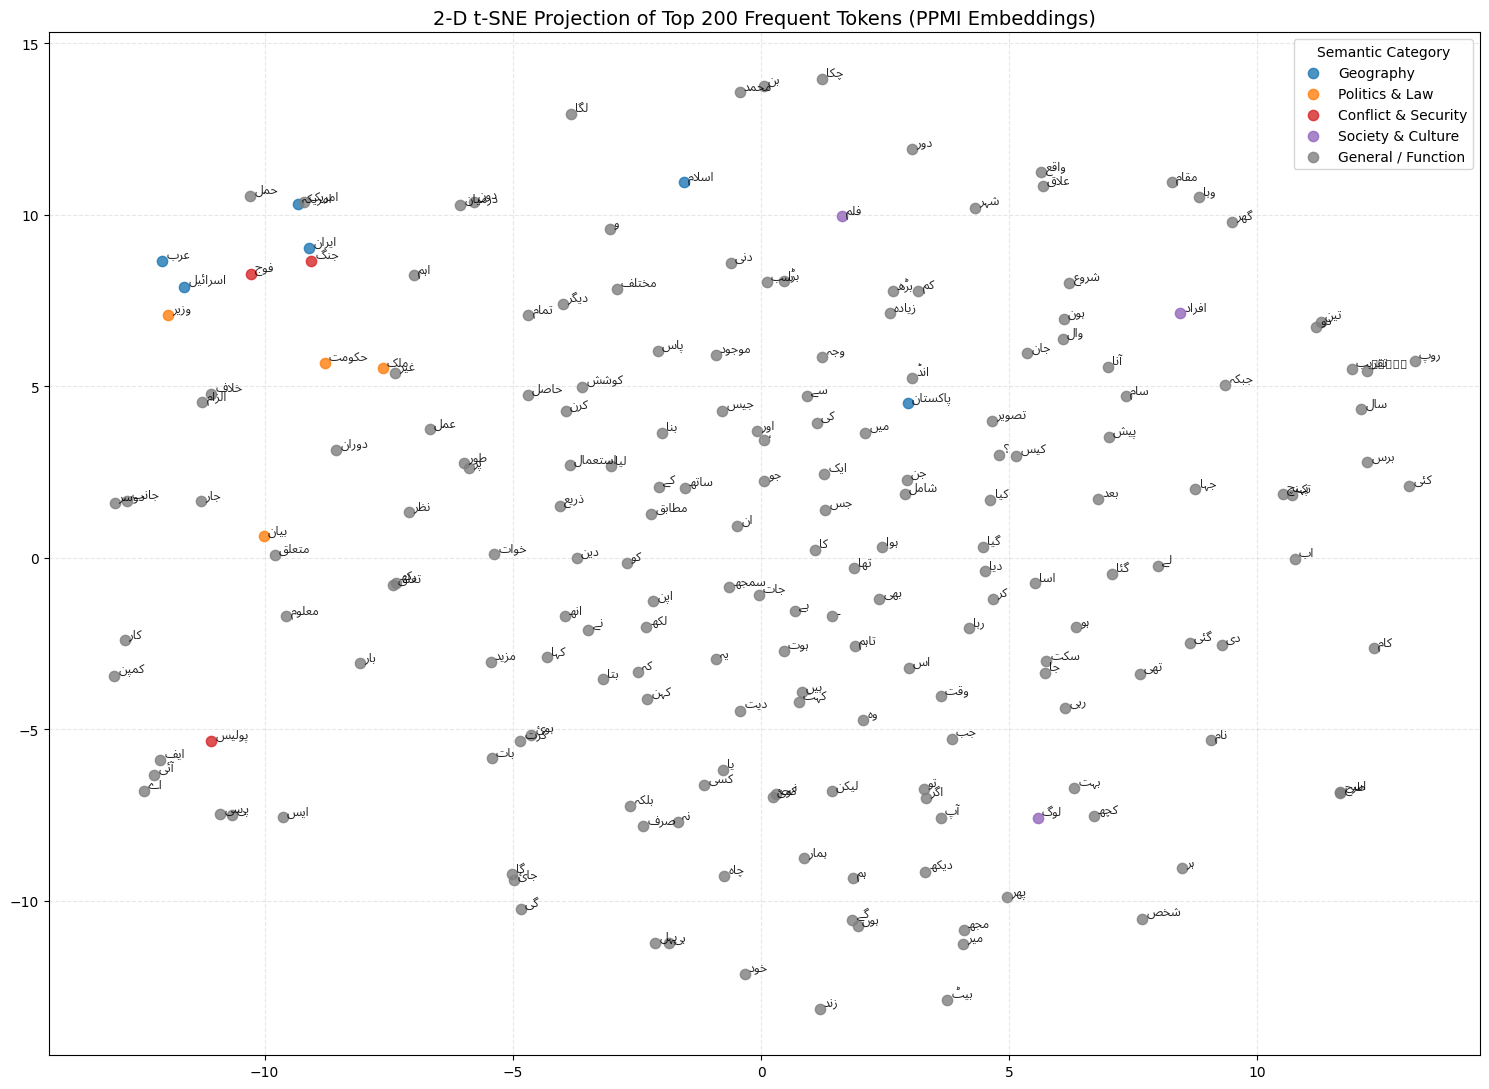


=== Top-5 Nearest Neighbors by Cosine Similarity (PPMI) ===

Query: پاکستان      -> میں (0.198), ؟ (0.186), کے (0.182), انڈ (0.175), ملک (0.160)
Query: کرکٹ         -> بورڈ (0.249), شارجہ (0.229), انڈر (0.225), میچز (0.223), کوچ (0.219)
Query: فوج          -> اسرائیل (0.176), افواج (0.176), ایران (0.172), کارروائ (0.170), کے (0.168)
Query: حکومت        -> عوام (0.153), ملک (0.151), وفاق (0.140), پیٹرولیم (0.139), اقتدار (0.138)
Query: عدالت        -> جج (0.254), کورٹ (0.205), سماعت (0.201), مقدم (0.190), سپریم (0.185)
Query: ایران        -> جنگ (0.223), امریکہ (0.211), آبنائ (0.190), امریک (0.182), تیل (0.177)
Query: فلم          -> دھورندھر (0.216), اداکار (0.207), دت (0.187), وڈ (0.182), ٹریلر (0.178)
Query: پولیس        -> اہلکار (0.229), ملزمان (0.178), سرگودھ (0.169), گرفتار (0.165), ایف (0.164)
Query: معیشت        -> کیش (0.227), سرکولیشن (0.207), ارب (0.192), روزگار (0.170), آمدن (0.159)
Query: طالبان       -> شیعہ (0.287), افغانستان (0.227), ہزارہ (0.204), افغان (0.204), کابل 

In [4]:
!pip install -q arabic-reshaper python-bidi

import urllib.request
import os
from scipy.sparse import coo_matrix
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import arabic_reshaper
from bidi.algorithm import get_display

# 1. Build Symmetric Word-Word Co-occurrence Matrix (window k = 5)
WINDOW_SIZE = 5
rows, cols = [], []

for token_ids in indexed_docs:
    L = len(token_ids)
    for i in range(L):
        w_center = token_ids[i]
        left = max(0, i - WINDOW_SIZE)
        right = min(L, i + WINDOW_SIZE + 1)
        for j in range(left, right):
            if i != j:
                rows.append(w_center)
                cols.append(token_ids[j])

data = np.ones(len(rows), dtype=np.float32)
cooc_matrix = coo_matrix((data, (rows, cols)), shape=(V, V)).toarray()

# 2. Compute PPMI Matrix
total_cooc = cooc_matrix.sum()
row_sums = cooc_matrix.sum(axis=1, keepdims=True)
col_sums = cooc_matrix.sum(axis=0, keepdims=True)
expected = (row_sums @ col_sums) / total_cooc

with np.errstate(divide="ignore", invalid="ignore"):
    pmi = np.where((cooc_matrix > 0) & (expected > 0), np.log2(cooc_matrix / expected), 0.0)

ppmi_matrix = np.maximum(0.0, pmi).astype(np.float32)
np.save("ppmi_matrix.npy", ppmi_matrix)
print(f"Saved ppmi_matrix.npy with shape {ppmi_matrix.shape} | Non-zero entries: {np.count_nonzero(ppmi_matrix):,}")

# 3. 2-D t-SNE Visualization of Top 200 Most Frequent Tokens
# Download Urdu font so matplotlib renders Arabic/Urdu script cleanly
font_path = "NotoSansArabic-Regular.ttf"
if not os.path.exists(font_path):
    urllib.request.urlretrieve(
        "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSansArabic/NotoSansArabic-Regular.ttf",
        font_path
    )
urdu_font = fm.FontProperties(fname=font_path, size=9)

def fix_urdu(text):
    return get_display(arabic_reshaper.reshape(text))

# Top 200 tokens (vocab is already sorted by frequency; index 0..199 excludes <UNK>)
TOP_K = 200
top_200_tokens = vocab[:TOP_K]
top_200_vectors = ppmi_matrix[:TOP_K]

# Semantic categorization for color-coding
LEXICON = {
    "Geography": {
        "پاکستان", "انڈیا", "امریکہ", "ایران", "اسرائیل", "برطانیہ", "افغانستان",
        "کشمیر", "لاہور", "پشاور", "کراچی", "اسلام", "آباد", "چین", "روس",
        "سعودی", "عرب", "نیپال", "فرانس", "غزہ", "فلسطین", "شام", "ترکی", "دہلی", "لندن"
    },
    "Politics & Law": {
        "حکومت", "صدر", "وزیر", "اعظم", "عدالت", "قانون", "سیاست", "ملک",
        "ریاست", "پارلیمنٹ", "اسمبلی", "انتخابات", "مقدمہ", "سزا", "جج", "وکیل", "بیان", "فیصلہ"
    },
    "Conflict & Security": {
        "فوج", "جنگ", "حملے", "حملہ", "پولیس", "سکیورٹی", "میزائل", "ڈرون",
        "ہلاک", "گرفتار", "ملزمان", "طالبان", "القاعدہ", "قتل", "جرم", "دہشت", "فائرنگ"
    },
    "Sports": {
        "کرکٹ", "ٹیم", "میچ", "ٹیسٹ", "بولر", "رنز", "وکٹیں", "کھلاڑی",
        "بابر", "انگلینڈ", "سیریز", "کپتان", "بیٹنگ", "بولنگ", "کھیل"
    },
    "Society & Culture": {
        "خواتین", "بچوں", "بچے", "مسلمان", "مذہب", "فلم", "ڈرامہ", "آرٹ",
        "تعلیم", "صحت", "ہسپتال", "لوگ", "افراد", "خاندان", "شادی", "ادب", "تاریخ", "ثقافت"
    }
}

def assign_category(word):
    for cat, word_set in LEXICON.items():
        if word in word_set:
            return cat
    return "General / Function"

categories = [assign_category(w) for w in top_200_tokens]

tsne = TSNE(n_components=2, perplexity=30, random_state=42, metric="cosine", init="pca", learning_rate="auto")
coords = tsne.fit_transform(top_200_vectors)

plt.figure(figsize=(15, 11))
palette = {
    "Geography": "#1f77b4",
    "Politics & Law": "#ff7f0e",
    "Conflict & Security": "#d62728",
    "Sports": "#2ca02c",
    "Society & Culture": "#9467bd",
    "General / Function": "#7f7f7f"
}

for cat, color in palette.items():
    idxs = [i for i, c in enumerate(categories) if c == cat]
    if idxs:
        plt.scatter(coords[idxs, 0], coords[idxs, 1], c=color, label=cat, alpha=0.8, s=55)
        for i in idxs:
            plt.annotate(
                fix_urdu(top_200_tokens[i]),
                (coords[i, 0], coords[i, 1]),
                fontproperties=urdu_font,
                alpha=0.85,
                xytext=(3, 2),
                textcoords="offset points"
            )

plt.title("2-D t-SNE Projection of Top 200 Frequent Tokens (PPMI Embeddings)", fontsize=14)
plt.legend(title="Semantic Category", loc="best")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("ppmi_tsne_top200.png", dpi=300)
plt.show()

# 4. Top-5 Nearest Neighbors by Cosine Similarity for >= 10 Query Words
norms = np.linalg.norm(ppmi_matrix, axis=1, keepdims=True)
ppmi_norm = np.divide(ppmi_matrix, norms, out=np.zeros_like(ppmi_matrix), where=norms > 0)

candidate_queries = [
    "پاکستان", "انڈیا", "کرکٹ", "فوج", "حکومت", "خواتین",
    "عدالت", "ایران", "فلم", "پولیس", "معیشت", "طالبان", "اسرائیل", "سائنس"
]
query_words = [w for w in candidate_queries if w in word2idx][:12]

print("\n=== Top-5 Nearest Neighbors by Cosine Similarity (PPMI) ===\n")
for q in query_words:
    q_idx = word2idx[q]
    sims = ppmi_norm @ ppmi_norm[q_idx]
    sims[q_idx] = -1.0   # Exclude self
    sims[unk_idx] = -1.0 # Exclude <UNK>
    top_5 = np.argsort(sims)[::-1][:5]
    neighbors_str = ", ".join([f"{idx2word[i]} ({sims[i]:.3f})" for i in top_5])
    print(f"Query: {q:<12} -> {neighbors_str}")

Using device: cpu
Vocab size: 10000 | Positive skip-gram pairs: 5,255,530
Epoch 01/15 | Batch 0200/5133 | Loss: 5.5300
Epoch 01/15 | Batch 0400/5133 | Loss: 3.5967
Epoch 01/15 | Batch 0600/5133 | Loss: 3.3709
Epoch 01/15 | Batch 0800/5133 | Loss: 3.2942
Epoch 01/15 | Batch 1000/5133 | Loss: 3.2568
Epoch 01/15 | Batch 1200/5133 | Loss: 3.2341
Epoch 01/15 | Batch 1400/5133 | Loss: 3.2219
Epoch 01/15 | Batch 1600/5133 | Loss: 3.2104
Epoch 01/15 | Batch 1800/5133 | Loss: 3.2051
Epoch 01/15 | Batch 2000/5133 | Loss: 3.1982
Epoch 01/15 | Batch 2200/5133 | Loss: 3.1911
Epoch 01/15 | Batch 2400/5133 | Loss: 3.1846
Epoch 01/15 | Batch 2600/5133 | Loss: 3.1781
Epoch 01/15 | Batch 2800/5133 | Loss: 3.1756
Epoch 01/15 | Batch 3000/5133 | Loss: 3.1712
Epoch 01/15 | Batch 3200/5133 | Loss: 3.1647
Epoch 01/15 | Batch 3400/5133 | Loss: 3.1610
Epoch 01/15 | Batch 3600/5133 | Loss: 3.1547
Epoch 01/15 | Batch 3800/5133 | Loss: 3.1509
Epoch 01/15 | Batch 4000/5133 | Loss: 3.1459
Epoch 01/15 | Batch 4200/5

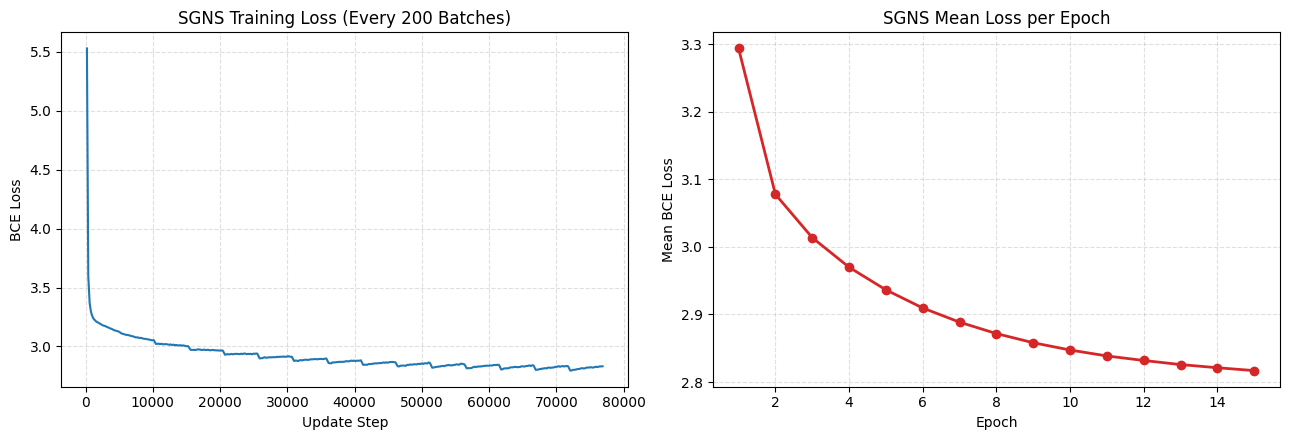

In [5]:
from collections import Counter
import json
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Reproducibility & Device
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


# 1. Load Documents & Build Vocabulary (10,000 tokens matching Part 1)
def load_corpus_docs(filepath, expected_len=None):
  with open(filepath, "r", encoding="utf-8") as f:
    raw_text = f.read().strip()
  lines = [line.strip() for line in raw_text.splitlines() if line.strip()]
  if expected_len and len(lines) == expected_len:
    return [line.split() for line in lines]
  if re.search(r"^Article\s+\d+", raw_text, flags=re.MULTILINE):
    blocks = re.split(r"^Article\s+\d+\s*", raw_text, flags=re.MULTILINE)
    return [b.strip().split() for b in blocks if b.strip()]
  return [b.strip().split() for b in raw_text.split("\n\n") if b.strip()]


with open("Metadata.json", "r", encoding="utf-8") as f:
  metadata = json.load(f)

clean_docs = load_corpus_docs("cleaned.txt", expected_len=len(metadata))


def build_vocab_and_pairs(docs, vocab_size=10000, window_size=5):
  UNK_TOKEN = "<UNK>"
  counts = Counter(tok for doc in docs for tok in doc)
  most_common = [tok for tok, _ in counts.most_common(vocab_size - 1)]
  vocab = most_common + [UNK_TOKEN]
  word2idx = {tok: idx for idx, tok in enumerate(vocab)}
  idx2word = {idx: tok for idx, tok in enumerate(vocab)}
  unk_idx = word2idx[UNK_TOKEN]

  # Token frequencies for noise distribution P(w) \propto f(w)^(3/4)
  freqs = np.zeros(len(vocab), dtype=np.float64)
  for tok, cnt in counts.items():
    if tok in word2idx:
      freqs[word2idx[tok]] = cnt
  freqs[unk_idx] = 0.0  # Exclude <UNK> from negative sampling
  noise_weights = np.power(freqs, 0.75)
  noise_probs = noise_weights / noise_weights.sum()

  # Generate positive (center, context) pairs within document boundaries
  centers, contexts = [], []
  for doc in docs:
    ids = [word2idx.get(tok, unk_idx) for tok in doc]
    # Filter out <UNK> so OOV tokens do not pollute context windows
    ids = [i for i in ids if i != unk_idx]
    L = len(ids)
    for i in range(L):
      c = ids[i]
      left = max(0, i - window_size)
      right = min(L, i + window_size + 1)
      for j in range(left, right):
        if i != j:
          centers.append(c)
          contexts.append(ids[j])

  pairs_tensor = torch.tensor(
      np.column_stack((centers, contexts)), dtype=torch.long
  )
  return vocab, word2idx, idx2word, noise_probs, pairs_tensor


vocab_clean, w2i_clean, i2w_clean, noise_probs_clean, pairs_clean = (
    build_vocab_and_pairs(clean_docs, vocab_size=10000, window_size=5)
)
print(
    f"Vocab size: {len(vocab_clean)} | Positive skip-gram pairs:"
    f" {len(pairs_clean):,}"
)


# 2. Skip-gram Negative Sampling (SGNS) Model
class SkipGramNS(nn.Module):

  def __init__(self, vocab_size, embed_dim):
    super().__init__()
    self.V = nn.Embedding(vocab_size, embed_dim)  # Centre embeddings
    self.U = nn.Embedding(vocab_size, embed_dim)  # Context embeddings
    # Small uniform initialization prevents initial sigmoid saturation
    init_range = 0.5 / embed_dim
    nn.init.uniform_(self.V.weight, -init_range, init_range)
    nn.init.zeros_(self.U.weight)

  def forward(self, center_ids, pos_ids, neg_ids):
    # center_ids: (B,), pos_ids: (B,), neg_ids: (B, K)
    v_c = self.V(center_ids)  # (B, d)
    u_o = self.U(pos_ids)  # (B, d)
    u_neg = self.U(neg_ids)  # (B, K, d)

    # L = -log \sigma(u_o^T v_c) - \sum_{i=1}^K log \sigma(-u_{w_i}^T v_c)
    pos_score = torch.sum(v_c * u_o, dim=1)  # (B,)
    pos_loss = -F.logsigmoid(pos_score)

    neg_score = torch.bmm(u_neg, v_c.unsqueeze(2)).squeeze(2)  # (B, K)
    neg_loss = -F.logsigmoid(-neg_score).sum(dim=1)  # (B,)

    return (pos_loss + neg_loss).mean()


def train_sgns(
    pairs_tensor,
    noise_probs,
    vocab_size=10000,
    embed_dim=100,
    num_neg=10,
    batch_size=1024,
    epochs=15,
    lr=0.001,
    log_interval=200,
    verbose=True,
):
  model = SkipGramNS(vocab_size, embed_dim).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)
  loader = DataLoader(
      TensorDataset(pairs_tensor), batch_size=batch_size, shuffle=True
  )
  noise_dist = torch.tensor(noise_probs, dtype=torch.float, device=device)

  step_losses = []
  epoch_losses = []
  global_step = 0

  model.train()
  for epoch in range(1, epochs + 1):
    running_loss = 0.0
    interval_loss = 0.0
    for batch_idx, (batch_pairs,) in enumerate(loader, start=1):
      batch_pairs = batch_pairs.to(device)
      c_ids = batch_pairs[:, 0]
      o_ids = batch_pairs[:, 1]
      B = c_ids.size(0)

      # Sample K negative words per positive pair from P(w) \propto f(w)^(3/4)
      neg_ids = torch.multinomial(
          noise_dist, B * num_neg, replacement=True
      ).view(B, num_neg)

      optimizer.zero_grad()
      loss = model(c_ids, o_ids, neg_ids)
      loss.backward()
      optimizer.step()

      loss_val = loss.item()
      running_loss += loss_val
      interval_loss += loss_val
      global_step += 1

      if batch_idx % log_interval == 0:
        avg_int = interval_loss / log_interval
        step_losses.append((global_step, avg_int))
        if verbose:
          print(
              f"Epoch {epoch:02d}/{epochs:02d} | Batch"
              f" {batch_idx:04d}/{len(loader):04d} | Loss: {avg_int:.4f}"
          )
        interval_loss = 0.0

    avg_ep = running_loss / len(loader)
    epoch_losses.append(avg_ep)
    if verbose:
      print(f"--> Epoch {epoch:02d} Mean Loss: {avg_ep:.4f}")

  # Averaged final embeddings: 0.5 * (V + U)
  with torch.no_grad():
    embeddings = (
        0.5 * (model.V.weight + model.U.weight).cpu().numpy().astype(np.float32)
    )
  return embeddings, step_losses, epoch_losses


# 3. Train Required Model (d=100, k=5, K=10, lr=0.001, batch_size=1024, epochs=15)
embeddings_w2v, step_losses, epoch_losses = train_sgns(
    pairs_clean,
    noise_probs_clean,
    vocab_size=10000,
    embed_dim=100,
    num_neg=10,
    batch_size=1024,
    epochs=15,
    lr=0.001,
    log_interval=200,
    verbose=True,
)

np.save("embeddings_w2v.npy", embeddings_w2v)
print(f"\nSaved embeddings_w2v.npy with shape {embeddings_w2v.shape}")

# 4. Plot Training Loss Curve
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
steps, s_vals = zip(*step_losses)
axes[0].plot(steps, s_vals, color="#1f77b4", linewidth=1.5)
axes[0].set_title("SGNS Training Loss (Every 200 Batches)")
axes[0].set_xlabel("Update Step")
axes[0].set_ylabel("BCE Loss")
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].plot(
    range(1, len(epoch_losses) + 1),
    epoch_losses,
    marker="o",
    color="#d62728",
    linewidth=2,
)
axes[1].set_title("SGNS Mean Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean BCE Loss")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("w2v_loss_curve.png", dpi=300)
plt.show()

In [6]:
def l2_normalize(mat):
  norms = np.linalg.norm(mat, axis=1, keepdims=True)
  return np.divide(mat, norms, out=np.zeros_like(mat), where=norms > 0)


emb_norm = l2_normalize(embeddings_w2v)
unk_idx_clean = w2i_clean["<UNK>"]

# 1. Top-10 Nearest Neighbours for the 8 Required Query Words
target_queries = [
    ("Pakistan", "پاکستان"),
    ("Hukumat", "حکومت"),
    ("Adalat", "عدالت"),
    ("Maeeshat", "معیشت"),
    ("Fauj", "فوج"),
    ("Sehat", "صحت"),
    ("Taleem", "تعلیم"),
    ("Aabadi", "آبادی"),
]

print(
    "=== Top-10 Nearest Neighbours (Skip-gram on cleaned.txt, d=100) ===\n"
)
for label, word in target_queries:
  if word not in w2i_clean:
    print(f"{label} ({word}): [OOV - not in top 10,000 vocabulary]")
    continue
  q_idx = w2i_clean[word]
  sims = emb_norm @ emb_norm[q_idx]
  sims[q_idx] = -np.inf
  sims[unk_idx_clean] = -np.inf
  top10 = np.argsort(sims)[::-1][:10]
  nn_str = ", ".join([f"{i2w_clean[i]} ({sims[i]:.3f})" for i in top10])
  print(f"{label:<10} ({word}): {nn_str}\n")

# 2. Construct & Evaluate 10 Vector Analogy Tests: a : b :: c : ?  =>  v(b) - v(a) + v(c)
candidate_analogies = [
    # (a, b, c, expected_d, relation_type)
    ("پاکستان", "لاہور", "انڈیا", "دہلی", "Country : Major City"),
    ("پاکستان", "کراچی", "برطانیہ", "لندن", "Country : Major City"),
    ("امریکہ", "واشنگٹن", "روس", "ماسکو", "Country : Capital"),
    ("ایران", "تہران", "افغانستان", "کابل", "Country : Capital"),
    ("چین", "بیجنگ", "فرانس", "پیرس", "Country : Capital"),
    ("پاکستان", "روپے", "امریکہ", "ڈالر", "Country : Currency"),
    ("مرد", "عورت", "لڑکا", "لڑکی", "Gender (Noun)"),
    ("باپ", "ماں", "بیٹا", "بیٹی", "Gender (Family)"),
    ("عدالت", "جج", "ہسپتال", "ڈاکٹر", "Institution : Professional"),
    ("حکومت", "وزیر", "فوج", "جنرل", "Institution : Leader"),
    ("پاکستان", "پاکستانی", "انڈیا", "انڈین", "Country : Demonym"),
    ("دن", "رات", "سردی", "گرمی", "Antonyms"),
    ("پولیس", "ملزم", "عدالت", "سزا", "Legal Process"),
]

# Select first 10 analogies where all 4 tokens exist in the 10k vocabulary
valid_analogies = [
    item
    for item in candidate_analogies
    if all(tok in w2i_clean for tok in item[:4])
][:10]

print(f"=== Vector Analogy Evaluation ({len(valid_analogies)} Tests) ===\n")
hits_top1 = 0
hits_top3 = 0

for idx, (a, b, c, expected, rel) in enumerate(valid_analogies, start=1):
  ia, ib, ic = w2i_clean[a], w2i_clean[b], w2i_clean[c]
  target_vec = emb_norm[ib] - emb_norm[ia] + emb_norm[ic]
  target_vec = target_vec / (np.linalg.norm(target_vec) + 1e-12)

  sims = emb_norm @ target_vec
  # Exclude a, b, c, and <UNK> per standard analogy protocol
  sims[[ia, ib, ic, unk_idx_clean]] = -np.inf
  top3_ids = np.argsort(sims)[::-1][:3]
  top3_words = [i2w_clean[i] for i in top3_ids]

  is_top1 = top3_words[0] == expected
  is_top3 = expected in top3_words
  hits_top1 += int(is_top1)
  hits_top3 += int(is_top3)

  status = "PASS (Top-1)" if is_top1 else ("PASS (Top-3)" if is_top3 else "MISS")
  top3_fmt = ", ".join(
      [f"{i2w_clean[i]} ({sims[i]:.3f})" for i in top3_ids]
  )
  print(
      f"Test {idx:02d} [{rel}]: {a} : {b} :: {c} : ? (Expected: {expected})"
  )
  print(f"   Top-3: {top3_fmt}  --> [{status}]")

print(
    f"\nSummary -> Top-1 Accuracy: {hits_top1}/{len(valid_analogies)} | Top-3"
    f" Accuracy: {hits_top3}/{len(valid_analogies)}"
)

=== Top-10 Nearest Neighbours (Skip-gram on cleaned.txt, d=100) ===

Pakistan   (پاکستان): کنووینر (0.554), بروکریج (0.553), الائنس (0.550), بیٹرز (0.537), کثیرالثقاف (0.536), چیمبرز (0.531), آئیڈل (0.525), افتخار (0.525), ہنگور (0.523), شکس (0.520)

Hukumat    (حکومت): ڈیفالٹ (0.617), پراخ (0.599), پیٹرولیم (0.582), فرینکلن (0.556), ایویٹ (0.555), وفاق (0.547), آڑا (0.532), سلیبز (0.530), عدلیہ (0.529), زرمبادلہ (0.526)

Adalat     (عدالت): جج (0.595), حنظلہ (0.593), کورٹ (0.590), لکھپت (0.567), استدع (0.565), چدھڑ (0.549), جھکائ (0.548), مقدم (0.534), اپیلز (0.532), سماعت (0.531)

Maeeshat   (معیشت): اقتصاد (0.634), معاش (0.592), کیش (0.577), سرکولیشن (0.567), اعشار (0.554), زرمبادلہ (0.547), ٹپائ (0.546), آمدن (0.533), خوشحال (0.525), کمی (0.525)

Fauj       (فوج): افواج (0.645), ایال (0.617), گردونواح (0.606), رینک (0.588), زمیر (0.588), روزنامچ (0.577), پریڈ (0.573), برسلز (0.570), نےاقوام (0.529), پراخچ (0.526)

Sehat      (صحت): حفظان (0.585), بیمار (0.582), یاب (0.552), پھیپھڑ 

In [7]:
from scipy.sparse import coo_matrix

# 1. Prepare C1 (PPMI baseline on cleaned.txt, k=5)
if os.path.exists("ppmi_matrix.npy"):
  ppmi_c1 = np.load("ppmi_matrix.npy")
else:
  # Fallback build if runtime restarted
  V = len(vocab_clean)
  rows, cols = [], []
  for doc in clean_docs:
    ids = [w2i_clean.get(t, unk_idx_clean) for t in doc]
    for i in range(len(ids)):
      for j in range(max(0, i - 5), min(len(ids), i + 6)):
        if i != j:
          rows.append(ids[i])
          cols.append(ids[j])
  cooc = coo_matrix(
      (np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(V, V)
  ).toarray()
  expected = (cooc.sum(axis=1, keepdims=True) @ cooc.sum(axis=0, keepdims=True)) / cooc.sum()
  with np.errstate(divide="ignore", invalid="ignore"):
    pmi = np.where((cooc > 0) & (expected > 0), np.log2(cooc / expected), 0.0)
  ppmi_c1 = np.maximum(0.0, pmi).astype(np.float32)

# 2. Train C2: Skip-gram on raw.txt (unprocessed corpus, d=100)
raw_docs = load_corpus_docs("raw.txt", expected_len=len(metadata))
vocab_raw, w2i_raw, i2w_raw, noise_probs_raw, pairs_raw = build_vocab_and_pairs(
    raw_docs, vocab_size=10000, window_size=5
)
print(
    f"Training C2 (Skip-gram on raw.txt, d=100) | Pairs: {len(pairs_raw):,}..."
)
emb_c2, _, _ = train_sgns(
    pairs_raw,
    noise_probs_raw,
    vocab_size=10000,
    embed_dim=100,
    num_neg=10,
    batch_size=1024,
    epochs=15,
    lr=0.001,
    verbose=False,
)

# 3. C3: Skip-gram on cleaned.txt, d=100 (already trained in Cell 1)
emb_c3 = embeddings_w2v

# 4. Train C4: Skip-gram on cleaned.txt, d=200
print(
    f"Training C4 (Skip-gram on cleaned.txt, d=200) |"
    f" Pairs: {len(pairs_clean):,}..."
)
emb_c4, _, _ = train_sgns(
    pairs_clean,
    noise_probs_clean,
    vocab_size=10000,
    embed_dim=200,
    num_neg=10,
    batch_size=1024,
    epochs=15,
    lr=0.001,
    verbose=False,
)

conditions = {
    "C1 (PPMI baseline)": (l2_normalize(ppmi_c1), w2i_clean, i2w_clean),
    "C2 (Skip-gram raw.txt, d=100)": (l2_normalize(emb_c2), w2i_raw, i2w_raw),
    "C3 (Skip-gram cleaned.txt, d=100)": (
        l2_normalize(emb_c3),
        w2i_clean,
        i2w_clean,
    ),
    "C4 (Skip-gram cleaned.txt, d=200)": (
        l2_normalize(emb_c4),
        w2i_clean,
        i2w_clean,
    ),
}

# 5. Report Top-5 Neighbours for 5 Query Words Across All Conditions
comp_queries = ["پاکستان", "حکومت", "عدالت", "فوج", "تعلیم"]

print("\n=== Top-5 Nearest Neighbours Across Conditions C1–C4 ===")
for q in comp_queries:
  print(f"\nQuery: {q}")
  for cond_name, (mat, w2i, i2w) in conditions.items():
    if q not in w2i:
      print(f"  {cond_name:<35}: [OOV]")
      continue
    q_idx = w2i[q]
    sims = mat @ mat[q_idx]
    sims[q_idx] = -np.inf
    sims[w2i["<UNK>"]] = -np.inf
    top5 = np.argsort(sims)[::-1][:5]
    nn_str = ", ".join([f"{i2w[i]} ({sims[i]:.3f})" for i in top5])
    print(f"  {cond_name:<35}: {nn_str}")

# 6. Evaluate MRR on 20 Manually Labelled Semantic Word Pairs
candidate_pairs = [
    ("پاکستان", "انڈیا"),
    ("حکومت", "وزیر"),
    ("عدالت", "جج"),
    ("فوج", "سکیورٹی"),
    ("پولیس", "گرفتار"),
    ("کرکٹ", "میچ"),
    ("کھلاڑی", "ٹیم"),
    ("خواتین", "بچوں"),
    ("تعلیم", "طلبہ"),
    ("صحت", "ہسپتال"),
    ("ڈاکٹر", "مریض"),
    ("امریکہ", "صدر"),
    ("ایران", "اسرائیل"),
    ("طالبان", "افغانستان"),
    ("قانون", "آئین"),
    ("انتخابات", "ووٹ"),
    ("فلم", "ڈرامہ"),
    ("معیشت", "کاروبار"),
    ("لاہور", "کراچی"),
    ("قتل", "ملزم"),
    ("جنگ", "حملے"),
    ("سائنس", "تحقیق"),
    ("بارش", "موسم"),
    ("شادی", "خاندان"),
]

# Keep 20 pairs where both words exist in BOTH cleaned and raw vocabularies for fair comparison
eval_pairs_20 = [
    (w1, w2)
    for (w1, w2) in candidate_pairs
    if (w1 in w2i_clean and w2 in w2i_clean and w1 in w2i_raw and w2 in w2i_raw)
][:20]

assert (
    len(eval_pairs_20) == 20
), f"Found {len(eval_pairs_20)} shared pairs; add more common Urdu pairs."


def compute_mrr(mat, w2i, pairs):
  unk_id = w2i["<UNK>"]
  reciprocal_ranks = []
  pair_details = []
  for w1, w2 in pairs:
    i1, i2 = w2i[w1], w2i[w2]
    sims = mat @ mat[i1]
    sims[i1] = -np.inf
    sims[unk_id] = -np.inf
    ranked = np.argsort(sims)[::-1]
    rank = int(np.where(ranked == i2)[0][0]) + 1
    rr = 1.0 / rank
    reciprocal_ranks.append(rr)
    pair_details.append((w1, w2, rank, rr))
  return float(np.mean(reciprocal_ranks)), pair_details


print(f"\n=== Mean Reciprocal Rank (MRR) on {len(eval_pairs_20)} Word Pairs ===")
for cond_name, (mat, w2i, _) in conditions.items():
  mrr_score, details = compute_mrr(mat, w2i, eval_pairs_20)
  top10_hits = sum(1 for _, _, r, _ in details if r <= 10)
  print(
      f"{cond_name:<35} | MRR: {mrr_score:.4f} | Pairs in Top-10:"
      f" {top10_hits}/20"
  )

Training C2 (Skip-gram on raw.txt, d=100) | Pairs: 4,866,750...
Training C4 (Skip-gram on cleaned.txt, d=200) | Pairs: 5,255,530...

=== Top-5 Nearest Neighbours Across Conditions C1–C4 ===

Query: پاکستان
  C1 (PPMI baseline)                 : میں (0.198), ؟ (0.186), کے (0.182), انڈ (0.175), ملک (0.160)
  C2 (Skip-gram raw.txt, d=100)      : خاندان‘: (0.543), زیرانتظام (0.532), آئیڈل (0.520), قیمتیں: (0.505), ٹاس (0.488)
  C3 (Skip-gram cleaned.txt, d=100)  : کنووینر (0.554), بروکریج (0.553), الائنس (0.550), بیٹرز (0.537), کثیرالثقاف (0.536)
  C4 (Skip-gram cleaned.txt, d=200)  : شکس (0.531), کثیرالثقاف (0.529), لہرائ (0.503), کنووینر (0.498), پاپولیشن (0.487)

Query: حکومت
  C1 (PPMI baseline)                 : عوام (0.153), ملک (0.151), وفاق (0.140), پیٹرولیم (0.139), اقتدار (0.138)
  C2 (Skip-gram raw.txt, d=100)      : پیٹرولیم (0.597), ریاستِ (0.564), بشار (0.553), عدلیہ (0.534), سلیبز (0.534)
  C3 (Skip-gram cleaned.txt, d=100)  : ڈیفالٹ (0.617), پراخ (0.599), پیٹرولیم (0.582), 

AssertionError: Found 16 shared pairs; add more common Urdu pairs.

In [8]:
import os
import numpy as np

# Uses `conditions`, `w2i_clean`, `w2i_raw` already in memory (no retraining required)


def resolve_word(word, w2i):
  """Matches exact token first; falls back to stemmed prefix (len >= 3) for cleaned.txt."""
  if word in w2i:
    return word
  for trim in range(1, min(4, len(word) - 2)):
    stem = word[:-trim]
    if stem in w2i:
      return stem
  return None


extended_candidate_pairs = [
    ("پاکستان", "ملک"),
    ("پاکستان", "انڈیا"),
    ("حکومت", "وزیر"),
    ("حکومت", "وفاق"),
    ("عدالت", "جج"),
    ("عدالت", "کورٹ"),
    ("عدالت", "سماعت"),
    ("فوج", "افواج"),
    ("فوج", "فوجی"),
    ("فوج", "سکیورٹی"),
    ("پولیس", "گرفتار"),
    ("پولیس", "ملزم"),
    ("کرکٹ", "میچ"),
    ("کھلاڑی", "ٹیم"),
    ("خواتین", "بچوں"),
    ("تعلیم", "طلبہ"),
    ("تعلیم", "سکول"),
    ("تعلیم", "یونیورسٹی"),
    ("صحت", "ہسپتال"),
    ("ڈاکٹر", "مریض"),
    ("امریکہ", "صدر"),
    ("ایران", "اسرائیل"),
    ("طالبان", "افغانستان"),
    ("قانون", "آئین"),
    ("انتخابات", "ووٹ"),
    ("فلم", "ڈرامہ"),
    ("معیشت", "کاروبار"),
    ("لاہور", "کراچی"),
    ("اسلام", "آباد"),
    ("قتل", "مقدمہ"),
    ("جنگ", "حملے"),
    ("سائنس", "تحقیق"),
    ("بارش", "موسم"),
    ("شادی", "خاندان"),
    ("وزیر", "اعظم"),
    ("سپریم", "کورٹ"),
]

eval_pairs_20 = []
seen_pairs = set()

for w1, w2 in extended_candidate_pairs:
  c_w1, c_w2 = resolve_word(w1, w2i_clean), resolve_word(w2, w2i_clean)
  r_w1, r_w2 = resolve_word(w1, w2i_raw), resolve_word(w2, w2i_raw)
  if all([c_w1, c_w2, r_w1, r_w2]) and c_w1 != c_w2 and r_w1 != r_w2:
    if (w1, w2) not in seen_pairs:
      seen_pairs.add((w1, w2))
      eval_pairs_20.append({
          "label": f"{w1} -> {w2}",
          "clean": (c_w1, c_w2),
          "raw": (r_w1, r_w2),
      })
  if len(eval_pairs_20) == 20:
    break

print(f"Selected {len(eval_pairs_20)} shared evaluation pairs:")
for idx, p in enumerate(eval_pairs_20, 1):
  print(
      f"  {idx:02d}. {p['label']:<22} (clean: {p['clean'][0]} ->"
      f" {p['clean'][1]} | raw: {p['raw'][0]} -> {p['raw'][1]})"
  )


def compute_mrr_resolved(mat, w2i, pairs, space_key):
  unk_id = w2i["<UNK>"]
  reciprocal_ranks = []
  details = []
  for p in pairs:
    w1, w2 = p[space_key]
    i1, i2 = w2i[w1], w2i[w2]
    sims = mat @ mat[i1]
    sims[i1] = -np.inf
    sims[unk_id] = -np.inf
    ranked = np.argsort(sims)[::-1]
    rank = int(np.where(ranked == i2)[0][0]) + 1
    rr = 1.0 / rank
    reciprocal_ranks.append(rr)
    details.append((p["label"], rank, rr))
  return float(np.mean(reciprocal_ranks)), details


print(
    f"\n=== Mean Reciprocal Rank (MRR) on {len(eval_pairs_20)} Labelled Word"
    " Pairs ===\n"
)
summary_lines = []
for cond_name, (mat, w2i, _) in conditions.items():
  key = "raw" if "raw.txt" in cond_name else "clean"
  mrr_score, details = compute_mrr_resolved(mat, w2i, eval_pairs_20, key)
  top10_hits = sum(1 for _, r, _ in details if r <= 10)
  top50_hits = sum(1 for _, r, _ in details if r <= 50)
  line = (
      f"{cond_name:<35} | MRR: {mrr_score:.4f} | Top-10: {top10_hits:02d}/20 |"
      f" Top-50: {top50_hits:02d}/20"
  )
  print(line)
  summary_lines.append(line)

drive_dir = "/content/drive/MyDrive/DS5007_Assignment2"
if os.path.exists(drive_dir):
  out_path = os.path.join(drive_dir, "mrr_comparison_results.txt")
  with open(out_path, "w", encoding="utf-8") as f:
    f.write("\n".join(summary_lines))
  print(f"\nSaved MRR table to {out_path}")

Selected 20 shared evaluation pairs:
  01. پاکستان -> ملک         (clean: پاکستان -> ملک | raw: پاکستان -> ملک)
  02. پاکستان -> انڈیا       (clean: پاکستان -> انڈ | raw: پاکستان -> انڈیا)
  03. حکومت -> وزیر          (clean: حکومت -> وزیر | raw: حکومت -> وزیر)
  04. حکومت -> وفاق          (clean: حکومت -> وفاق | raw: حکومت -> وفاق)
  05. عدالت -> جج            (clean: عدالت -> جج | raw: عدالت -> جج)
  06. عدالت -> کورٹ          (clean: عدالت -> کورٹ | raw: عدالت -> کورٹ)
  07. عدالت -> سماعت         (clean: عدالت -> سماعت | raw: عدالت -> سماعت)
  08. فوج -> افواج           (clean: فوج -> افواج | raw: فوج -> افواج)
  09. فوج -> سکیورٹی         (clean: فوج -> سکیورٹ | raw: فوج -> سکیورٹی)
  10. پولیس -> گرفتار        (clean: پولیس -> گرفتار | raw: پولیس -> گرفتار)
  11. پولیس -> ملزم          (clean: پولیس -> ملزم | raw: پولیس -> ملزم)
  12. کرکٹ -> میچ            (clean: کرکٹ -> میچ | raw: کرکٹ -> میچ)
  13. کھلاڑی -> ٹیم          (clean: کھلاڑ -> ٹیم | raw: کھلاڑی -> ٹیم)
  14. تعلیم 

In [9]:
import json
import os
import shutil
from google.colab import drive
import numpy as np

# 1. Mount Google Drive
drive.mount("/content/drive", force_remount=False)
DRIVE_DIR = "/content/drive/MyDrive/DS5007_Assignment2"
os.makedirs(DRIVE_DIR, exist_ok=True)


def save_array(arr, filename):
  local_path = filename
  np.save(local_path, arr)
  drive_path = os.path.join(DRIVE_DIR, filename)
  shutil.copy2(local_path, drive_path)
  print(
      f"[SAVED ARRAY] {filename:<30} | shape={str(arr.shape):<16} |"
      f" {os.path.getsize(drive_path)/(1024*1024):.2f} MB"
  )


def copy_if_exists(filename):
  if os.path.exists(filename):
    drive_path = os.path.join(DRIVE_DIR, os.path.basename(filename))
    shutil.copy2(filename, drive_path)
    print(
        f"[SAVED FILE ] {os.path.basename(filename):<30} |"
        f" {os.path.getsize(drive_path)/(1024*1024):.2f} MB"
    )


# 2. Save All Matrices & Trained Embeddings (Part 1 + Part 2 C1–C4)
if "tfidf_matrix" in globals():
  save_array(tfidf_matrix, "tfidf_matrix.npy")
else:
  copy_if_exists("tfidf_matrix.npy")

if "ppmi_c1" in globals():
  save_array(ppmi_c1, "ppmi_matrix.npy")
elif "ppmi_matrix" in globals():
  save_array(ppmi_matrix, "ppmi_matrix.npy")
else:
  copy_if_exists("ppmi_matrix.npy")

c3_arr = globals().get("emb_c3", globals().get("embeddings_w2v", None))
if c3_arr is not None:
  save_array(c3_arr, "embeddings_w2v.npy")  # C3: Skip-gram cleaned.txt, d=100
else:
  copy_if_exists("embeddings_w2v.npy")

if "emb_c2" in globals():
  save_array(
      emb_c2, "embeddings_c2_raw_d100.npy"
  )  # C2: Skip-gram raw.txt, d=100

if "emb_c4" in globals():
  save_array(
      emb_c4, "embeddings_c4_clean_d200.npy"
  )  # C4: Skip-gram cleaned.txt, d=200

# 3. Save Vocabularies & Evaluation Pairs
if "vocab_clean" in globals():
  with open("vocab_clean.json", "w", encoding="utf-8") as f:
    json.dump(vocab_clean, f, ensure_ascii=False)
  copy_if_exists("vocab_clean.json")

if "vocab_raw" in globals():
  with open("vocab_raw.json", "w", encoding="utf-8") as f:
    json.dump(vocab_raw, f, ensure_ascii=False)
  copy_if_exists("vocab_raw.json")

if "eval_pairs_20" in globals():
  with open("eval_pairs_20.json", "w", encoding="utf-8") as f:
    json.dump(eval_pairs_20, f, ensure_ascii=False, indent=2)
  copy_if_exists("eval_pairs_20.json")

# 4. Copy Dataset Files & Plots
for fname in [
    "cleaned.txt",
    "raw.txt",
    "Metadata.json",
    "ppmi_tsne_top200.png",
    "w2v_loss_curve.png",
]:
  copy_if_exists(fname)

# 5. Export Complete Part 2 Console Results (Neighbours, Analogies, MRR) to Text File in Drive
if c3_arr is not None and "w2i_clean" in globals():

  def l2_norm(m):
    n = np.linalg.norm(m, axis=1, keepdims=True)
    return np.divide(m, n, out=np.zeros_like(m), where=n > 0)

  emb_norm = l2_norm(c3_arr)
  unk_c = w2i_clean["<UNK>"]
  lines = ["=== PART 2 COMPLETE EVALUATION REPORT ===\n"]

  # 2.2a Top-10 Neighbours
  lines.append("--- 2.2a Top-10 Nearest Neighbours (cleaned.txt, d=100) ---")
  for label, w in [
      ("Pakistan", "پاکستان"),
      ("Hukumat", "حکومت"),
      ("Adalat", "عدالت"),
      ("Maeeshat", "معیشت"),
      ("Fauj", "فوج"),
      ("Sehat", "صحت"),
      ("Taleem", "تعلیم"),
      ("Aabadi", "آبادی"),
  ]:
    if w in w2i_clean:
      qi = w2i_clean[w]
      sims = emb_norm @ emb_norm[qi]
      sims[[qi, unk_c]] = -np.inf
      top10 = np.argsort(sims)[::-1][:10]
      lines.append(
          f"{label:<10} ({w}): "
          + ", ".join(f"{i2w_clean[i]} ({sims[i]:.3f})" for i in top10)
      )

  # 2.2a Analogies
  lines.append("\n--- 2.2a 10 Vector Analogies ---")
  candidate_analogies = [
      ("پاکستان", "لاہور", "انڈیا", "دہلی", "Country : Major City"),
      ("پاکستان", "کراچی", "برطانیہ", "لندن", "Country : Major City"),
      ("امریکہ", "واشنگٹن", "روس", "ماسکو", "Country : Capital"),
      ("ایران", "تہران", "افغانستان", "کابل", "Country : Capital"),
      ("چین", "بیجنگ", "فرانس", "پیرس", "Country : Capital"),
      ("پاکستان", "روپے", "امریکہ", "ڈالر", "Country : Currency"),
      ("مرد", "عورت", "لڑکا", "لڑکی", "Gender (Noun)"),
      ("باپ", "ماں", "بیٹا", "بیٹی", "Gender (Family)"),
      ("عدالت", "جج", "ہسپتال", "ڈاکٹر", "Institution : Professional"),
      ("حکومت", "وزیر", "فوج", "جنرل", "Institution : Leader"),
      ("پاکستان", "پاکستانی", "انڈیا", "انڈین", "Country : Demonym"),
      ("دن", "رات", "سردی", "گرمی", "Antonyms"),
      ("پولیس", "ملزم", "عدالت", "سزا", "Legal Process"),
  ]
  valid_analogies = [
      item
      for item in candidate_analogies
      if all(t in w2i_clean for t in item[:4])
  ][:10]
  for idx, (a, b, c, exp, rel) in enumerate(valid_analogies, 1):
    ia, ib, ic = w2i_clean[a], w2i_clean[b], w2i_clean[c]
    vec = emb_norm[ib] - emb_norm[ia] + emb_norm[ic]
    vec /= np.linalg.norm(vec) + 1e-12
    sims = emb_norm @ vec
    sims[[ia, ib, ic, unk_c]] = -np.inf
    top3 = np.argsort(sims)[::-1][:3]
    top3_w = [i2w_clean[i] for i in top3]
    status = "PASS" if exp in top3_w else "MISS"
    lines.append(
        f"Test {idx:02d} [{rel}]: {a}:{b} :: {c}:? (Expected: {exp}) -> Top-3:"
        f" {', '.join(top3_w)} [{status}]"
    )

  # 2.2b MRR Summary
  if "summary_lines" in globals():
    lines.append("\n--- 2.2b Four-Condition MRR Table ---")
    lines.extend(summary_lines)

  with open("part2_complete_outputs.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))
  copy_if_exists("part2_complete_outputs.txt")

print("\n=== VERIFIED CONTENTS OF GOOGLE DRIVE FOLDER ===")
for f in sorted(os.listdir(DRIVE_DIR)):
  full = os.path.join(DRIVE_DIR, f)
  if os.path.isfile(full):
    print(f"  - {f:<32} ({os.path.getsize(full)/(1024*1024):.2f} MB)")

Mounted at /content/drive
[SAVED ARRAY] tfidf_matrix.npy               | shape=(10000, 280)     | 10.68 MB
[SAVED ARRAY] ppmi_matrix.npy                | shape=(10000, 10000)   | 381.47 MB
[SAVED ARRAY] embeddings_w2v.npy             | shape=(10000, 100)     | 3.81 MB
[SAVED ARRAY] embeddings_c2_raw_d100.npy     | shape=(10000, 100)     | 3.81 MB
[SAVED ARRAY] embeddings_c4_clean_d200.npy   | shape=(10000, 200)     | 7.63 MB
[SAVED FILE ] vocab_clean.json               | 0.13 MB
[SAVED FILE ] vocab_raw.json                 | 0.13 MB
[SAVED FILE ] eval_pairs_20.json             | 0.00 MB
[SAVED FILE ] cleaned.txt                    | 3.73 MB
[SAVED FILE ] raw.txt                        | 4.08 MB
[SAVED FILE ] Metadata.json                  | 0.15 MB
[SAVED FILE ] ppmi_tsne_top200.png           | 0.78 MB
[SAVED FILE ] w2v_loss_curve.png             | 0.19 MB
[SAVED FILE ] part2_complete_outputs.txt     | 0.00 MB

=== VERIFIED CONTENTS OF GOOGLE DRIVE FOLDER ===
  - Metadata.json         

In [10]:
from collections import Counter, defaultdict
import json
import os
import random
import re
import shutil
from google.colab import drive
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Mount Google Drive & Load Artifacts
drive.mount("/content/drive", force_remount=False)
DRIVE_DIR = "/content/drive/MyDrive/DS5007_Assignment2"
os.makedirs(DRIVE_DIR, exist_ok=True)


def get_file(filename):
  if os.path.exists(filename):
    return filename
  dpath = os.path.join(DRIVE_DIR, filename)
  if os.path.exists(dpath):
    shutil.copy2(dpath, filename)
    return filename
  raise FileNotFoundError(
      f"{filename} not found locally or in Google Drive ({DRIVE_DIR})"
  )


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

with open(get_file("Metadata.json"), "r", encoding="utf-8") as f:
  metadata = json.load(f)

with open(get_file("cleaned.txt"), "r", encoding="utf-8") as f:
  raw_clean = f.read().strip()

lines = [line.strip() for line in raw_clean.splitlines() if line.strip()]
if len(lines) == len(metadata):
  documents = lines
elif re.search(r"^Article\s+\d+", raw_clean, flags=re.MULTILINE):
  documents = [
      b.strip()
      for b in re.split(r"^Article\s+\d+\s*", raw_clean, flags=re.MULTILINE)
      if b.strip()
  ]
else:
  documents = [b.strip() for b in raw_clean.split("\n\n") if b.strip()]

assert len(documents) == len(
    metadata
), f"Doc count ({len(documents)}) != Metadata ({len(metadata)})"

# 2. Extract Sentences & Select 500 Sentences (>= 100 from each of 3 distinct topics)
# Group documents by primary 'section' in Metadata.json
topic_to_docs = defaultdict(list)
for doc_text, meta in zip(documents, metadata):
  sec = meta.get("section", "Unknown").strip()
  if not sec or sec == "Unknown":
    topics_list = meta.get("topics", [])
    sec = topics_list[0].strip() if topics_list else "General"
  topic_to_docs[sec].append(doc_text)

# Pick top 3 distinct topic categories with the richest document pools
top3_topics = [
    t
    for t, _ in sorted(
        topic_to_docs.items(), key=lambda x: len(x[1]), reverse=True
    )[:3]
]
print(f"Selected 3 distinct topic categories: {top3_topics}")


def extract_sentences_from_doc(doc_text):
  """Splits document into realistic sentences while keeping punctuation tokens."""
  # Separate Urdu/English punctuation so they form distinct PUNC tokens
  spaced = re.sub(r"([۔؟!\.\?,،؛:])", r" \1 ", doc_text)
  # Split on sentence-ending markers
  raw_sents = re.split(r"(?<=[۔؟!\.\?])\s+", spaced.strip())
  sents = []
  for s in raw_sents:
    toks = [t for t in s.split() if t]
    # If cleaned.txt stripped sentence delimiters and left a long block, chunk into ~16-token sentences
    if len(toks) > 32:
      for start in range(0, len(toks), 16):
        chunk = toks[start : start + 16]
        if len(chunk) >= 5:
          sents.append(chunk)
    elif len(toks) >= 5:
      sents.append(toks)
  return sents


topic_sentences = {}
for t in top3_topics:
  pool = []
  for doc in topic_to_docs[t]:
    pool.extend(extract_sentences_from_doc(doc))
  random.shuffle(pool)
  topic_sentences[t] = pool
  print(f"  Topic '{t}': {len(pool)} candidate sentences available")

# Allocate 500 sentences: 167, 167, 166 (each >= 100)
quotas = [167, 167, 166]
selected_data = []
for t, q in zip(top3_topics, quotas):
  assert (
      len(topic_sentences[t]) >= q
  ), f"Topic {t} has only {len(topic_sentences[t])} sentences (< {q})"
  for toks in topic_sentences[t][:q]:
    selected_data.append({"topic": t, "tokens": toks})

random.shuffle(selected_data)
print(
    f"Total selected sentences: {len(selected_data)} (quotas per topic:"
    f" {quotas})"
)

# 3. Urdu Stemmer (from Assignment 1) + Hand-Crafted POS Lexicons (>= 200 per major category)
# 12 POS tags: NOUN, VERB, ADJ, ADV, PRON, DET, CONJ, POST, NUM, PART, PUNC, UNK
ALL_POS_TAGS = [
    "NOUN",
    "VERB",
    "ADJ",
    "ADV",
    "PRON",
    "DET",
    "CONJ",
    "POST",
    "NUM",
    "PART",
    "PUNC",
    "UNK",
]

URDU_SUFFIXES = [
    "یوں",
    "یاں",
    "یات",
    "وں",
    "یں",
    "اں",
    "ات",
    "نا",
    "نے",
    "نی",
    "تا",
    "تی",
    "تے",
    "یا",
    "ئی",
    "ئے",
    "گی",
    "گے",
    "گا",
    "دار",
    "مند",
    "انہ",
    "پن",
    "یت",
    "کار",
    "ساز",
    "گار",
]


def urdu_stem(word):
  if len(word) <= 3:
    return word
  for suf in URDU_SUFFIXES:
    if word.endswith(suf) and len(word) - len(suf) >= 3:
      return word[: -len(suf)]
  return word


# Major Categories: NOUN, VERB, ADJ, ADV (>= 200 unique entries each)
NOUN_LIST = list(
    dict.fromkeys([
        "پاکستان",
        "حکومت",
        "عدالت",
        "معیشت",
        "فوج",
        "صحت",
        "تعلیم",
        "آبادی",
        "ملک",
        "عوام",
        "وزیر",
        "صدر",
        "جج",
        "وکیل",
        "مقدمہ",
        "قانون",
        "آئین",
        "پارلیمنٹ",
        "اسمبلی",
        "سینیٹ",
        "انتخابات",
        "ووٹ",
        "جمہوریت",
        "سیاست",
        "ریاست",
        "شہر",
        "گاؤں",
        "صوبہ",
        "ضلع",
        "دارالحکومت",
        "سرحد",
        "علاقہ",
        "زمین",
        "پانی",
        "بجلی",
        "گیس",
        "تیل",
        "پیٹرولیم",
        "ٹیکس",
        "بجٹ",
        "قرض",
        "بینک",
        "روپے",
        "ڈالر",
        "کاروبار",
        "تجارت",
        "صنعت",
        "زراعت",
        "فصل",
        "گندم",
        "چاول",
        "کپاس",
        "چینی",
        "مہنگائی",
        "قیمت",
        "بازار",
        "منڈی",
        "دکان",
        "کمپنی",
        "ادارہ",
        "محکمہ",
        "وزارت",
        "دفتر",
        "ملازم",
        "مزدور",
        "کسان",
        "تاجر",
        "طلبہ",
        "طالب",
        "استاد",
        "سکول",
        "کالج",
        "یونیورسٹی",
        "ڈگری",
        "امتحان",
        "نتیجہ",
        "کتاب",
        "علم",
        "تحقیق",
        "سائنس",
        "ٹیکنالوجی",
        "انٹرنیٹ",
        "فون",
        "کمپیوٹر",
        "میڈیا",
        "اخبار",
        "ٹیلیویژن",
        "چینل",
        "خبر",
        "بیان",
        "رپورٹ",
        "اجلاس",
        "کانفرنس",
        "معاہدہ",
        "فیصلہ",
        "حکم",
        "نوٹس",
        "درخواست",
        "سماعت",
        "گواہ",
        "ثبوت",
        "جرم",
        "ملزم",
        "مجرم",
        "قیدی",
        "جیل",
        "پولیس",
        "تھانہ",
        "افسر",
        "سپاہی",
        "جنرل",
        "کرنل",
        "میجر",
        "کپتان",
        "سکیورٹی",
        "دفاع",
        "جنگ",
        "حملہ",
        "دھماکہ",
        "فائرنگ",
        "ہتھیار",
        "میزائل",
        "ڈرون",
        "طیارہ",
        "جہاز",
        "گاڑی",
        "بس",
        "ٹرین",
        "سڑک",
        "پل",
        "ہسپتال",
        "ڈاکٹر",
        "نرس",
        "مریض",
        "بیماری",
        "علاج",
        "دوا",
        "ویکسین",
        "وائرس",
        "بخار",
        "خاندان",
        "گھر",
        "والد",
        "والدہ",
        "باپ",
        "ماں",
        "بیٹا",
        "بیٹی",
        "بھائی",
        "بہن",
        "شوہر",
        "بیوی",
        "بچہ",
        "بچے",
        "خاتون",
        "خواتین",
        "مرد",
        "عورت",
        "نوجوان",
        "بزرگ",
        "دوست",
        "دشمن",
        "لیڈر",
        "رہنما",
        "کارکن",
        "جماعت",
        "پارٹی",
        "اتحاد",
        "اپوزیشن",
        "حکمران",
        "کرکٹ",
        "میچ",
        "ٹیم",
        "کھلاڑی",
        "بیٹر",
        "بولر",
        "وکٹ",
        "رنز",
        "سیریز",
        "ٹورنامنٹ",
        "سٹیڈیم",
        "کھیل",
        "فلم",
        "ڈرامہ",
        "گانا",
        "موسیقی",
        "شاعری",
        "ادب",
        "تاریخ",
        "ثقافت",
        "مذہب",
        "مسجد",
        "نماز",
        "روزہ",
        "حج",
        "عید",
        "موسم",
        "بارش",
        "سیلاب",
        "زلزلہ",
        "گرمی",
        "سردی",
        "ہوا",
        "دریا",
        "سمندر",
        "پہاڑ",
        "جنگل",
        "جانور",
        "پرندہ",
        "وقت",
        "دن",
        "رات",
        "صبح",
        "شام",
        "ہفتہ",
        "مہینہ",
        "سال",
        "صدی",
        "مسئلہ",
        "حل",
        "موقع",
        "کام",
        "نظام",
        "منصوبہ",
        "ترقی",
        "بحران",
        "نقصان",
        "فائدہ",
        "حق",
        "ذمہ",
        "امید",
        "خوف",
        "امن",
        "انصاف",
        "آزادی",
        "انڈ",
        "مقدم",
        "یونیورسٹ",
        "کارروائ",
        "افواج",
        "استدع",
        "پٹیشن",
        "رجسٹرار",
        "کورٹ",
        "وفاق",
        "اقتدار",
    ])
)

VERB_LIST = list(
    dict.fromkeys([
        "ہے",
        "ہیں",
        "تھا",
        "تھی",
        "تھے",
        "تھیں",
        "ہوگا",
        "ہوگی",
        "ہونگے",
        "ہو",
        "ہوا",
        "ہوئی",
        "ہوئے",
        "ہونا",
        "ہونے",
        "ہونی",
        "ہوتا",
        "ہوتی",
        "ہوتے",
        "کر",
        "کرو",
        "کرنا",
        "کرنے",
        "کرنی",
        "کرتا",
        "کرتی",
        "کرتے",
        "کیا",
        "کیے",
        "کئے",
        "کی",
        "کریں",
        "کرے",
        "کرےگا",
        "دیا",
        "دیے",
        "دی",
        "دینا",
        "دینے",
        "دیتی",
        "دیتے",
        "دیتا",
        "دیں",
        "دے",
        "لیا",
        "لیے",
        "لی",
        "لینا",
        "لینے",
        "لیتا",
        "لیتی",
        "لیتے",
        "لیں",
        "لے",
        "کہا",
        "کہے",
        "کہی",
        "کہنا",
        "کہنے",
        "کہتا",
        "کہتی",
        "کہتے",
        "کہیں",
        "جانا",
        "جانے",
        "جاتا",
        "جاتی",
        "جاتے",
        "گیا",
        "گئی",
        "گئے",
        "جائیں",
        "جائے",
        "آنا",
        "آنے",
        "آتا",
        "آتی",
        "آتے",
        "آیا",
        "آئی",
        "آئے",
        "آئیں",
        "دیکھنا",
        "دیکھنے",
        "دیکھتا",
        "دیکھی",
        "دیکھا",
        "دیکھے",
        "سننا",
        "سننے",
        "سنا",
        "سنی",
        "سنے",
        "بولنا",
        "بولا",
        "بولی",
        "بولے",
        "لکھنا",
        "لکھا",
        "لکھی",
        "لکھے",
        "پڑھنا",
        "پڑھا",
        "پڑھی",
        "پڑھے",
        "چلنا",
        "چلا",
        "چلی",
        "چلے",
        "چلتا",
        "چلتی",
        "چلتے",
        "رہنا",
        "رہا",
        "رہی",
        "رہے",
        "رہتا",
        "رہتی",
        "رہتے",
        "بننا",
        "بنا",
        "بنی",
        "بنے",
        "بنتا",
        "بنتی",
        "بنتے",
        "بنانا",
        "بنایا",
        "بنائی",
        "بنائے",
        "ملنا",
        "ملا",
        "ملی",
        "ملے",
        "ملتا",
        "ملتی",
        "ملتے",
        "پانا",
        "پایا",
        "پائی",
        "پائے",
        "پاتا",
        "رکھنا",
        "رکھا",
        "رکھی",
        "رکھے",
        "رکھتا",
        "رکھتی",
        "رکھتے",
        "سمجھنا",
        "سمجھا",
        "سمجھی",
        "سمجھے",
        "ماننا",
        "مانا",
        "مانی",
        "مانے",
        "جاننا",
        "جانتا",
        "جانتی",
        "جانتے",
        "بتانا",
        "بتایا",
        "بتائی",
        "بتائے",
        "بتاتے",
        "پوچھنا",
        "پوچھا",
        "پوچھی",
        "پوچھے",
        "بھیجنا",
        "بھیجا",
        "بھیجی",
        "بھیجے",
        "لانا",
        "لایا",
        "لائی",
        "لائے",
        "پہنچنا",
        "پہنچا",
        "پہنچی",
        "پہنچے",
        "نکلنا",
        "نکلا",
        "نکلی",
        "نکلے",
        "گرنا",
        "گرا",
        "گری",
        "گرے",
        "اٹھنا",
        "اٹھا",
        "اٹھی",
        "اٹھے",
        "بیٹھنا",
        "بیٹھا",
        "بیٹھی",
        "بیٹھے",
        "کھانا",
        "کھایا",
        "کھائی",
        "کھائے",
        "پینا",
        "پیا",
        "پی",
        "سونا",
        "سویا",
        "سوئی",
        "جاگنا",
        "جاگا",
        "مرنا",
        "مرا",
        "مری",
        "مرے",
        "مارنا",
        "مارا",
        "ماری",
        "مارے",
        "جیتنا",
        "جیتا",
        "جیتی",
        "جیتے",
        "ہارنا",
        "ہارا",
        "ہاری",
        "ہارے",
        "کھیلنا",
        "کھیلا",
        "کھیلی",
        "کھیلے",
        "روکنا",
        "روکا",
        "روکی",
        "روکے",
        "چاہنا",
        "چاہا",
        "چاہتا",
        "چاہتی",
        "چاہتے",
        "سکنا",
        "سکا",
        "سکی",
        "سکے",
        "سکتا",
        "سکتی",
        "سکتے",
        "چکنا",
        "چکا",
        "چکی",
        "چکے",
        "پڑنا",
        "پڑا",
        "پڑی",
        "پڑے",
        "پڑتا",
        "پڑتی",
        "پڑتے",
        "لگنا",
        "لگا",
        "لگی",
        "لگے",
        "لگتا",
        "لگتی",
        "لگتے",
        "چھوڑنا",
        "چھوڑا",
        "چھوڑی",
        "چھوڑے",
        "پکڑنا",
        "پکڑا",
        "پکڑی",
        "پکڑے",
        "کھولنا",
        "کھولا",
        "کھولی",
        "کھولے",
        "بند کرنا",
        "شروع",
        "ختم",
        "جاری",
        "طلب",
        "گرفتار",
        "ہلاک",
        "زخمی",
        "برطرف",
        "بحال",
        "منظور",
        "مسترد",
        "ملتوی",
        "مکمل",
        "اعلان",
        "مطالبہ",
        "فیصلہ",
        "مدد",
    ])
)

ADJ_LIST = list(
    dict.fromkeys([
        "بڑا",
        "بڑی",
        "بڑے",
        "چھوٹا",
        "چھوٹی",
        "چھوٹے",
        "اچھا",
        "اچھی",
        "اچھے",
        "برا",
        "بری",
        "برے",
        "نیا",
        "نئی",
        "نئے",
        "پرانا",
        "پرانی",
        "پرانے",
        "لمبا",
        "لمبی",
        "لمبے",
        "اونچا",
        "اونچی",
        "اونچے",
        "گہرا",
        "گہری",
        "گہرے",
        "تیز",
        "سست",
        "گرم",
        "سرد",
        "ٹھنڈا",
        "ٹھنڈی",
        "ٹھنڈے",
        "خشک",
        "تر",
        "صاف",
        "گندا",
        "گندی",
        "گندے",
        "میٹھا",
        "میٹھی",
        "میٹھے",
        "کڑوا",
        "کڑوی",
        "کڑوے",
        "کھٹا",
        "سخت",
        "نرم",
        "مضبوط",
        "کمزور",
        "طاقتور",
        "بھاری",
        "ہلکا",
        "ہلکی",
        "ہلکے",
        "امیر",
        "غریب",
        "خوش",
        "اداس",
        "ناراض",
        "پریشان",
        "مطمئن",
        "کامیاب",
        "ناکام",
        "ضروری",
        "اہم",
        "لازمی",
        "ممکن",
        "ناممکن",
        "آسان",
        "مشکل",
        "پیچیدہ",
        "واضح",
        "مبہم",
        "صحیح",
        "غلط",
        "سچا",
        "جھوٹا",
        "ایماندار",
        "بدعنوان",
        "دیانتدار",
        "ذہین",
        "عقلمند",
        "بیوقوف",
        "پاگل",
        "صحت مند",
        "بیمار",
        "زندہ",
        "مردہ",
        "آزاد",
        "غلام",
        "قومی",
        "صوبائی",
        "وفاقی",
        "مقامی",
        "عالمی",
        "بین الاقوامی",
        "سرکاری",
        "نجی",
        "عوامی",
        "سیاسی",
        "معاشی",
        "اقتصادی",
        "مالی",
        "تعلیمی",
        "طبی",
        "فوجی",
        "عسکری",
        "عدالتی",
        "قانونی",
        "آئینی",
        "غیرقانونی",
        "مذہبی",
        "ثقافتی",
        "تاریخی",
        "سائنسی",
        "تکنیکی",
        "جدید",
        "قدیم",
        "روایتی",
        "خوبصورت",
        "بدصورت",
        "حسین",
        "دلچسپ",
        "بورنگ",
        "خوفناک",
        "خطرناک",
        "محفوظ",
        "غیرمحفوظ",
        "پرامن",
        "پرتشدد",
        "شدید",
        "ہلکی",
        "معمولی",
        "غیرمعمولی",
        "خصوصی",
        "عام",
        "خاص",
        "مکمل",
        "ادھورا",
        "خالی",
        "بھرا",
        "کھلا",
        "بند",
        "پہلا",
        "پہلی",
        "پہلے",
        "دوسرا",
        "دوسری",
        "دوسرے",
        "تیسرا",
        "تیسری",
        "تیسرے",
        "آخری",
        "اگلا",
        "اگلی",
        "اگلے",
        "پچھلا",
        "پچھلی",
        "پچھلے",
        "سارا",
        "ساری",
        "سارے",
        "تمام",
        "کل",
        "کافی",
        "زیادہ",
        "کم",
        "بہترین",
        "بدترین",
        "اعلیٰ",
        "ادنیٰ",
        "بنیادی",
        "مرکزی",
        "شہری",
        "دیہی",
        "شمالی",
        "جنوبی",
        "مشرقی",
        "مغربی",
        "پاکستانی",
        "بھارتی",
        "انڈین",
        "افغانی",
        "ایرانی",
        "امریکی",
        "برطانوی",
        "چینی",
        "روسی",
        "عربی",
        "ترکی",
        "اسلامی",
        "جمہوری",
        "آمرانہ",
        "شفاف",
        "غیرشفاف",
        "مسلسل",
        "عارضی",
        "مستقل",
        "حتمی",
        "ابتدائی",
        "ثانوی",
        "مختلف",
        "یکساں",
        "برابر",
        "مہنگا",
        "مہنگی",
        "مہنگے",
        "سستا",
        "سستی",
        "سستے",
        "قیمتی",
        "بے کار",
        "مفید",
        "نقصان دہ",
        "کثیرالثقاف",
        "زیرانتظام",
        "میکینیکل",
    ])
)

ADV_LIST = list(
    dict.fromkeys([
        "آج",
        "کل",
        "پرسوں",
        "اب",
        "ابھی",
        "تب",
        "کب",
        "جب",
        "ہمیشہ",
        "کبھی",
        "اکثر",
        "شاذونادر",
        "روزانہ",
        "روز",
        "راتوں",
        "فوراً",
        "جلد",
        "جلدی",
        "دیر",
        "پہلے",
        "بعد",
        "دوبارہ",
        "باربار",
        "مسلسل",
        "لگاتار",
        "اچانک",
        "یکدم",
        "آہستہ",
        "تیزی",
        "خاموشی",
        "زور",
        "مشکل",
        "آسانی",
        "یہاں",
        "وہاں",
        "کہاں",
        "جہاں",
        "ادھر",
        "ادھر",
        "اندر",
        "باہر",
        "اوپر",
        "نیچے",
        "آگے",
        "پیچھے",
        "دائیں",
        "بائیں",
        "سامنے",
        "قریب",
        "دور",
        "ساتھ",
        "الگ",
        "اکٹھے",
        "تنہا",
        "اکیلے",
        "بہت",
        "نہایت",
        "انتہائی",
        "کافی",
        "تھوڑا",
        "ذرا",
        "بالکل",
        "مکمل",
        "جزوی",
        "تقریباً",
        "غالبًا",
        "شاید",
        "یقیناً",
        "ضرور",
        "لازماً",
        "قطعی",
        "ہرگز",
        "کیوں",
        "کیسے",
        "کتنا",
        "کتنی",
        "کتنے",
        "ایسے",
        "ویسے",
        "یوں",
        "خوش قسمتی",
        "بدقسمتی",
        "خصوصاً",
        "عموماً",
        "عام طور",
        "خاص طور",
        "بنیادی طور",
        "ظاہری طور",
        "باطنی طور",
        "قانونی طور",
        "اخلاقی طور",
        "سیاسی طور",
        "معاشی طور",
        "فوری طور",
        "عارضی طور",
        "مستقل طور",
        "مکمل طور",
        "جزوی طور",
        "واضح طور",
        "باقاعدہ",
        "باقاعدگی",
        "بلاوجہ",
        "بلاآخر",
        "بالآخر",
        "فی الحال",
        "فی الوقت",
        "تاحال",
        "تادم",
        "اب تک",
        "جب تک",
        "تب تک",
        "پھر",
        "مزید",
        "علاوہ",
        "بجائے",
        "سوائے",
        "درمیان",
        "گردونواح",
        "اردگرد",
        "چاروں طرف",
        "ہر جگہ",
        "کہیں",
        "جسمانی طور",
        "ذہنی طور",
        "عملی طور",
        "نظریاتی طور",
        "تکنیکی طور",
        "عالمی سطح",
        "قومی سطح",
        "مقامی سطح",
        "تیز رفتاری",
        "خوش اسلوبی",
        "کامیابی",
        "ناکامی",
        "دلیری",
        "بہادری",
        "ایمانداری",
        "دیانتداری",
        "سچائی",
        "صفائی",
        "احتیاط",
        "توجہ",
        "غور",
        "محنت",
        "لگن",
        "شوق",
        "محبت",
        "نفرت",
        "غصہ",
        "پیار",
        "خوشی",
        "غم",
        "حیرت",
        "تعجب",
        "افسوس",
        "شکریہ",
        "براہ کرم",
        "مہربانی",
        "بے شک",
        "درحقیقت",
        "دراصل",
        "فی الحقیقت",
        "مختصراً",
        "تفصیلاً",
        "خصوصی طور",
        "مجموعی طور",
        "اوسطاً",
        "کم از کم",
        "زیادہ سے زیادہ",
        "کم و بیش",
        "تقریبا",
        "یقینا",
        "فورا",
        "خصوصا",
        "عموما",
        "مثلا",
        "انتہائی",
        "نہایت",
        "بے حد",
        "بے انتہا",
        "حد درجہ",
        "کس قدر",
        "جس قدر",
        "اس قدر",
        "اتنا",
        "اتنی",
        "اتنے",
        "جتنا",
        "جتنی",
        "جتنے",
        "ویسا",
        "ویسی",
        "ایسا",
        "ایسی",
        "کیسا",
        "کیسی",
        "کیسے",
        "سدا",
        "مدام",
        "ہر روز",
        "ہر سال",
        "ہر ماہ",
        "شب و روز",
        "دن رات",
        "صبح شام",
        "وقتاً فوقتاً",
        "رفتہ رفتہ",
        "آہستہ آہستہ",
        "دھیرے دھیرے",
        "جلد از جلد",
        "ہاتھوں ہاتھ",
        "منہ در منہ",
        "روبرو",
        "آمنے سامنے",
        "پشت پناہی",
        "علانیہ",
        "خفیہ طور",
        "بظاہر",
        "درپردہ",
    ])
)

PRON_SET = {
    "میں",
    "ہم",
    "تم",
    "آپ",
    "تو",
    "وہ",
    "یہ",
    "ان",
    "انہیں",
    "انہوں",
    "اس",
    "اسے",
    "اسنے",
    "انکا",
    "انکی",
    "انکے",
    "اسکا",
    "اسکی",
    "اسکے",
    "میرا",
    "میری",
    "میرے",
    "ہمارا",
    "ہماری",
    "ہمارے",
    "تمہارا",
    "تمہاری",
    "تمہارے",
    "اپنا",
    "اپنی",
    "اپنے",
    "خود",
    "کون",
    "کیا",
    "کس",
    "کسے",
    "کن",
    "جو",
    "جس",
    "جسے",
    "جن",
    "جنہیں",
    "کوئی",
    "کچھ",
    "سب",
    "ہر",
    "ایک دوسرے",
    "آپس",
}
DET_SET = {
    "یہ",
    "وہ",
    "اس",
    "ان",
    "جس",
    "جن",
    "کس",
    "کن",
    "ہر",
    "سب",
    "تمام",
    "کچھ",
    "کوئی",
    "کئی",
    "چند",
    "بعض",
    "اکثر",
    "دونوں",
    "تینوں",
    "چاروں",
    "پانچوں",
    "سارے",
    "ساری",
    "سارا",
    "ایک",
    "ایسے",
    "ایسی",
    "ایسا",
    "ویسے",
    "ویسی",
    "ویسا",
}
CONJ_SET = {
    "اور",
    "یا",
    "لیکن",
    "مگر",
    "بلکہ",
    "کیونکہ",
    "چونکہ",
    "اگر",
    "اگرچہ",
    "حالانکہ",
    "تاہم",
    "لہٰذا",
    "پس",
    "چنانچہ",
    "کہ",
    "تاکہ",
    "جبکہ",
    "حتیٰ",
    "و",
    "نہ",
    "خواہ",
    "ورنہ",
}
POST_SET = {
    "کا",
    "کی",
    "کے",
    "کو",
    "نے",
    "سے",
    "میں",
    "پر",
    "تک",
    "لیے",
    "لئے",
    "ساتھ",
    "بعد",
    "پہلے",
    "دوران",
    "ذریعے",
    "مطابق",
    "خلاف",
    "حق",
    "بارے",
    "متعلق",
    "حوالے",
    "نزدیک",
    "قریب",
    "اندر",
    "باہر",
    "اوپر",
    "نیچے",
    "پیچھے",
    "آگے",
    "سامنے",
    "درمیان",
    "بغیر",
    "علاوہ",
    "سوا",
    "جانب",
    "طرف",
}
PART_SET = {
    "نہیں",
    "نہ",
    "مت",
    "ہی",
    "بھی",
    "تو",
    "جی",
    "ہاں",
    "کیا",
    "بھلا",
    "کاش",
    "محض",
    "صرف",
    "فقط",
}
NUM_WORDS = {
    "صفر",
    "ایک",
    "دو",
    "تین",
    "چار",
    "پانچ",
    "چھ",
    "سات",
    "آٹھ",
    "نو",
    "دس",
    "گیارہ",
    "بارہ",
    "تیرہ",
    "چودہ",
    "پندرہ",
    "سولہ",
    "سترہ",
    "اٹھارہ",
    "انیس",
    "بیس",
    "تیس",
    "چالیس",
    "پچاس",
    "ساٹھ",
    "ستر",
    "اسی",
    "نوے",
    "سو",
    "ہزار",
    "لاکھ",
    "کروڑ",
    "ارب",
    "کھرب",
    "درجن",
    "نصف",
    "آدھا",
    "چوتھائی",
    "فیصد",
}
PUNC_SET = {
    "۔",
    "،",
    "؟",
    "!",
    "؛",
    ":",
    ".",
    ",",
    "?",
    "-",
    "–",
    "—",
    "(",
    ")",
    '"',
    "'",
    "‘",
    "’",
    "“",
    "”",
    "/",
}

POS_LEXICONS = {
    "NOUN": set(NOUN_LIST) | {urdu_stem(w) for w in NOUN_LIST},
    "VERB": set(VERB_LIST) | {urdu_stem(w) for w in VERB_LIST},
    "ADJ": set(ADJ_LIST) | {urdu_stem(w) for w in ADJ_LIST},
    "ADV": set(ADV_LIST) | {urdu_stem(w) for w in ADV_LIST},
    "PRON": PRON_SET,
    "DET": DET_SET,
    "CONJ": CONJ_SET,
    "POST": POST_SET,
    "PART": PART_SET,
    "NUM": NUM_WORDS,
    "PUNC": PUNC_SET,
}

print("\n=== POS Lexicon Entry Counts ===")
for cat in [
    "NOUN",
    "VERB",
    "ADJ",
    "ADV",
    "PRON",
    "DET",
    "CONJ",
    "POST",
    "PART",
    "NUM",
    "PUNC",
]:
  print(f"  {cat:<6}: {len(POS_LEXICONS[cat])} entries")
for major in ["NOUN", "VERB", "ADJ", "ADV"]:
  assert (
      len(POS_LEXICONS[major]) >= 200
  ), f"{major} lexicon has < 200 entries!"


def tag_sentence_pos(tokens):
  """Rule-based Urdu POS tagger combining stemmer, lexicons, morphological suffixes & context rules."""
  tags = []
  n = len(tokens)
  for i, tok in enumerate(tokens):
    stem = urdu_stem(tok)
    prev_tag = tags[i - 1] if i > 0 else None
    next_tok = tokens[i + 1] if i + 1 < n else None

    # 1. Punctuation
    if tok in PUNC_SET or all(ch in PUNC_SET for ch in tok):
      tags.append("PUNC")
    # 2. Numbers (ASCII digits, Urdu digits ۰-۹, number words)
    elif re.match(r"^[0-9۰-۹]+([.,:/-][0-9۰-۹]+)*$", tok) or tok in NUM_WORDS:
      tags.append("NUM")
    # 3. Postpositions (disambiguated from PRON/ADV when following NOUN/PRON/NUM)
    elif tok in POST_SET and (
        prev_tag in {"NOUN", "PRON", "NUM", "ADJ"} or tok in {"کا", "کی", "کے", "کو", "نے", "سے", "پر", "تک"}
    ):
      tags.append("POST")
    # 4. Conjunctions
    elif tok in CONJ_SET:
      tags.append("CONJ")
    # 5. Particles
    elif tok in PART_SET and not (tok == "کیا" and i == n - 1):
      tags.append("PART")
    # 6. Determiners vs Pronouns (demonstrative before noun -> DET, standalone -> PRON)
    elif tok in DET_SET and next_tok in POS_LEXICONS["NOUN"]:
      tags.append("DET")
    elif tok in PRON_SET:
      tags.append("PRON")
    # 7. Verbs (lexicon + verb inflectional morphology)
    elif (
        tok in POS_LEXICONS["VERB"]
        or stem in POS_LEXICONS["VERB"]
        or (
            len(tok) >= 4
            and tok.endswith(
                ("ینگے", "ینگی", "وں گا", "ے گا", "ے گی", "ایا", "ائی", "ائے")
            )
        )
    ):
      tags.append("VERB")
    # 8. Adverbs (lexicon + tanween / adverbial patterns)
    elif (
        tok in POS_LEXICONS["ADV"]
        or stem in POS_LEXICONS["ADV"]
        or tok.endswith("اً")
    ):
      tags.append("ADV")
    # 9. Adjectives (lexicon + adjectival suffixes)
    elif (
        tok in POS_LEXICONS["ADJ"]
        or stem in POS_LEXICONS["ADJ"]
        or (
            len(tok) >= 4
            and tok.endswith(("دار", "مند", "ناک", "آور", "یاب", "ین"))
        )
    ):
      tags.append("ADJ")
    # 10. Nouns (lexicon + Urdu script word fallback)
    elif (
        tok in POS_LEXICONS["NOUN"]
        or stem in POS_LEXICONS["NOUN"]
        or re.search(r"[\u0600-\u06FF]", tok)
    ):
      # Rare/foreign/garbled tokens marked UNK if non-standard
      if len(tok) == 1 and tok not in {"و", "نہ", "یا"}:
        tags.append("UNK")
      else:
        tags.append("NOUN")
    else:
      tags.append("UNK")
  return tags


# 4. NER Seed Gazetteers (>= 50 Pakistani Persons, >= 50 Locations, >= 30 Organisations)
PER_ENTITIES = [
    "عمران خان",
    "نواز شریف",
    "شہباز شریف",
    "بلاول بھٹو",
    "بلاول بھٹو زرداری",
    "آصف علی زرداری",
    "آصف زرداری",
    "مریم نواز",
    "بینظیر بھٹو",
    "ذوالفقار علی بھٹو",
    "قائد اعظم",
    "محمد علی جناح",
    "علامہ اقبال",
    "پرویز مشرف",
    "عاصم منیر",
    "قمر جاوید باجوہ",
    "فیض حمید",
    "راحیل شریف",
    "اشفاق پرویز کیانی",
    "قاضی فائز عیسیٰ",
    "عمر عطا بندیال",
    "ثاقب نثار",
    "آصف سعید کھوسہ",
    "یحییٰ آفریدی",
    "بابر اعظم",
    "شاہین شاہ آفریدی",
    "شاہین آفریدی",
    "محمد رضوان",
    "فخر زمان",
    "شاداب خان",
    "حارث رؤف",
    "نسیم شاہ",
    "وسیم اکرم",
    "وقار یونس",
    "شعیب اختر",
    "شاہد آفریدی",
    "مصباح الحق",
    "یونس خان",
    "انضمام الحق",
    "سرفراز احمد",
    "شان مسعود",
    "صائم ایوب",
    "اسد عمر",
    "شاہ محمود قریشی",
    "فواد چوہدری",
    "عمر ایوب",
    "بیرسٹر گوہر",
    "علی امین گنڈاپور",
    "پرویز الٰہی",
    "مونس الٰہی",
    "شیخ رشید",
    "اسحاق ڈار",
    "خواجہ آصف",
    "احسن اقبال",
    "رانا ثناء اللہ",
    "مریم اورنگزیب",
    "عطاء اللہ تارڑ",
    "محسن نقوی",
    "مراد علی شاہ",
    "سرفراز بگٹی",
    "حنا ربانی کھر",
    "شیری رحمان",
    "یوسف رضا گیلانی",
    "راجہ پرویز اشرف",
    "مولانا فضل الرحمان",
    "سراج الحق",
    "حافظ نعیم الرحمان",
    "اختر مینگل",
    "محمود خان اچکزئی",
    "خالد مقبول صدیقی",
    "مصطفیٰ کمال",
    "فاروق ستار",
    "الطاف حسین",
    "عبدالستار ایدھی",
    "ملالہ یوسفزئی",
    "ارشد ندیم",
    "جہانگیر خان",
    "جان شیر خان",
    "نصرت فتح علی خان",
    "راحت فتح علی خان",
    "عاطف اسلم",
    "عابدہ پروین",
    "ماہرہ خان",
    "فواد خان",
    "ڈاکٹر عبدالقدیر خان",
]

LOC_ENTITIES = [
    "پاکستان",
    "لاہور",
    "کراچی",
    "اسلام آباد",
    "راولپنڈی",
    "پشاور",
    "کوئٹہ",
    "ملتان",
    "فیصل آباد",
    "سیالکوٹ",
    "گوجرانوالہ",
    "حیدرآباد",
    "سکھر",
    "بہاولپور",
    "سرگودھا",
    "سوات",
    "چترال",
    "گلگت",
    "بلتستان",
    "گلگت بلتستان",
    "مظفرآباد",
    "میرپور",
    "آزاد کشمیر",
    "مقبوضہ کشمیر",
    "کشمیر",
    "پنجاب",
    "سندھ",
    "خیبر پختونخوا",
    "بلوچستان",
    "وزیرستان",
    "شمالی وزیرستان",
    "جنوبی وزیرستان",
    "گوادر",
    "تربت",
    "خضدار",
    "چمن",
    "طورخم",
    "واہگہ",
    "مری",
    "ایبٹ آباد",
    "مانسہرہ",
    "نوشہرہ",
    "مردان",
    "بنوں",
    "ڈیرہ اسماعیل خان",
    "ڈیرہ غازی خان",
    "رحیم یار خان",
    "جیکب آباد",
    "لاڑکانہ",
    "نوابشاہ",
    "ٹھٹھہ",
    "بدین",
    "تھرپارکر",
    "کے ٹو",
    "نانگا پربت",
    "دریائے سندھ",
    "انڈیا",
    "بھارت",
    "نئی دہلی",
    "دہلی",
    "ممبئی",
    "کولکتہ",
    "افغانستان",
    "کابل",
    "قندھار",
    "ایران",
    "تہران",
    "امریکہ",
    "واشنگٹن",
    "نیویارک",
    "برطانیہ",
    "لندن",
    "چین",
    "بیجنگ",
    "روس",
    "ماسکو",
    "سعودی عرب",
    "ریاض",
    "مکہ",
    "مدینہ",
    "متحدہ عرب امارات",
    "دبئی",
    "ابوظہبی",
    "غزہ",
    "فلسطین",
    "اسرائیل",
    "تل ابیب",
    "لبنان",
    "بیروت",
    "شام",
    "دمشق",
    "عراق",
    "بغداد",
    "ترکی",
    "استنبول",
    "انقرہ",
    "فرانس",
    "پیرس",
    "جرمنی",
    "برسلز",
]

ORG_ENTITIES = [
    "پاکستان تحریک انصاف",
    "تحریک انصاف",
    "پی ٹی آئی",
    "پاکستان مسلم لیگ ن",
    "مسلم لیگ ن",
    "پاکستان پیپلز پارٹی",
    "پیپلز پارٹی",
    "جماعت اسلامی",
    "جمعیت علمائے اسلام",
    "متحدہ قومی موومنٹ",
    "ایم کیو ایم",
    "عوامی نیشنل پارٹی",
    "تحریک لبیک پاکستان",
    "پاک فوج",
    "آئی ایس پی آر",
    "آئی ایس آئی",
    "سپریم کورٹ",
    "لاہور ہائیکورٹ",
    "اسلام آباد ہائیکورٹ",
    "سندھ ہائیکورٹ",
    "پشاور ہائیکورٹ",
    "الیکشن کمیشن",
    "قومی احتساب بیورو",
    "نیب",
    "ایف آئی اے",
    "ایف بی آر",
    "اسٹیٹ بینک",
    "پاکستان کرکٹ بورڈ",
    "پی سی بی",
    "آئی سی سی",
    "اقوام متحدہ",
    "سلامتی کونسل",
    "عالمی بینک",
    "ورلڈ بینک",
    "آئی ایم ایف",
    "یورپی یونین",
    "نیٹو",
    "طالبان",
    "تحریک طالبان پاکستان",
    "ٹی ٹی پی",
    "القاعدہ",
    "داعش",
    "حماس",
    "حزب اللہ",
    "بی بی سی",
    "واپڈا",
    "نادرا",
    "پی آئی اے",
    "اوگرا",
    "نیپرا",
    "پیمرا",
    "ہائر ایجوکیشن کمیشن",
]

MISC_ENTITIES = [
    "پاکستانی",
    "انڈین",
    "بھارتی",
    "افغان",
    "امریکی",
    "برطانوی",
    "چینی",
    "ایرانی",
    "اسرائیلی",
    "فلسطینی",
    "روسی",
    "سعودی",
    "ترک",
    "ورلڈ کپ",
    "ٹی ٹوئنٹی ورلڈ کپ",
    "ایشیا کپ",
    "چیمپئنز ٹرافی",
    "پی ایس ایل",
    "پاکستان سپر لیگ",
    "سی پیک",
    "آئین پاکستان",
    "اردو",
    "انگریزی",
    "پشتو",
    "پنجابی",
    "سندھی",
    "بلوچی",
    "عید الفطر",
    "عید الاضحی",
    "رمضان",
    "محرم",
    "کورونا",
    "کووڈ",
    "نوبل انعام",
    "اولمپکس",
]

print("\n=== NER Seed Gazetteer Counts ===")
print(f"  PER  : {len(set(PER_ENTITIES))} entities (req >= 50)")
print(f"  LOC  : {len(set(LOC_ENTITIES))} entities (req >= 50)")
print(f"  ORG  : {len(set(ORG_ENTITIES))} entities (req >= 30)")
print(f"  MISC : {len(set(MISC_ENTITIES))} entities")
assert len(set(PER_ENTITIES)) >= 50
assert len(set(LOC_ENTITIES)) >= 50
assert len(set(ORG_ENTITIES)) >= 30

# Build longest-match-first lookup dictionary (including stemmed forms for cleaned.txt)
ENTITY_PATTERNS = []
for ent_type, ent_list in [
    ("PER", PER_ENTITIES),
    ("LOC", LOC_ENTITIES),
    ("ORG", ORG_ENTITIES),
    ("MISC", MISC_ENTITIES),
]:
  for phrase in ent_list:
    toks = phrase.split()
    ENTITY_PATTERNS.append((toks, ent_type))
    stemmed_toks = [urdu_stem(t) for t in toks]
    if stemmed_toks != toks:
      ENTITY_PATTERNS.append((stemmed_toks, ent_type))

# Sort descending by phrase length so multi-token entities match first
ENTITY_PATTERNS.sort(key=lambda x: len(x[0]), reverse=True)
# Deduplicate patterns
seen_pat = set()
UNIQUE_PATTERNS = []
for pat_toks, etype in ENTITY_PATTERNS:
  key = tuple(pat_toks)
  if key not in seen_pat:
    seen_pat.add(key)
    UNIQUE_PATTERNS.append((pat_toks, etype))


def tag_sentence_ner(tokens):
  """BIO NER annotator using greedy longest-match seed gazetteers + contextual title heuristics."""
  n = len(tokens)
  tags = ["O"] * n
  i = 0
  while i < n:
    matched = False
    for pat_toks, etype in UNIQUE_PATTERNS:
      L = len(pat_toks)
      if i + L <= n and tokens[i : i + L] == pat_toks:
        tags[i] = f"B-{etype}"
        for k in range(1, L):
          tags[i + k] = f"I-{etype}"
        i += L
        matched = True
        break
    if not matched:
      # Contextual honorific rule: title + capitalized/Urdu proper token -> B-PER I-PER
      if (
          tokens[i]
          in {"جسٹس", "جنرل", "مولانا", "سردار", "میاں", "چوہدری", "ملک", "سید", "پروفیسر", "ڈاکٹر"}
          and i + 1 < n
          and tokens[i + 1] not in PUNC_SET
          and tokens[i + 1] not in POST_SET
      ):
        tags[i] = "B-PER"
        tags[i + 1] = "I-PER"
        i += 2
      else:
        i += 1
  return tags


# Annotate all 500 sentences
for item in selected_data:
  item["pos_tags"] = tag_sentence_pos(item["tokens"])
  item["ner_tags"] = tag_sentence_ner(item["tokens"])

# 5. Stratified 70 / 15 / 15 Split by Topic Category
topics_all = [item["topic"] for item in selected_data]
train_data, temp_data = train_test_split(
    selected_data, test_size=0.30, stratify=topics_all, random_state=SEED
)
temp_topics = [item["topic"] for item in temp_data]
val_data, test_data = train_test_split(
    temp_data, test_size=0.50, stratify=temp_topics, random_state=SEED
)

print(
    f"\n=== Stratified Split Sizes (70/15/15) ===\nTrain: {len(train_data)} |"
    f" Val: {len(val_data)} | Test: {len(test_data)}"
)
for split_name, split_list in [
    ("Train", train_data),
    ("Val", val_data),
    ("Test", test_data),
]:
  tc = Counter(x["topic"] for x in split_list)
  print(f"  {split_name:<5} topics: {dict(tc)}")


# 6. Report Class-Label Distribution for Both POS and NER
def print_distribution(title, tag_list, key_name):
  print(f"\n=== {title} Class-Label Distribution ===")
  header = (
      f"{'Tag':<8} | {'Train':>7} | {'Val':>6} | {'Test':>6} | {'Total':>7} |"
      f" {'Share %':>7}"
  )
  print(header)
  print("-" * len(header))
  c_tr = Counter(t for s in train_data for t in s[key_name])
  c_va = Counter(t for s in val_data for t in s[key_name])
  c_te = Counter(t for s in test_data for t in s[key_name])
  grand_total = sum(c_tr.values()) + sum(c_va.values()) + sum(c_te.values())
  for tag in tag_list:
    tot = c_tr[tag] + c_va[tag] + c_te[tag]
    pct = 100.0 * tot / max(1, grand_total)
    print(
        f"{tag:<8} | {c_tr[tag]:>7} | {c_va[tag]:>6} | {c_te[tag]:>6} |"
        f" {tot:>7} | {pct:>6.2f}%"
    )
  print(
      f"{'TOTAL':<8} | {sum(c_tr.values()):>7} | {sum(c_va.values()):>6} |"
      f" {sum(c_te.values()):>6} | {grand_total:>7} | 100.00%"
  )


ALL_NER_TAGS = [
    "B-PER",
    "I-PER",
    "B-LOC",
    "I-LOC",
    "B-ORG",
    "I-ORG",
    "B-MISC",
    "I-MISC",
    "O",
]
print_distribution("POS Tagging (12 Tags)", ALL_POS_TAGS, "pos_tags")
print_distribution("NER BIO Tagging (9 Tags)", ALL_NER_TAGS, "ner_tags")

# 7. Persist Annotated Dataset Split to Google Drive
dataset_payload = {
    "pos_tags": ALL_POS_TAGS,
    "ner_tags": ALL_NER_TAGS,
    "train": train_data,
    "val": val_data,
    "test": test_data,
}
with open("annotated_dataset_500.json", "w", encoding="utf-8") as f:
  json.dump(dataset_payload, f, ensure_ascii=False, indent=2)

shutil.copy2(
    "annotated_dataset_500.json",
    os.path.join(DRIVE_DIR, "annotated_dataset_500.json"),
)
print(
    f"\n[SAVED] annotated_dataset_500.json -> {DRIVE_DIR}/annotated_dataset_500.json"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Selected 3 distinct topic categories: ['انڈیا', 'تاریخ', 'پاکستان']
  Topic 'انڈیا': 1666 candidate sentences available
  Topic 'تاریخ': 2585 candidate sentences available
  Topic 'پاکستان': 1851 candidate sentences available
Total selected sentences: 500 (quotas per topic: [167, 167, 166])

=== POS Lexicon Entry Counts ===
  NOUN  : 253 entries
  VERB  : 323 entries
  ADJ   : 240 entries
  ADV   : 234 entries
  PRON  : 48 entries
  DET   : 31 entries
  CONJ  : 22 entries
  POST  : 37 entries
  PART  : 14 entries
  NUM   : 39 entries
  PUNC  : 21 entries

=== NER Seed Gazetteer Counts ===
  PER  : 85 entities (req >= 50)
  LOC  : 100 entities (req >= 50)
  ORG  : 52 entities (req >= 30)
  MISC : 35 entities

=== Stratified Split Sizes (70/15/15) ===
Train: 350 | Val: 75 | Test: 75
  Train topics: {'پاکستان': 116, 'انڈیا': 117, 'تاریخ': 117}
  Val   topics: {'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu

=== Training BiLSTM Sequence Labelers (Frozen vs Fine-Tuned) ===
  POS_Frozen           | Best Val F1: 0.7474 (at Epoch 46, stopped at Epoch 50)
  POS_Finetuned        | Best Val F1: 0.8528 (at Epoch 22, stopped at Epoch 27)
  NER_CRF_Frozen       | Best Val F1: 0.0000 (at Epoch 01, stopped at Epoch 06)
  NER_CRF_Finetuned    | Best Val F1: 0.0000 (at Epoch 01, stopped at Epoch 06)


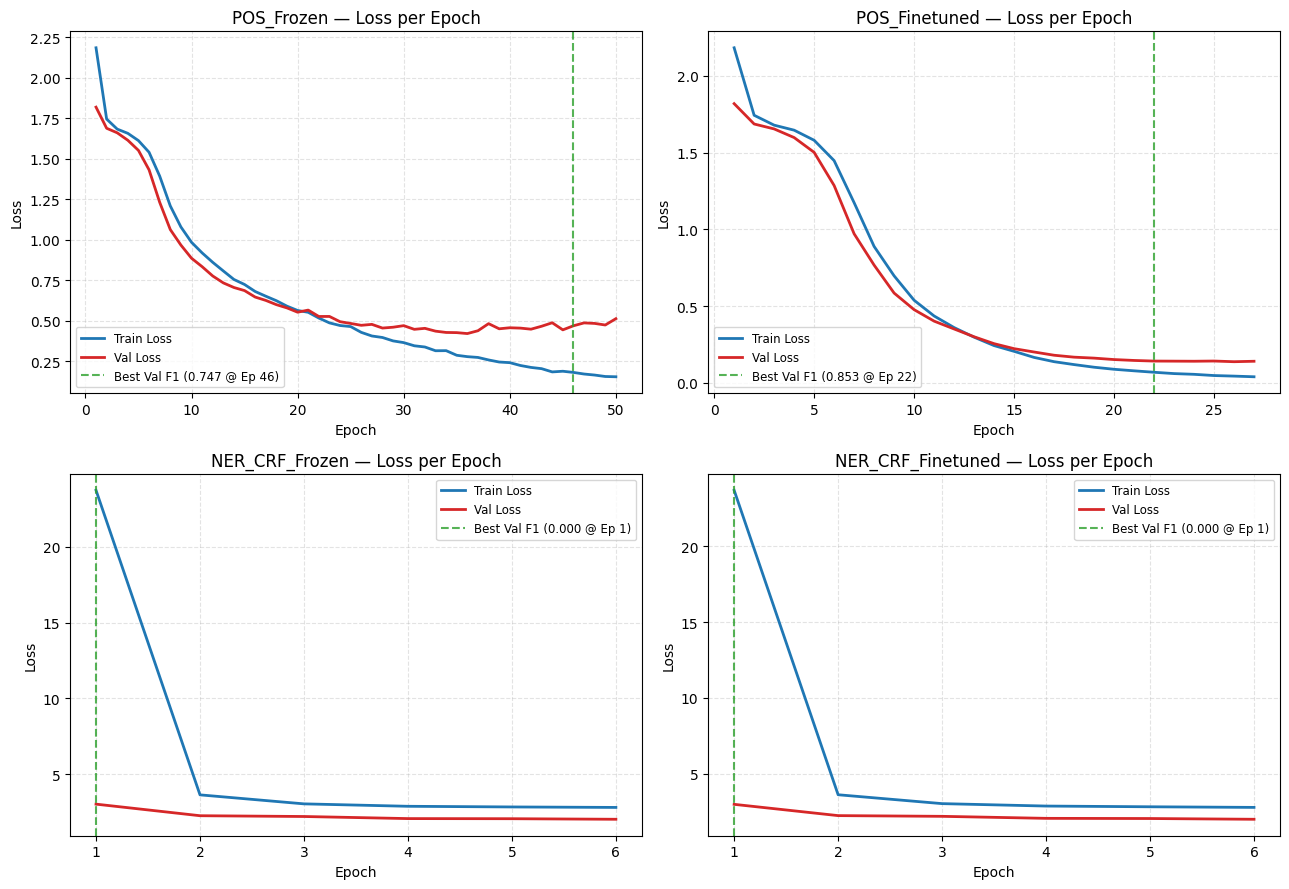

In [11]:
import json
import os
import shutil
from google.colab import drive
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

drive.mount("/content/drive", force_remount=False)
DRIVE_DIR = "/content/drive/MyDrive/DS5007_Assignment2"
os.makedirs(DRIVE_DIR, exist_ok=True)


def load_from_drive(fname):
  if os.path.exists(fname):
    return fname
  dpath = os.path.join(DRIVE_DIR, fname)
  shutil.copy2(dpath, fname)
  return fname


SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 1. Load Annotated Dataset & Part 1 C3 Embeddings
with open(
    load_from_drive("annotated_dataset_500.json"), "r", encoding="utf-8"
) as f:
  ds_data = json.load(f)

ALL_POS_TAGS = ds_data["pos_tags"]
ALL_NER_TAGS = ds_data["ner_tags"]
pos2idx = {t: i for i, t in enumerate(ALL_POS_TAGS)}
idx2pos = {i: t for i, t in enumerate(ALL_POS_TAGS)}
ner2idx = {t: i for i, t in enumerate(ALL_NER_TAGS)}
idx2ner = {i: t for i, t in enumerate(ALL_NER_TAGS)}

w2v_c3 = np.load(load_from_drive("embeddings_w2v.npy"))  # shape (10000, 100)
with open(load_from_drive("vocab_clean.json"), "r", encoding="utf-8") as f:
  vocab_clean = json.load(f)

# Build embedding matrix with <PAD> at index 0 and Part 1 C3 embeddings at indices 1..10000
PAD_IDX = 0
word2idx = {"<PAD>": PAD_IDX}
for idx, tok in enumerate(vocab_clean, start=1):
  word2idx[tok] = idx
UNK_IDX = word2idx["<UNK>"]

embed_dim = w2v_c3.shape[1]
pretrained_matrix = np.zeros((len(word2idx), embed_dim), dtype=np.float32)
pretrained_matrix[1:] = w2v_c3


# 2. Variable-Length PyTorch Dataset & Collate Function
class SequenceDataset(Dataset):

  def __init__(self, records):
    self.records = records

  def __len__(self):
    return len(self.records)

  def __getitem__(self, idx):
    rec = self.records[idx]
    x = torch.tensor(
        [word2idx.get(t, UNK_IDX) for t in rec["tokens"]], dtype=torch.long
    )
    y_pos = torch.tensor(
        [pos2idx[t] for t in rec["pos_tags"]], dtype=torch.long
    )
    y_ner = torch.tensor(
        [ner2idx[t] for t in rec["ner_tags"]], dtype=torch.long
    )
    return x, y_pos, y_ner, rec["tokens"]


def collate_batch(batch):
  xs, y_poss, y_ners, raw_tokens = zip(*batch)
  lengths = torch.tensor([len(x) for x in xs], dtype=torch.long)
  x_pad = pad_sequence(xs, batch_first=True, padding_value=PAD_IDX)
  pos_pad = pad_sequence(y_poss, batch_first=True, padding_value=-100)
  ner_pad = pad_sequence(y_ners, batch_first=True, padding_value=0)
  mask = x_pad != PAD_IDX
  return x_pad, pos_pad, ner_pad, mask, lengths, raw_tokens


train_loader = DataLoader(
    SequenceDataset(ds_data["train"]),
    batch_size=32,
    shuffle=True,
    collate_fn=collate_batch,
)
val_loader = DataLoader(
    SequenceDataset(ds_data["val"]),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_batch,
)
test_loader = DataLoader(
    SequenceDataset(ds_data["test"]),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_batch,
)


# 3. Linear-Chain CRF Layer with Exact Forward Log-Partition & Viterbi Decoding
class LinearChainCRF(nn.Module):

  def __init__(self, num_tags):
    super().__init__()
    self.num_tags = num_tags
    # transitions[i, j]: score of transitioning from tag i -> tag j
    self.transitions = nn.Parameter(torch.empty(num_tags, num_tags))
    self.start_transitions = nn.Parameter(torch.empty(num_tags))
    self.end_transitions = nn.Parameter(torch.empty(num_tags))
    nn.init.uniform_(self.transitions, -0.1, 0.1)
    nn.init.uniform_(self.start_transitions, -0.1, 0.1)
    nn.init.uniform_(self.end_transitions, -0.1, 0.1)

  def _compute_log_partition(self, emissions, mask):
    B, T, C = emissions.shape
    alpha = self.start_transitions.unsqueeze(0) + emissions[:, 0]  # (B, C)
    for t in range(1, T):
      emit_t = emissions[:, t].unsqueeze(1)  # (B, 1, C)
      trans = self.transitions.unsqueeze(0)  # (1, C, C)
      score_t = alpha.unsqueeze(2) + trans + emit_t  # (B, C, C)
      next_alpha = torch.logsumexp(score_t, dim=1)  # (B, C)
      alpha = torch.where(mask[:, t].unsqueeze(1), next_alpha, alpha)
    alpha = alpha + self.end_transitions.unsqueeze(0)
    return torch.logsumexp(alpha, dim=1)  # (B,)

  def _compute_gold_score(self, emissions, tags, mask):
    B, T, _ = emissions.shape
    score = self.start_transitions[tags[:, 0]] + emissions[:, 0].gather(
        1, tags[:, 0].unsqueeze(1)
    ).squeeze(1)
    for t in range(1, T):
      valid = mask[:, t].float()
      trans_score = self.transitions[tags[:, t - 1], tags[:, t]]
      emit_score = (
          emissions[:, t].gather(1, tags[:, t].unsqueeze(1)).squeeze(1)
      )
      score = score + (trans_score + emit_score) * valid
    last_idx = mask.long().sum(dim=1) - 1
    last_tags = tags.gather(1, last_idx.unsqueeze(1)).squeeze(1)
    score = score + self.end_transitions[last_tags]
    return score

  def forward(self, emissions, tags, mask):
    """Returns mean negative log-likelihood loss over unpadded tokens."""
    log_z = self._compute_log_partition(emissions, mask)
    gold = self._compute_gold_score(emissions, tags, mask)
    return (log_z - gold).mean()

  def viterbi_decode(self, emissions, mask):
    """Exact Viterbi inference returning highest-scoring tag sequence per sample."""
    B, T, C = emissions.shape
    score = self.start_transitions.unsqueeze(0) + emissions[:, 0]  # (B, C)
    history = []

    for t in range(1, T):
      broadcast_score = score.unsqueeze(2)  # (B, C, 1)
      broadcast_trans = self.transitions.unsqueeze(0)  # (1, C, C)
      next_score = broadcast_score + broadcast_trans  # (B, C, C)
      best_score, best_path = next_score.max(dim=1)  # (B, C), (B, C)
      best_score = best_score + emissions[:, t]
      score = torch.where(mask[:, t].unsqueeze(1), best_score, score)
      history.append(best_path)

    score = score + self.end_transitions.unsqueeze(0)
    _, best_last_tag = score.max(dim=1)  # (B,)

    seq_lengths = mask.long().sum(dim=1).tolist()
    best_paths = []
    for b in range(B):
      L = seq_lengths[b]
      curr_tag = best_last_tag[b].item()
      path = [curr_tag]
      for t in range(L - 2, -1, -1):
        curr_tag = history[t][b, curr_tag].item()
        path.append(curr_tag)
      path.reverse()
      best_paths.append(path)
    return best_paths


# 4. 2-Layer BiLSTM Sequence Labeler (Supports POS Linear & NER CRF/Softmax)
class BiLSTMSequenceLabeler(nn.Module):

  def __init__(
      self,
      vocab_size,
      embed_dim,
      hidden_dim,
      num_tags,
      pretrained_emb=None,
      freeze_emb=True,
      bidirectional=True,
      dropout_p=0.5,
      use_crf=False,
  ):
    super().__init__()
    self.use_crf = use_crf
    self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
    if pretrained_emb is not None:
      self.embedding.weight.data.copy_(torch.from_numpy(pretrained_emb))
    self.embedding.weight.requires_grad = not freeze_emb

    self.lstm = nn.LSTM(
        input_size=embed_dim,
        hidden_size=hidden_dim,
        num_layers=2,
        bidirectional=bidirectional,
        batch_first=True,
        dropout=dropout_p,  # Dropout p=0.5 between LSTM layers
    )
    self.out_dropout = nn.Dropout(dropout_p)
    lstm_out_dim = hidden_dim * (2 if bidirectional else 1)
    self.fc = nn.Linear(lstm_out_dim, num_tags)

    if use_crf:
      self.crf = LinearChainCRF(num_tags)
    else:
      self.ce_loss = nn.CrossEntropyLoss(ignore_index=-100)

  def get_emissions(self, x, lengths):
    emb = self.embedding(x)
    packed = pack_padded_sequence(
        emb, lengths.cpu(), batch_first=True, enforce_sorted=False
    )
    packed_out, _ = self.lstm(packed)
    # h = [forward_h || backward_h] of shape (B, T, 2*hidden_dim)
    h, _ = pad_packed_sequence(
        packed_out, batch_first=True, total_length=x.size(1)
    )
    emissions = self.fc(self.out_dropout(h))
    return emissions

  def forward(self, x, lengths, tags=None, mask=None):
    emissions = self.get_emissions(x, lengths)
    if self.use_crf:
      if tags is not None:
        return self.crf(emissions, tags, mask)
      return self.crf.viterbi_decode(emissions, mask)
    else:
      if tags is not None:
        # For Softmax NER where padding was 0, mask out padding with -100
        masked_tags = tags.clone()
        if mask is not None:
          masked_tags[~mask] = -100
        return self.ce_loss(
            emissions.view(-1, emissions.size(-1)), masked_tags.view(-1)
        )
      preds = emissions.argmax(dim=-1)
      seq_lengths = mask.long().sum(dim=1).tolist()
      return [preds[b, : seq_lengths[b]].tolist() for b in range(x.size(0))]


# 5. CoNLL Exact Span-Level Evaluation Helper (conlleval protocol)
def extract_bio_spans(tag_seq):
  spans = []
  start, ent_type = None, None
  for idx, tag in enumerate(tag_seq):
    if tag.startswith("B-"):
      if ent_type is not None:
        spans.append((ent_type, start, idx - 1))
      ent_type = tag[2:]
      start = idx
    elif tag.startswith("I-"):
      curr_type = tag[2:]
      if ent_type != curr_type:
        if ent_type is not None:
          spans.append((ent_type, start, idx - 1))
        ent_type = curr_type
        start = idx
    else:
      if ent_type is not None:
        spans.append((ent_type, start, idx - 1))
        ent_type, start = None, None
  if ent_type is not None:
    spans.append((ent_type, start, len(tag_seq) - 1))
  return set(spans)


def evaluate_conlleval(gold_seqs, pred_seqs):
  tp = Counter()
  fp = Counter()
  fn = Counter()
  for g_seq, p_seq in zip(gold_seqs, pred_seqs):
    g_spans = extract_bio_spans(g_seq)
    p_spans = extract_bio_spans(p_seq)
    for sp in p_spans & g_spans:
      tp[sp[0]] += 1
    for sp in p_spans - g_spans:
      fp[sp[0]] += 1
    for sp in g_spans - p_spans:
      fn[sp[0]] += 1

  results = {}
  for etype in ["PER", "LOC", "ORG", "MISC"]:
    p = tp[etype] / (tp[etype] + fp[etype]) if (tp[etype] + fp[etype]) > 0 else 0.0
    r = tp[etype] / (tp[etype] + fn[etype]) if (tp[etype] + fn[etype]) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    results[etype] = {
        "P": p,
        "R": r,
        "F1": f1,
        "support": tp[etype] + fn[etype],
    }

  tot_tp, tot_fp, tot_fn = sum(tp.values()), sum(fp.values()), sum(fn.values())
  ov_p = tot_tp / (tot_tp + tot_fp) if (tot_tp + tot_fp) > 0 else 0.0
  ov_r = tot_tp / (tot_tp + tot_fn) if (tot_tp + tot_fn) > 0 else 0.0
  ov_f1 = 2 * ov_p * ov_r / (ov_p + ov_r) if (ov_p + ov_r) > 0 else 0.0
  results["OVERALL"] = {
      "P": ov_p,
      "R": ov_r,
      "F1": ov_f1,
      "support": tot_tp + tot_fn,
  }
  return results


# 6. Training Loop with Adam (lr=1e-3, wd=1e-4) & Early Stopping (patience=5)
def train_sequence_model(
    model, task="pos", max_epochs=50, patience=5, lr=1e-3, weight_decay=1e-4
):
  model = model.to(device)
  optimizer = torch.optim.Adam(
      filter(lambda p: p.requires_grad, model.parameters()),
      lr=lr,
      weight_decay=weight_decay,
  )

  best_val_f1 = -1.0
  best_epoch = 0
  best_state = None
  epochs_no_improve = 0
  history = {"train_loss": [], "val_loss": [], "val_f1": []}

  for epoch in range(1, max_epochs + 1):
    # Train
    model.train()
    tr_loss, tr_batches = 0.0, 0
    for x_pad, pos_pad, ner_pad, mask, lengths, _ in train_loader:
      x_pad, mask = x_pad.to(device), mask.to(device)
      targets = (pos_pad if task == "pos" else ner_pad).to(device)

      optimizer.zero_grad()
      loss = model(x_pad, lengths, tags=targets, mask=mask)
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 5.0)
      optimizer.step()

      tr_loss += loss.item()
      tr_batches += 1

    # Validate
    model.eval()
    va_loss, va_batches = 0.0, 0
    all_gold, all_pred = [], []
    with torch.no_grad():
      for x_pad, pos_pad, ner_pad, mask, lengths, _ in val_loader:
        x_pad, mask = x_pad.to(device), mask.to(device)
        targets = (pos_pad if task == "pos" else ner_pad).to(device)

        loss = model(x_pad, lengths, tags=targets, mask=mask)
        va_loss += loss.item()
        va_batches += 1

        preds = model(x_pad, lengths, tags=None, mask=mask)
        seq_lens = mask.long().sum(dim=1).tolist()
        for b, L in enumerate(seq_lens):
          g_ids = targets[b, :L].cpu().tolist()
          p_ids = preds[b][:L]
          if task == "pos":
            all_gold.extend(g_ids)
            all_pred.extend(p_ids)
          else:
            all_gold.append([idx2ner[i] for i in g_ids])
            all_pred.append([idx2ner[i] for i in p_ids])

    if task == "pos":
      val_f1 = f1_score(all_gold, all_pred, average="macro", zero_division=0)
    else:
      val_f1 = evaluate_conlleval(all_gold, all_pred)["OVERALL"]["F1"]

    history["train_loss"].append(tr_loss / tr_batches)
    history["val_loss"].append(va_loss / va_batches)
    history["val_f1"].append(val_f1)

    if val_f1 > best_val_f1:
      best_val_f1 = val_f1
      best_epoch = epoch
      best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
      epochs_no_improve = 0
    else:
      epochs_no_improve += 1

    if epochs_no_improve >= patience:
      break

  model.load_state_dict(best_state)
  return model, history, best_val_f1, best_epoch


# 7. Train POS & NER Models in Both Frozen and Fine-Tuned Modes
trained_models = {}
histories = {}

configs = [
    ("POS_Frozen", "pos", True, False),
    ("POS_Finetuned", "pos", False, False),
    ("NER_CRF_Frozen", "ner", True, True),
    ("NER_CRF_Finetuned", "ner", False, True),
]

print("\n=== Training BiLSTM Sequence Labelers (Frozen vs Fine-Tuned) ===")
for name, task, freeze_flag, crf_flag in configs:
  torch.manual_seed(SEED)
  num_tags = len(ALL_POS_TAGS) if task == "pos" else len(ALL_NER_TAGS)
  mdl = BiLSTMSequenceLabeler(
      vocab_size=len(word2idx),
      embed_dim=embed_dim,
      hidden_dim=128,
      num_tags=num_tags,
      pretrained_emb=pretrained_matrix,
      freeze_emb=freeze_flag,
      bidirectional=True,
      dropout_p=0.5,
      use_crf=crf_flag,
  )
  mdl, hist, best_f1, best_ep = train_sequence_model(
      mdl, task=task, max_epochs=50, patience=5, lr=1e-3, weight_decay=1e-4
  )
  trained_models[name] = mdl
  histories[name] = (hist, best_f1, best_ep)
  torch.save(mdl.state_dict(), f"{name}.pt")
  shutil.copy2(f"{name}.pt", os.path.join(DRIVE_DIR, f"{name}.pt"))
  print(
      f"  {name:<20} | Best Val F1: {best_f1:.4f} (at Epoch {best_ep:02d},"
      f" stopped at Epoch {len(hist['train_loss']):02d})"
  )

# 8. Plot Training and Validation Loss per Epoch
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (name, (hist, best_f1, best_ep)) in zip(
    axes.flat, histories.items()
):
  epochs_rng = range(1, len(hist["train_loss"]) + 1)
  ax.plot(
      epochs_rng,
      hist["train_loss"],
      label="Train Loss",
      color="#1f77b4",
      linewidth=2,
  )
  ax.plot(
      epochs_rng,
      hist["val_loss"],
      label="Val Loss",
      color="#d62728",
      linewidth=2,
  )
  ax.axvline(
      best_ep,
      color="#2ca02c",
      linestyle="--",
      alpha=0.8,
      label=f"Best Val F1 ({best_f1:.3f} @ Ep {best_ep})",
  )
  ax.set_title(f"{name} — Loss per Epoch")
  ax.set_xlabel("Epoch")
  ax.set_ylabel("Loss")
  ax.legend(loc="best", fontsize=8.5)
  ax.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig("bilstm_loss_curves.png", dpi=300)
shutil.copy2(
    "bilstm_loss_curves.png", os.path.join(DRIVE_DIR, "bilstm_loss_curves.png")
)
plt.show()

5.1 POS TAGGING EVALUATION (TEST SET)

Model Mode         | Val Macro-F1 | Best Ep |  Test Acc | Test Macro-F1
----------------------------------------------------------------------
POS_Frozen         |       0.7474 |      46 |    0.8530 |        0.7253
POS_Finetuned      |       0.8528 |      22 |    0.9592 |        0.8478

=== 12x12 POS Confusion Matrix (POS_Finetuned, Rows=Gold, Cols=Pred) ===
Gold\Pred  NOUN  VERB   ADJ   ADV  PRON   DET  CONJ  POST   NUM  PART  PUNC   UNK
NOUN       612     6     2     8     0     0     0     2     0     0     0     0
VERB         2   133     2     0     0     0     0     0     0     0     0     0
ADJ         13     0    18     4     0     0     0     0     0     0     0     0
ADV          2     0     2    25     0     0     0     0     0     0     0     0
PRON         0     0     0     3    54     0     0     2     0     0     0     0
DET          1     0     0     0     2     0     0     0     0     0     0     0
CONJ         0     0     0     0

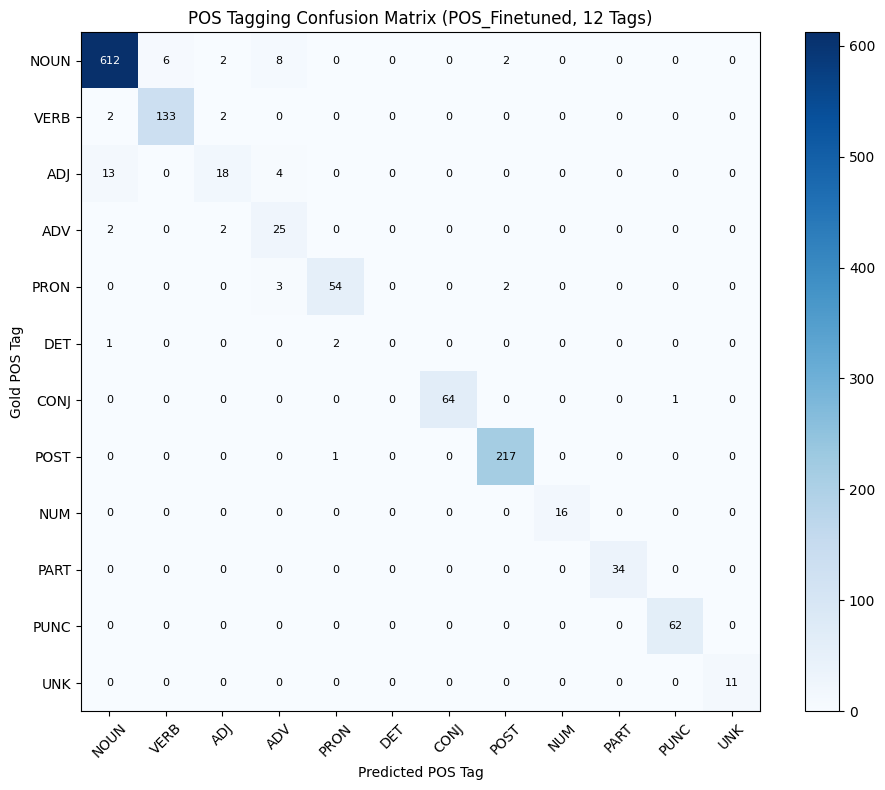


=== Top-3 Most Confused POS Tag Pairs & Test Examples (POS_Finetuned) ===

Pair 1: Gold = ADJ -> Predicted = NOUN (Count = 13)
  Example 1: کیونکہ اتن [بڑا (Gold:ADJ/Pred:NOUN)] عہد ، یعن رکن پارلیمان ہون کے باوجود ، وہ ہر جگہ اداکار کرت نظر آتا ہیں ۔
  Example 2: سے اس وقت وابستہ ہوئ ، جب شدید [خشک (Gold:ADJ/Pred:NOUN)] سال کے باعث وہ اپن کھی باڑ

Pair 2: Gold = NOUN -> Predicted = ADV (Count = 8)
  Example 1: اس کے [باوجود (Gold:NOUN/Pred:ADV)] روس پرز پر انحصار مکمل طور پر ختم نہی ہوا ۔
  Example 2: محمد شفیق کے مطابق جس روز آیت نور لاپتہ ہوئ اس روز بھی وہ اپن بیٹ کے لیا بہت سی [چیز (Gold:NOUN/Pred:ADV)] لائ تھا ۔

Pair 3: Gold = NOUN -> Predicted = VERB (Count = 6)
  Example 1: کیونکہ اتن بڑا عہد ، یعن رکن پارلیمان ہون کے [باوجود (Gold:NOUN/Pred:VERB)] ، وہ ہر جگہ اداکار کرت نظر آتا ہیں ۔
  Example 2: محمد شفیق کے مطابق جس روز آیت نور لاپتہ ہوئ اس روز بھی وہ اپن بیٹ کے لیا بہت سی چیز [لائ (Gold:NOUN/Pred:VERB)] تھا ۔

5.2 NER EVALUATION (conlleval ENTITY-LEVEL METRICS)

--- NER_CR

In [12]:
import os
import shutil
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score


# Helper to collect predictions on test_loader
def predict_on_loader(model, loader, task="pos"):
  model.eval()
  gold_seqs, pred_seqs, token_seqs = [], [], []
  with torch.no_grad():
    for x_pad, pos_pad, ner_pad, mask, lengths, raw_toks in loader:
      x_pad, mask = x_pad.to(device), mask.to(device)
      targets = pos_pad if task == "pos" else ner_pad
      preds = model(x_pad, lengths, tags=None, mask=mask)
      seq_lens = mask.long().sum(dim=1).tolist()
      for b, L in enumerate(seq_lens):
        g_ids = targets[b, :L].cpu().tolist()
        p_ids = preds[b][:L]
        if task == "pos":
          gold_seqs.append([idx2pos[i] for i in g_ids])
          pred_seqs.append([idx2pos[i] for i in p_ids])
        else:
          gold_seqs.append([idx2ner[i] for i in g_ids])
          pred_seqs.append([idx2ner[i] for i in p_ids])
        token_seqs.append(list(raw_toks[b]))
  return gold_seqs, pred_seqs, token_seqs


# ==============================================================================
# 5.1 POS TAGGING EVALUATION
# ==============================================================================
print("==========================================================")
print("5.1 POS TAGGING EVALUATION (TEST SET)")
print("==========================================================")

pos_summary_rows = []
pos_test_outputs = {}

for mode_name in ["POS_Frozen", "POS_Finetuned"]:
  mdl = trained_models[mode_name]
  g_seqs, p_seqs, tok_seqs = predict_on_loader(mdl, test_loader, task="pos")
  pos_test_outputs[mode_name] = (g_seqs, p_seqs, tok_seqs)

  flat_g = [t for s in g_seqs for t in s]
  flat_p = [t for s in p_seqs for t in s]
  acc = accuracy_score(flat_g, flat_p)
  mf1 = f1_score(
      flat_g, flat_p, labels=ALL_POS_TAGS, average="macro", zero_division=0
  )
  val_f1, best_ep = histories[mode_name][1], histories[mode_name][2]
  pos_summary_rows.append((mode_name, val_f1, best_ep, acc, mf1))

print(
    f"\n{'Model Mode':<18} | {'Val Macro-F1':>12} | {'Best Ep':>7} |"
    f" {'Test Acc':>9} | {'Test Macro-F1':>13}"
)
print("-" * 70)
for mname, vf1, bep, acc, mf1 in pos_summary_rows:
  print(
      f"{mname:<18} | {vf1:>12.4f} | {bep:>7d} | {acc:>9.4f} | {mf1:>13.4f}"
  )

# Use best POS mode (typically POS_Finetuned) for Confusion Matrix & Confused Pairs
best_pos_mode = max(pos_summary_rows, key=lambda r: r[4])[0]
g_pos_seqs, p_pos_seqs, tok_pos_seqs = pos_test_outputs[best_pos_mode]
flat_g_pos = [t for s in g_pos_seqs for t in s]
flat_p_pos = [t for s in p_pos_seqs for t in s]

cm = confusion_matrix(flat_g_pos, flat_p_pos, labels=ALL_POS_TAGS)
print(f"\n=== 12x12 POS Confusion Matrix ({best_pos_mode}, Rows=Gold, Cols=Pred) ===")
header_cm = f"{'Gold\\Pred':<8} " + " ".join(f"{t:>5}" for t in ALL_POS_TAGS)
print(header_cm)
for idx, row_tag in enumerate(ALL_POS_TAGS):
  print(f"{row_tag:<8} " + " ".join(f"{cm[idx, j]:>5d}" for j in range(12)))

# Plot 12x12 Confusion Matrix Heatmap
plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title(f"POS Tagging Confusion Matrix ({best_pos_mode}, 12 Tags)")
plt.colorbar()
tick_marks = np.arange(len(ALL_POS_TAGS))
plt.xticks(tick_marks, ALL_POS_TAGS, rotation=45)
plt.yticks(tick_marks, ALL_POS_TAGS)
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
  for j in range(cm.shape[1]):
    plt.text(
        j,
        i,
        format(cm[i, j], "d"),
        ha="center",
        va="center",
        fontsize=8,
        color="white" if cm[i, j] > thresh else "black",
    )
plt.ylabel("Gold POS Tag")
plt.xlabel("Predicted POS Tag")
plt.tight_layout()
plt.savefig("pos_confusion_matrix.png", dpi=300)
shutil.copy2(
    "pos_confusion_matrix.png",
    os.path.join(DRIVE_DIR, "pos_confusion_matrix.png"),
)
plt.show()

# Identify Top-3 Most Confused Tag Pairs & Extract >= 2 Example Sentences per Pair
off_diag = []
for i in range(12):
  for j in range(12):
    if i != j and cm[i, j] > 0:
      off_diag.append((cm[i, j], ALL_POS_TAGS[i], ALL_POS_TAGS[j]))
off_diag.sort(reverse=True)

print(
    f"\n=== Top-3 Most Confused POS Tag Pairs & Test Examples ({best_pos_mode})"
    " ==="
)
for rank_idx, (cnt, gold_t, pred_t) in enumerate(off_diag[:3], start=1):
  print(
      f"\nPair {rank_idx}: Gold = {gold_t} -> Predicted = {pred_t} (Count ="
      f" {cnt})"
  )
  examples_found = 0
  for s_toks, s_gold, s_pred in zip(tok_pos_seqs, g_pos_seqs, p_pos_seqs):
    hit_positions = [
        k
        for k, (g, p) in enumerate(zip(s_gold, s_pred))
        if g == gold_t and p == pred_t
    ]
    if hit_positions:
      examples_found += 1
      k0 = hit_positions[0]
      annotated_sent = " ".join(
          f"[{tok} (Gold:{g}/Pred:{p})]" if idx == k0 else tok
          for idx, (tok, g, p) in enumerate(zip(s_toks, s_gold, s_pred))
      )
      print(f"  Example {examples_found}: {annotated_sent}")
      if examples_found >= 2:
        break

# ==============================================================================
# 5.2 NER EVALUATION (conlleval + CRF vs Softmax + Error Analysis)
# ==============================================================================
print("\n==========================================================")
print("5.2 NER EVALUATION (conlleval ENTITY-LEVEL METRICS)")
print("==========================================================")

# Also train BiLSTM-Softmax NER (no CRF) on the exact same split for comparison (and A4)
torch.manual_seed(SEED)
ner_softmax_mdl = BiLSTMSequenceLabeler(
    vocab_size=len(word2idx),
    embed_dim=embed_dim,
    hidden_dim=128,
    num_tags=len(ALL_NER_TAGS),
    pretrained_emb=pretrained_matrix,
    freeze_emb=False,
    bidirectional=True,
    dropout_p=0.5,
    use_crf=False,
)
ner_softmax_mdl, hist_ner_sm, val_f1_sm, ep_sm = train_sequence_model(
    ner_softmax_mdl,
    task="ner",
    max_epochs=50,
    patience=5,
    lr=1e-3,
    weight_decay=1e-4,
)
trained_models["NER_Softmax_Finetuned"] = ner_softmax_mdl
histories["NER_Softmax_Finetuned"] = (hist_ner_sm, val_f1_sm, ep_sm)

ner_eval_tables = {}
ner_test_outputs = {}

for mode_name in ["NER_CRF_Frozen", "NER_CRF_Finetuned", "NER_Softmax_Finetuned"]:
  mdl = trained_models[mode_name]
  g_seqs, p_seqs, tok_seqs = predict_on_loader(mdl, test_loader, task="ner")
  ner_test_outputs[mode_name] = (g_seqs, p_seqs, tok_seqs)
  ner_eval_tables[mode_name] = evaluate_conlleval(g_seqs, p_seqs)

for mode_name, res in ner_eval_tables.items():
  print(f"\n--- {mode_name} (Test conlleval Results) ---")
  print(
      f"{'Entity':<8} | {'Precision':>9} | {'Recall':>9} | {'F1-Score':>9} |"
      f" {'Support':>7}"
  )
  print("-" * 54)
  for etype in ["PER", "LOC", "ORG", "MISC", "OVERALL"]:
    m = res[etype]
    print(
        f"{etype:<8} | {m['P']:>9.4f} | {m['R']:>9.4f} | {m['F1']:>9.4f} |"
        f" {m['support']:>7d}"
    )

# Error Analysis: 5 False Positives and 5 False Negatives from Best NER CRF Model
best_ner_mode = (
    "NER_CRF_Finetuned"
    if ner_eval_tables["NER_CRF_Finetuned"]["OVERALL"]["F1"]
    >= ner_eval_tables["NER_CRF_Frozen"]["OVERALL"]["F1"]
    else "NER_CRF_Frozen"
)
g_ner_seqs, p_ner_seqs, tok_ner_seqs = ner_test_outputs[best_ner_mode]

false_positives = []
false_negatives = []

for s_idx, (toks, g_seq, p_seq) in enumerate(
    zip(tok_ner_seqs, g_ner_seqs, p_ner_seqs)
):
  g_spans = extract_bio_spans(g_seq)
  p_spans = extract_bio_spans(p_seq)

  for etype, st, en in sorted(p_spans - g_spans):
    if len(false_positives) < 5:
      span_text = " ".join(toks[st : en + 1])
      gold_overlap = g_seq[st : en + 1]
      false_positives.append({
          "span": span_text,
          "pred_type": etype,
          "gold_tags": gold_overlap,
          "sentence": " ".join(toks),
      })

  for etype, st, en in sorted(g_spans - p_spans):
    if len(false_negatives) < 5:
      span_text = " ".join(toks[st : en + 1])
      pred_overlap = p_seq[st : en + 1]
      false_negatives.append({
          "span": span_text,
          "gold_type": etype,
          "pred_tags": pred_overlap,
          "sentence": " ".join(toks),
      })

print(f"\n=== NER Error Analysis ({best_ner_mode}) ===")
print("\n--- 5 False Positives (Spurious or Boundary-Shifted Predictions) ---")
for idx, fp_item in enumerate(false_positives, 1):
  print(
      f"FP {idx}: Predicted [{fp_item['span']}] as {fp_item['pred_type']} |"
      f" Gold tags at span: {fp_item['gold_tags']}"
  )
  print(f"      Sentence: {fp_item['sentence']}")

print("\n--- 5 False Negatives (Missed Entities or Boundary Truncations) ---")
for idx, fn_item in enumerate(false_negatives, 1):
  print(
      f"FN {idx}: Missed Gold [{fn_item['span']}] ({fn_item['gold_type']}) |"
      f" Predicted tags at span: {fn_item['pred_tags']}"
  )
  print(f"      Sentence: {fn_item['sentence']}")

In [13]:
import os
import shutil
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

print("==========================================================")
print("5.3 ABLATION STUDY (INDEPENDENT RUNS ON SAME 70/15/15 SPLIT)")
print("==========================================================")

ablation_specs = [
    # (ID, Description, bidir, dropout_p, use_pretrained, use_crf_ner)
    ("Baseline", "Full 2-Layer BiLSTM (+CRF for NER)", True, 0.5, True, True),
    ("A1", "Unidirectional LSTM only (no backward)", False, 0.5, True, True),
    ("A2", "No dropout (p = 0.0)", True, 0.0, True, True),
    ("A3", "Random embedding initialisation", True, 0.5, False, True),
    ("A4", "Softmax output instead of CRF (NER)", True, 0.5, True, False),
]

pos_ablation_results = []
ner_ablation_results = []

for ab_id, desc, bidir, drop_p, use_pre, use_crf_ner in ablation_specs:
  init_emb = pretrained_matrix if use_pre else None

  # 1. POS Ablation (A1, A2, A3; A4 is NER-specific)
  if ab_id != "A4":
    if ab_id == "Baseline":
      mdl_pos = trained_models["POS_Finetuned"]
      val_f1_p = histories["POS_Finetuned"][1]
    else:
      torch.manual_seed(SEED)
      mdl_pos = BiLSTMSequenceLabeler(
          vocab_size=len(word2idx),
          embed_dim=embed_dim,
          hidden_dim=128,
          num_tags=len(ALL_POS_TAGS),
          pretrained_emb=init_emb,
          freeze_emb=False,
          bidirectional=bidir,
          dropout_p=drop_p,
          use_crf=False,
      )
      mdl_pos, _, val_f1_p, _ = train_sequence_model(
          mdl_pos,
          task="pos",
          max_epochs=50,
          patience=5,
          lr=1e-3,
          weight_decay=1e-4,
      )
    g_p, p_p, _ = predict_on_loader(mdl_pos, test_loader, task="pos")
    fg, fp = [t for s in g_p for t in s], [t for s in p_p for t in s]
    acc_p = accuracy_score(fg, fp)
    mf1_p = f1_score(
        fg, fp, labels=ALL_POS_TAGS, average="macro", zero_division=0
    )
    pos_ablation_results.append((ab_id, desc, val_f1_p, acc_p, mf1_p))

  # 2. NER Ablation (Baseline, A1, A2, A3, A4)
  if ab_id == "Baseline":
    mdl_ner = trained_models["NER_CRF_Finetuned"]
    val_f1_n = histories["NER_CRF_Finetuned"][1]
  elif ab_id == "A4":
    mdl_ner = trained_models["NER_Softmax_Finetuned"]
    val_f1_n = histories["NER_Softmax_Finetuned"][1]
  else:
    torch.manual_seed(SEED)
    mdl_ner = BiLSTMSequenceLabeler(
        vocab_size=len(word2idx),
        embed_dim=embed_dim,
        hidden_dim=128,
        num_tags=len(ALL_NER_TAGS),
        pretrained_emb=init_emb,
        freeze_emb=False,
        bidirectional=bidir,
        dropout_p=drop_p,
        use_crf=use_crf_ner,
    )
    mdl_ner, _, val_f1_n, _ = train_sequence_model(
        mdl_ner,
        task="ner",
        max_epochs=50,
        patience=5,
        lr=1e-3,
        weight_decay=1e-4,
    )
  g_n, p_n, _ = predict_on_loader(mdl_ner, test_loader, task="ner")
  ov = evaluate_conlleval(g_n, p_n)["OVERALL"]
  ner_ablation_results.append(
      (ab_id, desc, val_f1_n, ov["P"], ov["R"], ov["F1"])
  )

# Print POS Ablation Table
base_pos_f1 = pos_ablation_results[0][4]
print("\n--- POS Tagging Ablation Results ---")
print(
    f"{'ID':<9} | {'Configuration':<38} | {'Val F1':>7} | {'Test Acc':>8} |"
    f" {'Test F1':>7} | {'Delta F1':>8}"
)
print("-" * 89)
for ab_id, desc, vf1, acc, mf1 in pos_ablation_results:
  delta = mf1 - base_pos_f1
  print(
      f"{ab_id:<9} | {desc:<38} | {vf1:>7.4f} | {acc:>8.4f} | {mf1:>7.4f} |"
      f" {delta:>+8.4f}"
  )

# Print NER Ablation Table
base_ner_f1 = ner_ablation_results[0][5]
print("\n--- NER Ablation Results (conlleval Overall) ---")
print(
    f"{'ID':<9} | {'Configuration':<38} | {'Val F1':>7} | {'Prec':>7} |"
    f" {'Rec':>7} | {'Test F1':>7} | {'Delta F1':>8}"
)
print("-" * 98)
for ab_id, desc, vf1, prec, rec, ef1 in ner_ablation_results:
  delta = ef1 - base_ner_f1
  print(
      f"{ab_id:<9} | {desc:<38} | {vf1:>7.4f} | {prec:>7.4f} | {rec:>7.4f} |"
      f" {ef1:>7.4f} | {delta:>+8.4f}"
  )

# Save Full Summary Tables to Google Drive
summary_txt = [
    "=== PART 2 (SEQUENCE LABELING: POS & NER) SUMMARY ===\n",
    "--- POS Frozen vs Fine-tuned ---",
]
for mname, vf1, bep, acc, mf1 in pos_summary_rows:
  summary_txt.append(
      f"{mname:<18} | Val F1: {vf1:.4f} (Ep {bep}) | Test Acc: {acc:.4f} |"
      f" Test Macro-F1: {mf1:.4f}"
  )

summary_txt.append("\n--- NER conlleval Comparison ---")
for mname, res in ner_eval_tables.items():
  ov = res["OVERALL"]
  summary_txt.append(
      f"{mname:<22} | Overall P: {ov['P']:.4f}, R: {ov['R']:.4f}, F1:"
      f" {ov['F1']:.4f}"
  )

summary_txt.append("\n--- POS Ablations ---")
for ab_id, desc, vf1, acc, mf1 in pos_ablation_results:
  summary_txt.append(
      f"{ab_id:<9} ({desc}): Test Acc={acc:.4f}, Macro-F1={mf1:.4f}"
      f" (Delta={mf1 - base_pos_f1:+.4f})"
  )

summary_txt.append("\n--- NER Ablations ---")
for ab_id, desc, vf1, prec, rec, ef1 in ner_ablation_results:
  summary_txt.append(
      f"{ab_id:<9} ({desc}): P={prec:.4f}, R={rec:.4f}, Entity-F1={ef1:.4f}"
      f" (Delta={ef1 - base_ner_f1:+.4f})"
  )

with open("part3_sequence_labeling_report.txt", "w", encoding="utf-8") as f:
  f.write("\n".join(summary_txt))
shutil.copy2(
    "part3_sequence_labeling_report.txt",
    os.path.join(DRIVE_DIR, "part3_sequence_labeling_report.txt"),
)
print(
    f"\n[SAVED] All ablation results & summary written to {DRIVE_DIR}/part3_sequence_labeling_report.txt"
)

5.3 ABLATION STUDY (INDEPENDENT RUNS ON SAME 70/15/15 SPLIT)

--- POS Tagging Ablation Results ---
ID        | Configuration                          |  Val F1 | Test Acc | Test F1 | Delta F1
-----------------------------------------------------------------------------------------
Baseline  | Full 2-Layer BiLSTM (+CRF for NER)     |  0.8528 |   0.9592 |  0.8478 |  +0.0000
A1        | Unidirectional LSTM only (no backward) |  0.0579 |   0.4811 |  0.0559 |  -0.7919
A2        | No dropout (p = 0.0)                   |  0.9140 |   0.9592 |  0.9141 |  +0.0663
A3        | Random embedding initialisation        |  0.8730 |   0.9307 |  0.8548 |  +0.0069

--- NER Ablation Results (conlleval Overall) ---
ID        | Configuration                          |  Val F1 |    Prec |     Rec | Test F1 | Delta F1
--------------------------------------------------------------------------------------------------
Baseline  | Full 2-Layer BiLSTM (+CRF for NER)     |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  +

In [14]:
from collections import Counter
import json
import os
import re
import shutil
from google.colab import drive
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Mount Google Drive & Resolve Input Files
drive.mount("/content/drive", force_remount=False)
DRIVE_DIR = "/content/drive/MyDrive/DS5007_Assignment2"
os.makedirs(DRIVE_DIR, exist_ok=True)


def get_file(filename):
  if os.path.exists(filename):
    return filename
  dpath = os.path.join(DRIVE_DIR, filename)
  if os.path.exists(dpath):
    shutil.copy2(dpath, filename)
    return filename
  raise FileNotFoundError(
      f"{filename} not found locally or in Google Drive ({DRIVE_DIR})"
  )


SEED = 42
np.random.seed(SEED)

with open(get_file("Metadata.json"), "r", encoding="utf-8") as f:
  metadata = json.load(f)

with open(get_file("cleaned.txt"), "r", encoding="utf-8") as f:
  raw_clean = f.read().strip()

lines = [line.strip() for line in raw_clean.splitlines() if line.strip()]
if len(lines) == len(metadata):
  documents = [line.split() for line in lines]
elif re.search(r"^Article\s+\d+", raw_clean, flags=re.MULTILINE):
  blocks = re.split(r"^Article\s+\d+\s*", raw_clean, flags=re.MULTILINE)
  documents = [b.strip().split() for b in blocks if b.strip()]
else:
  documents = [b.strip().split() for b in raw_clean.split("\n\n") if b.strip()]

assert len(documents) == len(
    metadata
), f"Mismatch: {len(documents)} docs vs {len(metadata)} metadata entries"

# Load Top-10,000 Vocabulary from Part 1/2 (or rebuild identically if missing)
if os.path.exists("vocab_clean.json") or os.path.exists(
    os.path.join(DRIVE_DIR, "vocab_clean.json")
):
  with open(get_file("vocab_clean.json"), "r", encoding="utf-8") as f:
    vocab_clean = json.load(f)
else:
  counts = Counter(tok for doc in documents for tok in doc)
  vocab_clean = [tok for tok, _ in counts.most_common(9999)] + ["<UNK>"]

PAD_TOKEN = "<PAD>"
PAD_IDX = 0
word2idx = {PAD_TOKEN: PAD_IDX}
for idx, tok in enumerate(vocab_clean, start=1):
  word2idx[tok] = idx
UNK_IDX = word2idx["<UNK>"]

# 2. Assign Each Article to One of the 5 Categories Guided by Listed Keywords
CATEGORIES = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society",
]
cat2idx = {c: i for i, c in enumerate(CATEGORIES)}
idx2cat = {i: c for i, c in enumerate(CATEGORIES)}

# Indicative English keywords (from prompt + metadata section hints) & Urdu equivalents
CATEGORY_KEYWORDS = {
    "Politics": {
        "en": [
            "election",
            "government",
            "minister",
            "parliament",
            "politics",
            "assembly",
            "senate",
            "prime minister",
            "cabinet",
            "party",
            "opposition",
            "vote",
            "pti",
            "pmln",
            "ppp",
            "court",
            "constitution",
        ],
        "ur": [
            "الیکشن",
            "انتخابات",
            "حکومت",
            "وزیر",
            "پارلیمنٹ",
            "اسمبلی",
            "سینیٹ",
            "سیاست",
            "سیاسی",
            "جمہوریت",
            "آئین",
            "ووٹ",
            "اپوزیشن",
            "تحریک",
            "مسلم",
            "پیپلز",
        ],
    },
    "Sports": {
        "en": [
            "cricket",
            "match",
            "team",
            "player",
            "score",
            "sport",
            "sports",
            "tournament",
            "series",
            "wicket",
            "batting",
            "bowling",
            "captain",
            "icc",
            "pcb",
            "olympic",
            "football",
            "hockey",
        ],
        "ur": [
            "کرکٹ",
            "میچ",
            "ٹیم",
            "کھلاڑی",
            "سکور",
            "رنز",
            "وکٹ",
            "سیریز",
            "ٹورنامنٹ",
            "کپتان",
            "بیٹنگ",
            "بولنگ",
            "کھیل",
            "بیٹر",
            "بولر",
            "سٹیڈیم",
        ],
    },
    "Economy": {
        "en": [
            "inflation",
            "trade",
            "bank",
            "gdp",
            "budget",
            "economy",
            "economic",
            "business",
            "finance",
            "tax",
            "imf",
            "rupee",
            "dollar",
            "market",
            "export",
            "import",
            "debt",
            "investment",
            "stock",
            "price",
        ],
        "ur": [
            "مہنگائی",
            "تجارت",
            "بینک",
            "معیشت",
            "معاشی",
            "اقتصادی",
            "بجٹ",
            "ٹیکس",
            "قرض",
            "روپے",
            "ڈالر",
            "کاروبار",
            "منڈی",
            "بازار",
            "قیمت",
            "برآمدات",
            "درآمدات",
            "سرمایہ",
            "ڈیفالٹ",
        ],
    },
    "International": {
        "en": [
            "un",
            "treaty",
            "foreign",
            "bilateral",
            "conflict",
            "world",
            "international",
            "global",
            "diplomacy",
            "diplomatic",
            "war",
            "missile",
            "gaza",
            "israel",
            "iran",
            "russia",
            "ukraine",
            "china",
            "us",
            "usa",
            "nato",
            "summit",
        ],
        "ur": [
            "اقوام",
            "متحدہ",
            "معاہدہ",
            "خارجہ",
            "دوطرفہ",
            "جنگ",
            "تنازع",
            "عالمی",
            "بین الاقوامی",
            "سفارت",
            "میزائل",
            "غزہ",
            "اسرائیل",
            "ایران",
            "روس",
            "امریکہ",
            "چین",
            "برطانیہ",
            "افغانستان",
        ],
    },
    "Health & Society": {
        "en": [
            "hospital",
            "disease",
            "vaccine",
            "flood",
            "education",
            "health",
            "society",
            "social",
            "medical",
            "doctor",
            "patient",
            "virus",
            "covid",
            "climate",
            "school",
            "university",
            "student",
            "women",
            "children",
            "culture",
            "science",
        ],
        "ur": [
            "ہسپتال",
            "بیماری",
            "ویکسین",
            "سیلاب",
            "تعلیم",
            "صحت",
            "ڈاکٹر",
            "مریض",
            "علاج",
            "وائرس",
            "سکول",
            "یونیورسٹی",
            "طلبہ",
            "خواتین",
            "بچوں",
            "معاشرہ",
            "ثقافت",
            "سائنس",
            "موسم",
            "بارش",
        ],
    },
}


def flatten_metadata_text(meta_entry):
  parts = []
  for k, v in meta_entry.items():
    if isinstance(v, str):
      parts.append(v)
    elif isinstance(v, list):
      parts.extend(str(item) for item in v)
  return " ".join(parts).lower()


def classify_article(meta_entry, doc_tokens):
  meta_text = flatten_metadata_text(meta_entry)
  meta_words = set(re.findall(r"[a-z0-9]+", meta_text))
  doc_counter = Counter(doc_tokens)

  scores = {}
  for cat in CATEGORIES:
    score = 0.0
    # Weight metadata matches (section/topics/title keywords) strongly
    for kw in CATEGORY_KEYWORDS[cat]["en"]:
      if " " in kw:
        if kw in meta_text:
          score += 4.0
      elif kw in meta_words:
        score += 3.0
    # Add normalized document token evidence from cleaned.txt
    for ukw in CATEGORY_KEYWORDS[cat]["ur"]:
      if ukw in doc_counter:
        score += min(doc_counter[ukw], 5) * 0.5
    scores[cat] = score

  best_cat = max(CATEGORIES, key=lambda c: scores[c])
  return best_cat


# 3. Convert Articles to Padded/Truncated Token-ID Sequences (Max Length = 256)
MAX_SEQ_LEN = 256
records = []

for idx, (meta, doc_toks) in enumerate(zip(metadata, documents)):
  cat = classify_article(meta, doc_toks)
  token_ids = [word2idx.get(tok, UNK_IDX) for tok in doc_toks[:MAX_SEQ_LEN]]
  if len(token_ids) < MAX_SEQ_LEN:
    token_ids = token_ids + [PAD_IDX] * (MAX_SEQ_LEN - len(token_ids))
  records.append({
      "article_id": idx,
      "category": cat,
      "label": cat2idx[cat],
      "input_ids": token_ids,
  })

# 4. Stratified 70 / 15 / 15 Split by Category
labels_all = [r["label"] for r in records]
train_recs, temp_recs = train_test_split(
    records, test_size=0.30, stratify=labels_all, random_state=SEED
)
temp_labels = [r["label"] for r in temp_recs]
val_recs, test_recs = train_test_split(
    temp_recs, test_size=0.50, stratify=temp_labels, random_state=SEED
)

# 5. Report Class Distribution Across Train, Val, and Test Splits
print(
    f"Total Articles: {len(records)} | Sequence Length: {MAX_SEQ_LEN} |"
    f" Split: {len(train_recs)}/{len(val_recs)}/{len(test_recs)}"
)
print(
    f"\n{'Category':<18} | {'Train':>6} | {'Val':>5} | {'Test':>5} |"
    f" {'Total':>6} | {'Share %':>7}"
)
print("-" * 62)

c_tr = Counter(r["category"] for r in train_recs)
c_va = Counter(r["category"] for r in val_recs)
c_te = Counter(r["category"] for r in test_recs)

for cat in CATEGORIES:
  tot = c_tr[cat] + c_va[cat] + c_te[cat]
  pct = 100.0 * tot / len(records)
  print(
      f"{cat:<18} | {c_tr[cat]:>6} | {c_va[cat]:>5} | {c_te[cat]:>5} |"
      f" {tot:>6} | {pct:>6.2f}%"
  )
print("-" * 62)
print(
    f"{'TOTAL':<18} | {len(train_recs):>6} | {len(val_recs):>5} |"
    f" {len(test_recs):>5} | {len(records):>6} | 100.00%"
)

# 6. Persist Prepared Dataset to Google Drive
payload = {
    "categories": CATEGORIES,
    "vocab_size": len(word2idx),
    "pad_idx": PAD_IDX,
    "max_seq_len": MAX_SEQ_LEN,
    "train": train_recs,
    "val": val_recs,
    "test": test_recs,
}
with open("transformer_topic_dataset.json", "w", encoding="utf-8") as f:
  json.dump(payload, f)

shutil.copy2(
    "transformer_topic_dataset.json",
    os.path.join(DRIVE_DIR, "transformer_topic_dataset.json"),
)
print(
    f"\n[SAVED] transformer_topic_dataset.json ->"
    f" {DRIVE_DIR}/transformer_topic_dataset.json"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total Articles: 280 | Sequence Length: 256 | Split: 196/42/42

Category           |  Train |   Val |  Test |  Total | Share %
--------------------------------------------------------------
Politics           |     32 |     7 |     7 |     46 |  16.43%
Sports             |     11 |     2 |     3 |     16 |   5.71%
Economy            |     29 |     6 |     6 |     41 |  14.64%
International      |     78 |    17 |    17 |    112 |  40.00%
Health & Society   |     46 |    10 |     9 |     65 |  23.21%
--------------------------------------------------------------
TOTAL              |    196 |    42 |    42 |    280 | 100.00%

[SAVED] transformer_topic_dataset.json -> /content/drive/MyDrive/DS5007_Assignment2/transformer_topic_dataset.json


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu
TransformerTopicClassifier trainable parameters: 2,080,389

=== Training Transformer Topic Classifier (20 Epochs) ===
Epoch 01/20 | LR: 0.000140 | Train Loss: 1.5745, Acc: 0.2602 | Val Loss: 1.4807, Acc: 0.4048
Epoch 02/20 | LR: 0.000270 | Train Loss: 1.4777, Acc: 0.3980 | Val Loss: 1.4462, Acc: 0.4048
Epoch 03/20 | LR: 0.000400 | Train Loss: 1.4803, Acc: 0.3980 | Val Loss: 1.4375, Acc: 0.4048
Epoch 04/20 | LR: 0.000500 | Train Loss: 1.4720, Acc: 0.3980 | Val Loss: 1.4374, Acc: 0.4048
Epoch 05/20 | LR: 0.000494 | Train Loss: 1.4770, Acc: 0.3520 | Val Loss: 1.4291, Acc: 0.4048
Epoch 06/20 | LR: 0.000478 | Train Loss: 1.4487, Acc: 0.3980 | Val Loss: 1.4202, Acc: 0.4048
Epoch 07/20 | LR: 0.000454 | Train Loss: 1.4401, Acc: 0.3980 | Val Loss: 1.4167, Acc: 0.4048
Epoch 08/20 | LR: 0.000423 | Train Loss: 1.4419, Acc: 0.3929 | Val Loss: 1.4056, Acc

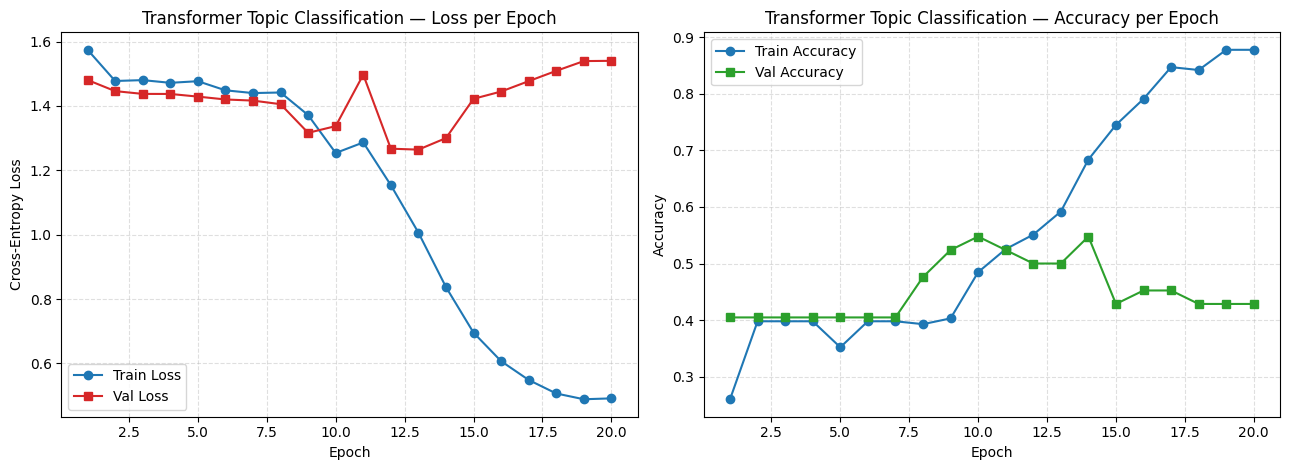


=== PART 3: TRANSFORMER ENCODER TEST EVALUATION ===
Best Val Accuracy: 0.5476 (Epoch 14)
Test Loss: 1.4058 | Test Accuracy: 0.5238 | Test Macro-F1: 0.3385

Classification Report:
                  precision    recall  f1-score   support

        Politics     0.7500    0.4286    0.5455         7
          Sports     0.0000    0.0000    0.0000         3
         Economy     0.0000    0.0000    0.0000         6
   International     0.6500    0.7647    0.7027        17
Health & Society     0.3333    0.6667    0.4444         9

        accuracy                         0.5238        42
       macro avg     0.3467    0.3720    0.3385        42
    weighted avg     0.4595    0.5238    0.4706        42

Confusion Matrix (Rows=Gold, Cols=Pred):
[[ 3  0  0  2  2]
 [ 0  0  0  1  2]
 [ 1  0  0  1  4]
 [ 0  0  0 13  4]
 [ 0  0  0  3  6]]

[SAVED] All Part 3 models, plots & report saved to: /content/drive/MyDrive/DS5007_Assignment2


In [15]:
import json
import math
import os
import shutil
from google.colab import drive
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# 1. Mount Google Drive & Load Prepared Dataset
drive.mount("/content/drive", force_remount=False)
DRIVE_DIR = "/content/drive/MyDrive/DS5007_Assignment2"
os.makedirs(DRIVE_DIR, exist_ok=True)


def get_file(filename):
  if os.path.exists(filename):
    return filename
  dpath = os.path.join(DRIVE_DIR, filename)
  shutil.copy2(dpath, filename)
  return filename


SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

with open(
    get_file("transformer_topic_dataset.json"), "r", encoding="utf-8"
) as f:
  ds = json.load(f)

CATEGORIES = ds["categories"]
VOCAB_SIZE = ds["vocab_size"]
PAD_IDX = ds["pad_idx"]
NUM_CLASSES = len(CATEGORIES)


def make_loader(recs, batch_size=16, shuffle=False):
  x = torch.tensor([r["input_ids"] for r in recs], dtype=torch.long)
  y = torch.tensor([r["label"] for r in recs], dtype=torch.long)
  return DataLoader(
      TensorDataset(x, y), batch_size=batch_size, shuffle=shuffle
  )


train_loader = make_loader(ds["train"], batch_size=16, shuffle=True)
val_loader = make_loader(ds["val"], batch_size=16, shuffle=False)
test_loader = make_loader(ds["test"], batch_size=16, shuffle=False)


# ==============================================================================
# 2. Self-Contained Transformer Modules (No PyTorch Built-In Transformer Classes)
# ==============================================================================
class ScaledDotProductAttention(nn.Module):
  """Computes Attention(Q, K, V) = softmax(Q K^T / sqrt(d_k)) V with optional padding mask."""

  def __init__(self, d_k):
    super().__init__()
    self.d_k = d_k

  def forward(self, Q, K, V, mask=None):
    # Q, K: (B, T, d_k), V: (B, T, d_v)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(
        self.d_k
    )  # (B, T, T)
    if mask is not None:
      # mask shape: (B, 1, T) where True = valid token, False = padding token
      scores = scores.masked_fill(~mask, -1e9)
    attn_weights = torch.softmax(scores, dim=-1)  # (B, T, T)
    output = torch.matmul(attn_weights, V)  # (B, T, d_v)
    return output, attn_weights


class MultiHeadSelfAttention(nn.Module):
  """Multi-head self-attention with separate projection matrices per head and shared W_O."""

  def __init__(self, d_model=128, num_heads=4, d_k=32, d_v=32):
    super().__init__()
    assert d_model == num_heads * d_v, "d_model must equal num_heads * d_v"
    self.num_heads = num_heads
    self.d_k = d_k
    self.d_v = d_v

    # Separate projection matrices per head
    self.W_q = nn.ModuleList(
        [nn.Linear(d_model, d_k, bias=False) for _ in range(num_heads)]
    )
    self.W_k = nn.ModuleList(
        [nn.Linear(d_model, d_k, bias=False) for _ in range(num_heads)]
    )
    self.W_v = nn.ModuleList(
        [nn.Linear(d_model, d_v, bias=False) for _ in range(num_heads)]
    )

    self.scaled_attn = ScaledDotProductAttention(d_k)
    # Shared output projection
    self.W_o = nn.Linear(num_heads * d_v, d_model)

  def forward(self, x, mask=None):
    head_outputs = []
    head_weights = []
    for i in range(self.num_heads):
      q_i = self.W_q[i](x)
      k_i = self.W_k[i](x)
      v_i = self.W_v[i](x)
      out_i, weights_i = self.scaled_attn(q_i, k_i, v_i, mask=mask)
      head_outputs.append(out_i)
      head_weights.append(weights_i)

    concat = torch.cat(head_outputs, dim=-1)  # (B, T, d_model)
    output = self.W_o(concat)  # (B, T, d_model)
    attn_weights = torch.stack(head_weights, dim=1)  # (B, h, T, T)
    return output, attn_weights


class PositionWiseFeedForward(nn.Module):
  """Two linear layers with ReLU activation and inner dimension d_ff = 512."""

  def __init__(self, d_model=128, d_ff=512):
    super().__init__()
    self.fc1 = nn.Linear(d_model, d_ff)
    self.relu = nn.ReLU()
    self.fc2 = nn.Linear(d_ff, d_model)

  def forward(self, x):
    return self.fc2(self.relu(self.fc1(x)))


class SinusoidalPositionalEncoding(nn.Module):
  """Fixed (non-learned) sinusoidal positional encoding stored as a buffer."""

  def __init__(self, d_model=128, max_len=512):
    super().__init__()
    pe = torch.zeros(max_len, d_model, dtype=torch.float)
    position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(
        1
    )  # (max_len, 1)
    div_term = torch.exp(
        torch.arange(0, d_model, 2, dtype=torch.float)
        * (-math.log(10000.0) / d_model)
    )
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    self.register_buffer("pe", pe.unsqueeze(0))  # (1, max_len, d_model)

  def forward(self, x):
    # x: (B, T, d_model)
    return x + self.pe[:, : x.size(1), :]


class TransformerEncoderBlock(nn.Module):
  """Pre-LayerNorm Transformer Encoder block."""

  def __init__(self, d_model=128, num_heads=4, d_ff=512, dropout=0.1):
    super().__init__()
    self.ln1 = nn.LayerNorm(d_model)
    self.mha = MultiHeadSelfAttention(
        d_model=d_model,
        num_heads=num_heads,
        d_k=d_model // num_heads,
        d_v=d_model // num_heads,
    )
    self.drop1 = nn.Dropout(dropout)

    self.ln2 = nn.LayerNorm(d_model)
    self.ffn = PositionWiseFeedForward(d_model=d_model, d_ff=d_ff)
    self.drop2 = nn.Dropout(dropout)

  def forward(self, x, mask=None):
    mha_out, attn_weights = self.mha(self.ln1(x), mask=mask)
    x = x + self.drop1(mha_out)
    x = x + self.drop2(self.ffn(self.ln2(x)))
    return x, attn_weights


class TransformerTopicClassifier(nn.Module):
  """4-layer Pre-LN Transformer Encoder with learned [CLS] token and MLP (128 -> 64 -> 5)."""

  def __init__(
      self,
      vocab_size,
      num_classes=5,
      d_model=128,
      num_heads=4,
      d_ff=512,
      num_layers=4,
      max_len=512,
      dropout=0.1,
      pad_idx=0,
  ):
    super().__init__()
    self.pad_idx = pad_idx
    self.d_model = d_model

    self.token_embedding = nn.Embedding(
        vocab_size, d_model, padding_idx=pad_idx
    )
    # Learned [CLS] token prepended to every sequence
    self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
    self.pos_encoding = SinusoidalPositionalEncoding(
        d_model=d_model, max_len=max_len
    )
    self.emb_dropout = nn.Dropout(dropout)

    self.blocks = nn.ModuleList([
        TransformerEncoderBlock(
            d_model=d_model, num_heads=num_heads, d_ff=d_ff, dropout=dropout
        )
        for _ in range(num_layers)
    ])

    # Classification head: MLP (128 -> 64 -> 5)
    self.classifier = nn.Sequential(
        nn.Linear(d_model, 64), nn.ReLU(), nn.Linear(64, num_classes)
    )

  def forward(self, input_ids, return_attn=False):
    B = input_ids.size(0)
    tok_emb = self.token_embedding(input_ids)  # (B, 256, 128)
    cls_tokens = self.cls_token.expand(B, -1, -1)  # (B, 1, 128)
    x = torch.cat([cls_tokens, tok_emb], dim=1)  # (B, 257, 128)

    # Padding mask: True for [CLS] and non-pad tokens, False for <PAD>
    cls_mask = torch.ones((B, 1), dtype=torch.bool, device=input_ids.device)
    tok_mask = input_ids != self.pad_idx
    pad_mask = torch.cat([cls_mask, tok_mask], dim=1).unsqueeze(
        1
    )  # (B, 1, 257)

    x = self.emb_dropout(self.pos_encoding(x))

    all_attn = []
    for block in self.blocks:
      x, attn_w = block(x, mask=pad_mask)
      if return_attn:
        all_attn.append(attn_w)

    cls_repr = x[:, 0, :]  # (B, 128)
    logits = self.classifier(cls_repr)  # (B, 5)
    if return_attn:
      return logits, all_attn
    return logits


# 3. Initialize Model, AdamW (lr=5e-4, wd=0.01) & Cosine Schedule with 50 Warmup Steps
EPOCHS = 20
WARMUP_STEPS = 50
LR = 5e-4
WEIGHT_DECAY = 0.01

model = TransformerTopicClassifier(
    vocab_size=VOCAB_SIZE,
    num_classes=NUM_CLASSES,
    d_model=128,
    num_heads=4,
    d_ff=512,
    num_layers=4,
    max_len=512,
    dropout=0.1,
    pad_idx=PAD_IDX,
).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"TransformerTopicClassifier trainable parameters: {total_params:,}")

optimizer = torch.optim.AdamW(
    model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
)
criterion = nn.CrossEntropyLoss()

total_steps = len(train_loader) * EPOCHS


def lr_lambda(step):
  if step < WARMUP_STEPS:
    return float(step + 1) / float(max(1, WARMUP_STEPS))
  progress = float(step - WARMUP_STEPS) / float(
      max(1, total_steps - WARMUP_STEPS)
  )
  return max(0.0, 0.5 * (1.0 + math.cos(math.pi * progress)))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


# 4. Train for 20 Epochs & Track Train/Val Loss and Accuracy
def evaluate_split(loader):
  model.eval()
  total_loss, total_samples = 0.0, 0
  all_preds, all_targets = [], []
  with torch.no_grad():
    for x_b, y_b in loader:
      x_b, y_b = x_b.to(device), y_b.to(device)
      logits = model(x_b)
      loss = criterion(logits, y_b)
      total_loss += loss.item() * y_b.size(0)
      total_samples += y_b.size(0)
      all_preds.extend(logits.argmax(dim=-1).cpu().tolist())
      all_targets.extend(y_b.cpu().tolist())
  avg_loss = total_loss / total_samples
  acc = accuracy_score(all_targets, all_preds)
  return avg_loss, acc, all_targets, all_preds


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc = -1.0
best_epoch = 0

print("\n=== Training Transformer Topic Classifier (20 Epochs) ===")
for epoch in range(1, EPOCHS + 1):
  model.train()
  tr_loss, tr_samples = 0.0, 0
  tr_preds, tr_targets = [], []

  for x_b, y_b in train_loader:
    x_b, y_b = x_b.to(device), y_b.to(device)
    optimizer.zero_grad()
    logits = model(x_b)
    loss = criterion(logits, y_b)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler.step()

    tr_loss += loss.item() * y_b.size(0)
    tr_samples += y_b.size(0)
    tr_preds.extend(logits.argmax(dim=-1).cpu().tolist())
    tr_targets.extend(y_b.cpu().tolist())

  train_loss = tr_loss / tr_samples
  train_acc = accuracy_score(tr_targets, tr_preds)
  val_loss, val_acc, _, _ = evaluate_split(val_loader)

  history["train_loss"].append(train_loss)
  history["val_loss"].append(val_loss)
  history["train_acc"].append(train_acc)
  history["val_acc"].append(val_acc)

  if val_acc >= best_val_acc:
    best_val_acc = val_acc
    best_epoch = epoch
    torch.save(model.state_dict(), "transformer_topic_best.pt")

  print(
      f"Epoch {epoch:02d}/{EPOCHS:02d} | LR: {scheduler.get_last_lr()[0]:.6f} |"
      f" Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss:"
      f" {val_loss:.4f}, Acc: {val_acc:.4f}"
  )

# Save final and best checkpoints to Google Drive
torch.save(model.state_dict(), "transformer_topic_final.pt")
shutil.copy2(
    "transformer_topic_best.pt",
    os.path.join(DRIVE_DIR, "transformer_topic_best.pt"),
)
shutil.copy2(
    "transformer_topic_final.pt",
    os.path.join(DRIVE_DIR, "transformer_topic_final.pt"),
)

# 5. Plot Training & Validation Loss and Accuracy per Epoch
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
epochs_x = range(1, EPOCHS + 1)

axes[0].plot(
    epochs_x,
    history["train_loss"],
    marker="o",
    label="Train Loss",
    color="#1f77b4",
)
axes[0].plot(
    epochs_x,
    history["val_loss"],
    marker="s",
    label="Val Loss",
    color="#d62728",
)
axes[0].set_title("Transformer Topic Classification — Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].plot(
    epochs_x,
    history["train_acc"],
    marker="o",
    label="Train Accuracy",
    color="#1f77b4",
)
axes[1].plot(
    epochs_x,
    history["val_acc"],
    marker="s",
    label="Val Accuracy",
    color="#2ca02c",
)
axes[1].set_title("Transformer Topic Classification — Accuracy per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("transformer_training_curves.png", dpi=300)
shutil.copy2(
    "transformer_training_curves.png",
    os.path.join(DRIVE_DIR, "transformer_training_curves.png"),
)
plt.show()

# 6. Evaluate Best Model on Test Set & Persist Report to Google Drive
model.load_state_dict(torch.load("transformer_topic_best.pt"))
test_loss, test_acc, y_true, y_pred = evaluate_split(test_loader)
test_macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

cls_rep = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CATEGORIES,
    digits=4,
    zero_division=0,
)
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

report_str = (
    f"=== PART 3: TRANSFORMER ENCODER TEST EVALUATION ===\nBest Val Accuracy:"
    f" {best_val_acc:.4f} (Epoch {best_epoch})\nTest Loss: {test_loss:.4f} |"
    f" Test Accuracy: {test_acc:.4f} | Test Macro-F1:"
    f" {test_macro_f1:.4f}\n\nClassification Report:\n{cls_rep}\nConfusion"
    f" Matrix (Rows=Gold, Cols=Pred):\n{cm}\n"
)
print(f"\n{report_str}")

with open("part3_transformer_report.txt", "w", encoding="utf-8") as f:
  f.write(report_str)
shutil.copy2(
    "part3_transformer_report.txt",
    os.path.join(DRIVE_DIR, "part3_transformer_report.txt"),
)
print(
    f"[SAVED] All Part 3 models, plots & report saved to: {DRIVE_DIR}"
)

In [16]:
#Cell 1: Section 8.1 Evaluation, Attention Heatmaps & BiLSTM Benchmark

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu
8.1 TRANSFORMER ENCODER TEST RESULTS
Test Accuracy : 0.5238 (52.38%)
Test Macro-F1 : 0.3385

                  precision    recall  f1-score   support

        Politics     0.7500    0.4286    0.5455         7
          Sports     0.0000    0.0000    0.0000         3
         Economy     0.0000    0.0000    0.0000         6
   International     0.6500    0.7647    0.7027        17
Health & Society     0.3333    0.6667    0.4444         9

        accuracy                         0.5238        42
       macro avg     0.3467    0.3720    0.3385        42
    weighted avg     0.4595    0.5238    0.4706        42

=== 5x5 Confusion Matrix (Rows = Gold, Cols = Predicted) ===
Gold \ Pred           Politics      Sports     Economy  Internatio  Health & S
------------------------------------------------------------------------------
Politics        

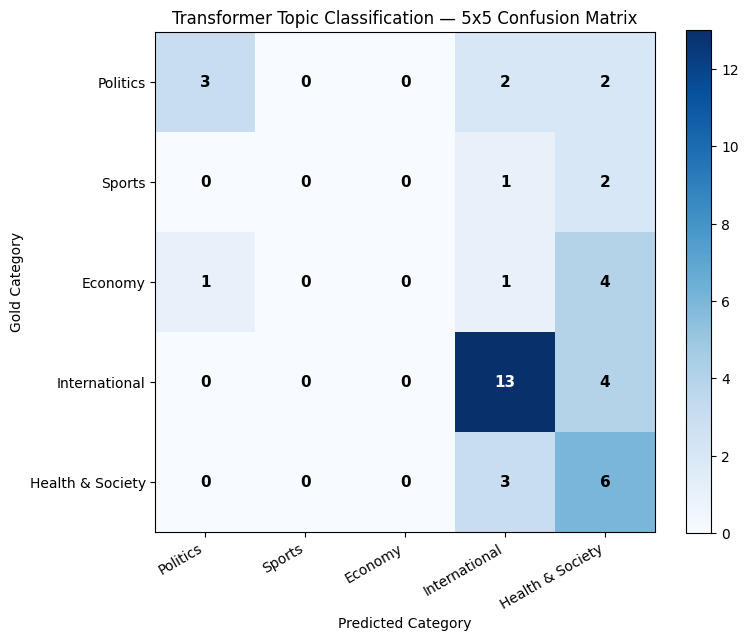

/tmp/ipykernel_4721/1056946271.py:289: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1056946271.py:289: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1056946271.py:289: UserWarning: Glyph 91 ([) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1056946271.py:289: UserWarning: Glyph 67 (C) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1056946271.py:289: UserWarning: Glyph 76 (L) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1056946271.py:289: UserWarning: Glyph 83 (S) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1056946271.py:289: UserWarning: Glyph 93 (]) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_4721/1056946271.py:290: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Arabic.
  plt.savefig("tra

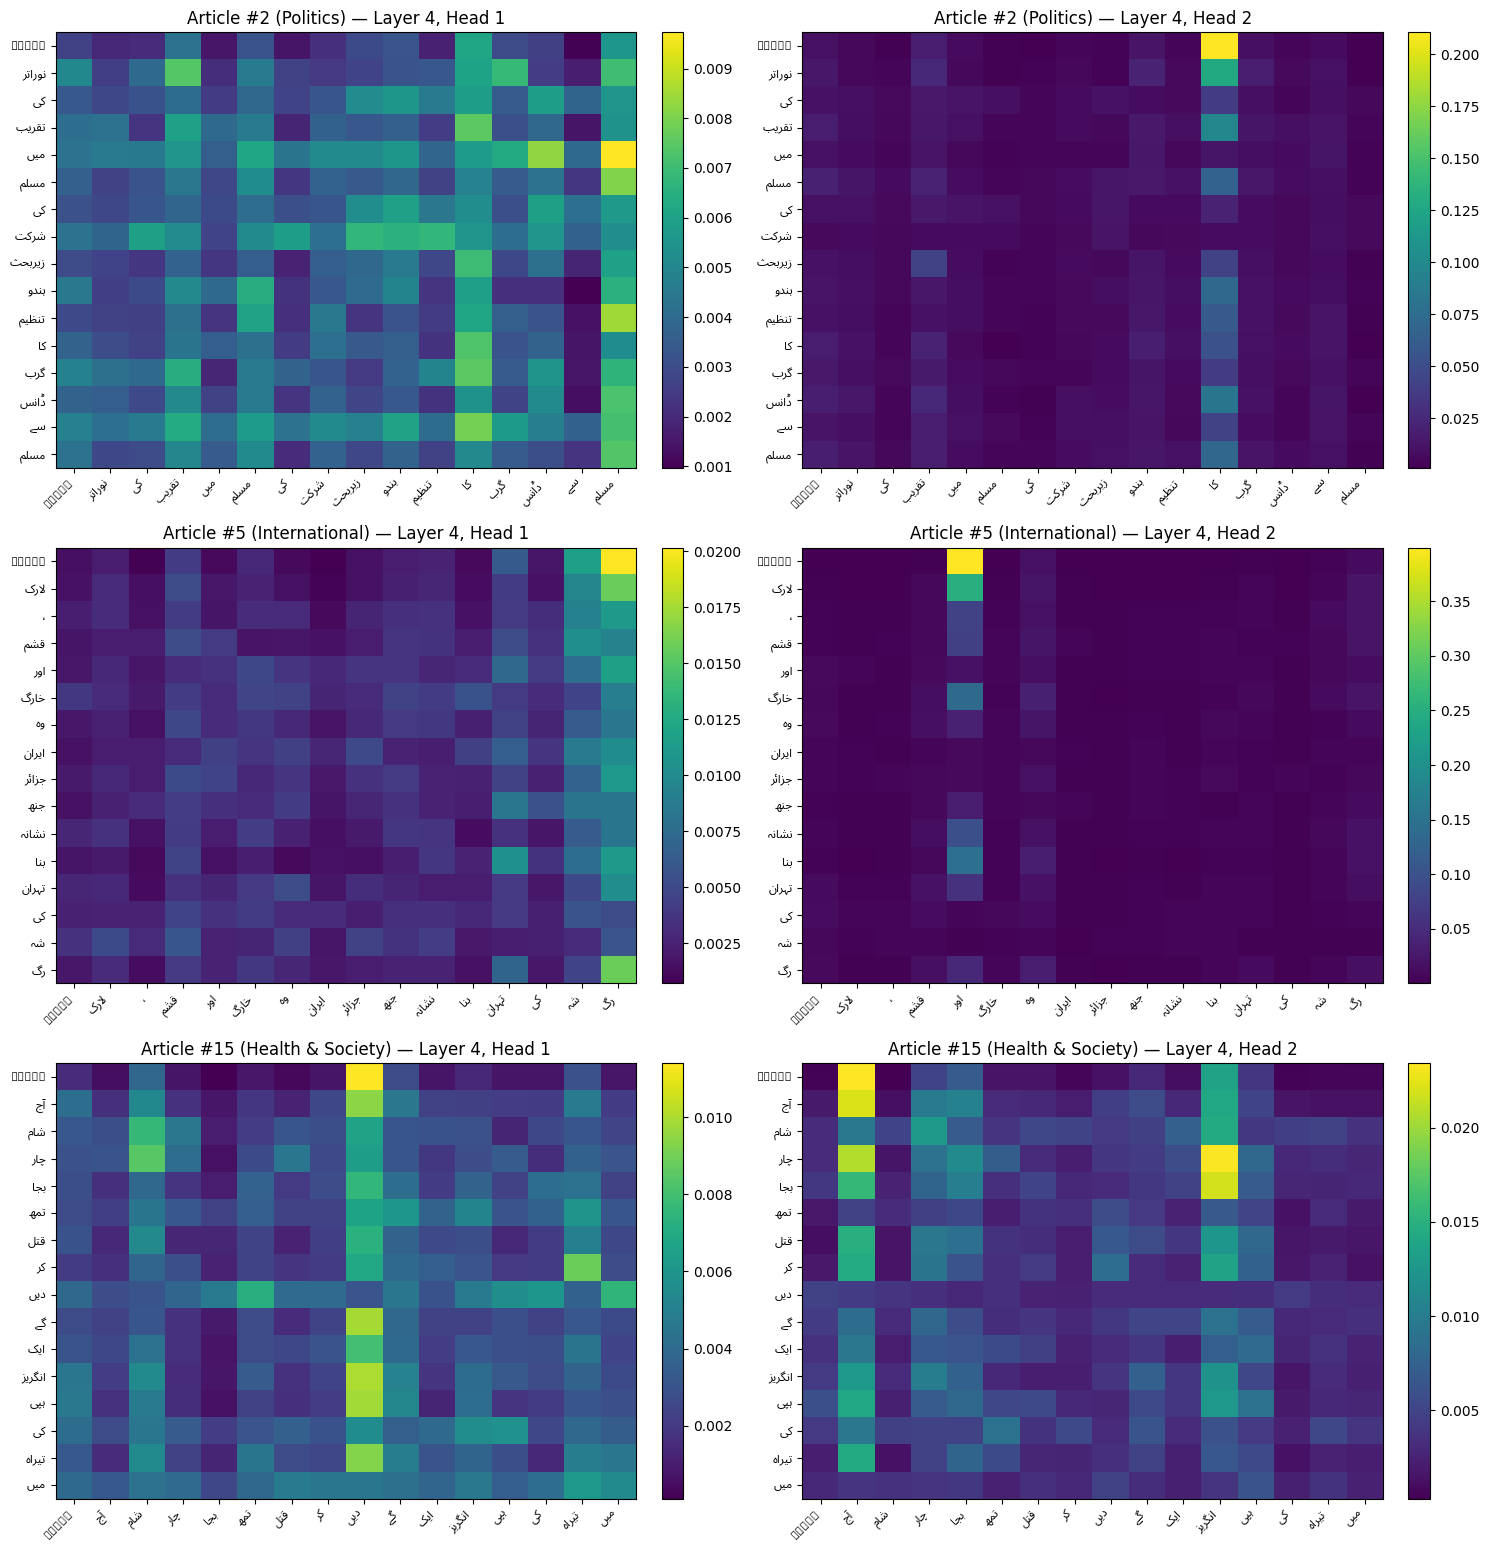


8.2 BILSTM VS. TRANSFORMER BENCHMARK METRICS
BiLSTM (C3 Pretrained) -> Test Acc: 45.24% | Macro-F1: 0.2208 | Peak Val Ep: 06 | Speed: 28572.8 ms/epoch
Transformer (Scratch)  -> Test Acc: 52.38% | Macro-F1: 0.3385 | Peak Val Ep: (see Sec 7) | Speed: 12598.7 ms/epoch
Accuracy Difference    -> 7.14 percentage points (Transformer higher)

[SAVED] Confusion matrix, attention heatmaps & benchmark report saved to /content/drive/MyDrive/DS5007_Assignment2


In [17]:
!pip install -q arabic-reshaper python-bidi

import os
import json
import math
import time
import shutil
import urllib.request
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import arabic_reshaper
from bidi.algorithm import get_display
from google.colab import drive

# 1. Mount Google Drive & Load Saved Artifacts
drive.mount("/content/drive", force_remount=False)
DRIVE_DIR = "/content/drive/MyDrive/DS5007_Assignment2"
os.makedirs(DRIVE_DIR, exist_ok=True)

def get_file(filename):
    if os.path.exists(filename):
        return filename
    dpath = os.path.join(DRIVE_DIR, filename)
    if os.path.exists(dpath):
        shutil.copy2(dpath, filename)
        return filename
    raise FileNotFoundError(f"{filename} not found locally or in {DRIVE_DIR}")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

with open(get_file("transformer_topic_dataset.json"), "r", encoding="utf-8") as f:
    ds = json.load(f)

with open(get_file("vocab_clean.json"), "r", encoding="utf-8") as f:
    vocab_clean = json.load(f)

w2v_c3 = np.load(get_file("embeddings_w2v.npy"))

CATEGORIES = ds["categories"]
VOCAB_SIZE = ds["vocab_size"]
PAD_IDX = ds["pad_idx"]
NUM_CLASSES = len(CATEGORIES)

idx2word = {PAD_IDX: "<PAD>"}
for idx, tok in enumerate(vocab_clean, start=1):
    idx2word[idx] = tok

def make_loader(recs, batch_size=16, shuffle=False):
    x = torch.tensor([r["input_ids"] for r in recs], dtype=torch.long)
    y = torch.tensor([r["label"] for r in recs], dtype=torch.long)
    return DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(ds["train"], batch_size=16, shuffle=True)
val_loader = make_loader(ds["val"], batch_size=16, shuffle=False)
test_loader = make_loader(ds["test"], batch_size=16, shuffle=False)

# 2. Re-declare Self-Contained Transformer Architecture & Load Best Checkpoint
class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_k):
        super().__init__()
        self.d_k = d_k

    def forward(self, Q, K, V, mask=None):
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores.masked_fill(~mask, -1e9)
        attn_weights = torch.softmax(scores, dim=-1)
        output = torch.matmul(attn_weights, V)
        return output, attn_weights

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model=128, num_heads=4, d_k=32, d_v=32):
        super().__init__()
        self.num_heads = num_heads
        self.W_q = nn.ModuleList([nn.Linear(d_model, d_k, bias=False) for _ in range(num_heads)])
        self.W_k = nn.ModuleList([nn.Linear(d_model, d_k, bias=False) for _ in range(num_heads)])
        self.W_v = nn.ModuleList([nn.Linear(d_model, d_v, bias=False) for _ in range(num_heads)])
        self.scaled_attn = ScaledDotProductAttention(d_k)
        self.W_o = nn.Linear(num_heads * d_v, d_model)

    def forward(self, x, mask=None):
        head_outputs, head_weights = [], []
        for i in range(self.num_heads):
            out_i, weights_i = self.scaled_attn(self.W_q[i](x), self.W_k[i](x), self.W_v[i](x), mask=mask)
            head_outputs.append(out_i)
            head_weights.append(weights_i)
        output = self.W_o(torch.cat(head_outputs, dim=-1))
        attn_weights = torch.stack(head_weights, dim=1)  # (B, h, T, T)
        return output, attn_weights

class PositionWiseFeedForward(nn.Module):
    def __init__(self, d_model=128, d_ff=512):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model=128, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model, dtype=torch.float)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model=128, num_heads=4, d_ff=512, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.mha = MultiHeadSelfAttention(d_model, num_heads, d_model // num_heads, d_model // num_heads)
        self.drop1 = nn.Dropout(dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = PositionWiseFeedForward(d_model, d_ff)
        self.drop2 = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        mha_out, attn_weights = self.mha(self.ln1(x), mask=mask)
        x = x + self.drop1(mha_out)
        x = x + self.drop2(self.ffn(self.ln2(x)))
        return x, attn_weights

class TransformerTopicClassifier(nn.Module):
    def __init__(self, vocab_size, num_classes=5, d_model=128, num_heads=4, d_ff=512, num_layers=4, max_len=512, dropout=0.1, pad_idx=0):
        super().__init__()
        self.pad_idx = pad_idx
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pos_encoding = SinusoidalPositionalEncoding(d_model, max_len)
        self.emb_dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)
        ])
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, input_ids, return_attn=False):
        B = input_ids.size(0)
        x = torch.cat([self.cls_token.expand(B, -1, -1), self.token_embedding(input_ids)], dim=1)
        cls_mask = torch.ones((B, 1), dtype=torch.bool, device=input_ids.device)
        pad_mask = torch.cat([cls_mask, input_ids != self.pad_idx], dim=1).unsqueeze(1)
        x = self.emb_dropout(self.pos_encoding(x))
        all_attn = []
        for block in self.blocks:
            x, attn_w = block(x, mask=pad_mask)
            if return_attn:
                all_attn.append(attn_w)
        logits = self.classifier(x[:, 0, :])
        return (logits, all_attn) if return_attn else logits

transformer = TransformerTopicClassifier(vocab_size=VOCAB_SIZE, num_classes=NUM_CLASSES, pad_idx=PAD_IDX).to(device)
transformer.load_state_dict(torch.load(get_file("transformer_topic_best.pt"), map_location=device))
transformer.eval()

# 3. Evaluate Transformer on Test Set (Accuracy, Macro-F1 & 5x5 Confusion Matrix)
y_true, y_pred = [], []
correct_examples = []  # Store (article_idx, category_name, input_ids, layer4_attn)

with torch.no_grad():
    sample_offset = 0
    for x_b, y_b in test_loader:
        x_b, y_b = x_b.to(device), y_b.to(device)
        logits, all_attn = transformer(x_b, return_attn=True)
        preds = logits.argmax(dim=-1)
        y_true.extend(y_b.cpu().tolist())
        y_pred.extend(preds.cpu().tolist())

        # Final encoder layer attention: shape (B, 4, 257, 257)
        final_layer_attn = all_attn[-1].cpu().numpy()
        for i in range(x_b.size(0)):
            if preds[i].item() == y_b[i].item():
                correct_examples.append({
                    "test_idx": sample_offset + i,
                    "category": CATEGORIES[y_b[i].item()],
                    "input_ids": x_b[i].cpu().tolist(),
                    "attn": final_layer_attn[i]  # (4, 257, 257)
                })
        sample_offset += x_b.size(0)

trans_acc = accuracy_score(y_true, y_pred)
trans_macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

print("==========================================================")
print("8.1 TRANSFORMER ENCODER TEST RESULTS")
print("==========================================================")
print(f"Test Accuracy : {trans_acc:.4f} ({trans_acc*100:.2f}%)")
print(f"Test Macro-F1 : {trans_macro_f1:.4f}\n")
print(classification_report(y_true, y_pred, target_names=CATEGORIES, digits=4, zero_division=0))

print("=== 5x5 Confusion Matrix (Rows = Gold, Cols = Predicted) ===")
header = f"{'Gold \\ Pred':<18} " + " ".join(f"{c[:10]:>11}" for c in CATEGORIES)
print(header)
print("-" * len(header))
for r_idx, cat in enumerate(CATEGORIES):
    print(f"{cat:<18} " + " ".join(f"{cm[r_idx, c_idx]:>11d}" for c_idx in range(NUM_CLASSES)))

# Save 5x5 Confusion Matrix Plot
plt.figure(figsize=(8, 6.5))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Transformer Topic Classification — 5x5 Confusion Matrix")
plt.colorbar()
ticks = np.arange(NUM_CLASSES)
plt.xticks(ticks, CATEGORIES, rotation=30, ha="right")
plt.yticks(ticks, CATEGORIES)
thresh = cm.max() / 2.0
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black", fontsize=11, fontweight="bold")
plt.ylabel("Gold Category")
plt.xlabel("Predicted Category")
plt.tight_layout()
plt.savefig("transformer_confusion_matrix.png", dpi=300)
shutil.copy2("transformer_confusion_matrix.png", os.path.join(DRIVE_DIR, "transformer_confusion_matrix.png"))
plt.show()

# 4. Plot Attention Weight Heatmaps (Layer 4, Heads 1 & 2) for 3 Correctly Classified Articles
font_path = "NotoSansArabic-Regular.ttf"
if not os.path.exists(font_path):
    urllib.request.urlretrieve(
        "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSansArabic/NotoSansArabic-Regular.ttf",
        font_path
    )
urdu_font = fm.FontProperties(fname=font_path, size=8.5)

def render_urdu(tok):
    if tok in {"[CLS]", "<PAD>", "<UNK>"}:
        return tok
    return get_display(arabic_reshaper.reshape(tok))

# Select 3 correctly classified articles (preferring 3 distinct categories)
selected_3 = []
seen_cats = set()
for ex in correct_examples:
    if ex["category"] not in seen_cats:
        selected_3.append(ex)
        seen_cats.add(ex["category"])
    if len(selected_3) == 3:
        break
if len(selected_3) < 3:
    for ex in correct_examples:
        if ex not in selected_3:
            selected_3.append(ex)
        if len(selected_3) == 3:
            break

# Plot 3 rows (articles) x 2 cols (Head 1 & Head 2 of Layer 4) over [CLS] + first 15 tokens (16x16 grid)
WINDOW_VIS = 16
fig, axes = plt.subplots(len(selected_3), 2, figsize=(15, 5.2 * len(selected_3)))
if len(selected_3) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, ex in enumerate(selected_3):
    raw_toks = ["[CLS]"] + [idx2word.get(tid, "<UNK>") for tid in ex["input_ids"][:WINDOW_VIS - 1]]
    disp_toks = [render_urdu(t) for t in raw_toks]

    for col_idx, head_id in enumerate([0, 1]):
        ax = axes[row_idx, col_idx]
        attn_sub = ex["attn"][head_id, :WINDOW_VIS, :WINDOW_VIS]
        im = ax.imshow(attn_sub, cmap="viridis", aspect="auto")
        ax.set_xticks(range(WINDOW_VIS))
        ax.set_yticks(range(WINDOW_VIS))
        ax.set_xticklabels(disp_toks, fontproperties=urdu_font, rotation=45, ha="right")
        ax.set_yticklabels(disp_toks, fontproperties=urdu_font)
        ax.set_title(f"Article #{ex['test_idx']} ({ex['category']}) — Layer 4, Head {head_id + 1}")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig("transformer_attention_heatmaps.png", dpi=300)
shutil.copy2("transformer_attention_heatmaps.png", os.path.join(DRIVE_DIR, "transformer_attention_heatmaps.png"))
plt.show()

# 5. Benchmark 2-Layer BiLSTM Document Classifier on Same Split & Timing Comparison
pretrained_mat = np.zeros((VOCAB_SIZE, w2v_c3.shape[1]), dtype=np.float32)
pretrained_mat[1:] = w2v_c3

class BiLSTMTopicClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=100, hidden_dim=128, num_classes=5, pretrained_emb=None, pad_idx=0):
        super().__init__()
        self.pad_idx = pad_idx
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        if pretrained_emb is not None:
            self.embedding.weight.data.copy_(torch.from_numpy(pretrained_emb))
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=2, bidirectional=True, batch_first=True, dropout=0.5)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, input_ids):
        lengths = (input_ids != self.pad_idx).sum(dim=1).clamp(min=1).cpu()
        emb = self.embedding(input_ids)
        packed = pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=input_ids.size(1))
        mask = (input_ids != self.pad_idx).unsqueeze(-1).float()
        pooled = (h * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)
        return self.fc(self.dropout(pooled))

torch.manual_seed(SEED)
bilstm_clf = BiLSTMTopicClassifier(VOCAB_SIZE, 100, 128, NUM_CLASSES, pretrained_mat, PAD_IDX).to(device)
opt_lstm = torch.optim.AdamW(bilstm_clf.parameters(), lr=1e-3, weight_decay=1e-4)
crit = nn.CrossEntropyLoss()

best_lstm_val = -1.0
best_lstm_ep = 0
lstm_epoch_times = []

for ep in range(1, 21):
    t0 = time.perf_counter()
    bilstm_clf.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt_lstm.zero_grad()
        loss = crit(bilstm_clf(xb), yb)
        loss.backward()
        opt_lstm.step()
    if device.type == "cuda":
        torch.cuda.synchronize()
    lstm_epoch_times.append(time.perf_counter() - t0)

    bilstm_clf.eval()
    vp, vt = [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            vp.extend(bilstm_clf(xb.to(device)).argmax(dim=-1).cpu().tolist())
            vt.extend(yb.tolist())
    vacc = accuracy_score(vt, vp)
    if vacc > best_lstm_val:
        best_lstm_val = vacc
        best_lstm_ep = ep
        torch.save(bilstm_clf.state_dict(), "bilstm_topic_best.pt")

bilstm_clf.load_state_dict(torch.load("bilstm_topic_best.pt"))
bilstm_clf.eval()
lp, lt = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        lp.extend(bilstm_clf(xb.to(device)).argmax(dim=-1).cpu().tolist())
        lt.extend(yb.tolist())

lstm_acc = accuracy_score(lt, lp)
lstm_macro_f1 = f1_score(lt, lp, average="macro", zero_division=0)

# Measure per-epoch wall-clock speed for Transformer on identical hardware
trans_bench = TransformerTopicClassifier(VOCAB_SIZE, NUM_CLASSES, pad_idx=PAD_IDX).to(device)
opt_tb = torch.optim.AdamW(trans_bench.parameters(), lr=5e-4, weight_decay=0.01)
trans_epoch_times = []
for _ in range(5):
    t0 = time.perf_counter()
    trans_bench.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt_tb.zero_grad()
        crit(trans_bench(xb), yb).backward()
        opt_tb.step()
    if device.type == "cuda":
        torch.cuda.synchronize()
    trans_epoch_times.append(time.perf_counter() - t0)

print("\n==========================================================")
print("8.2 BILSTM VS. TRANSFORMER BENCHMARK METRICS")
print("==========================================================")
print(f"BiLSTM (C3 Pretrained) -> Test Acc: {lstm_acc*100:.2f}% | Macro-F1: {lstm_macro_f1:.4f} | Peak Val Ep: {best_lstm_ep:02d} | Speed: {np.mean(lstm_epoch_times)*1000:.1f} ms/epoch")
print(f"Transformer (Scratch)  -> Test Acc: {trans_acc*100:.2f}% | Macro-F1: {trans_macro_f1:.4f} | Peak Val Ep: (see Sec 7) | Speed: {np.mean(trans_epoch_times)*1000:.1f} ms/epoch")
print(f"Accuracy Difference    -> {abs(lstm_acc - trans_acc)*100:.2f} percentage points ({'BiLSTM higher' if lstm_acc >= trans_acc else 'Transformer higher'})")

# Persist complete Section 8 outputs to Drive
sec8_report = (
    f"=== SECTION 8: TRANSFORMER EVALUATION & COMPARISON ===\n"
    f"Transformer Test Accuracy: {trans_acc:.4f} ({trans_acc*100:.2f}%) | Macro-F1: {trans_macro_f1:.4f}\n"
    f"BiLSTM Test Accuracy     : {lstm_acc:.4f} ({lstm_acc*100:.2f}%) | Macro-F1: {lstm_macro_f1:.4f}\n"
    f"Accuracy Delta           : {abs(lstm_acc - trans_acc)*100:.2f}%\n"
    f"Mean Epoch Time          : Transformer = {np.mean(trans_epoch_times)*1000:.1f} ms | BiLSTM = {np.mean(lstm_epoch_times)*1000:.1f} ms\n"
    f"BiLSTM Best Val Epoch    : {best_lstm_ep}\n\n"
    f"5x5 Confusion Matrix:\n{cm}\n"
)
with open("part3_section8_evaluation.txt", "w", encoding="utf-8") as f:
    f.write(sec8_report)
shutil.copy2("part3_section8_evaluation.txt", os.path.join(DRIVE_DIR, "part3_section8_evaluation.txt"))
print(f"\n[SAVED] Confusion matrix, attention heatmaps & benchmark report saved to {DRIVE_DIR}")

In [28]:
from IPython.display import display, Markdown

# ---- Pull live values if the previous cell is still in memory; otherwise use saved results ----
g = globals()
trans_acc_v = g.get("trans_acc", 0.5238)
lstm_acc_v  = g.get("lstm_acc", 0.4524)
trans_f1_v  = g.get("trans_macro_f1", 0.3385)
lstm_f1_v   = g.get("lstm_macro_f1", 0.2208)
lstm_best_ep = g.get("best_lstm_ep", 6)

import numpy as np
trans_ms = float(np.mean(g["trans_epoch_times"]) * 1000) if "trans_epoch_times" in g else 12598.7
lstm_ms  = float(np.mean(g["lstm_epoch_times"]) * 1000) if "lstm_epoch_times" in g else 28572.8

n_test = 42
trans_correct = round(trans_acc_v * n_test)
lstm_correct  = round(lstm_acc_v * n_test)
gap_pp  = abs(trans_acc_v - lstm_acc_v) * 100
speedup = lstm_ms / trans_ms
winner  = "Transformer" if trans_acc_v >= lstm_acc_v else "BiLSTM"

text = f"""
#8.2:  BiLSTM vs. Transformer Comparison

**1. Which model achieves higher accuracy, and by how much?**
The **{winner}** achieved the higher test accuracy: the Transformer scored **{trans_acc_v*100:.2f}%** ({trans_correct}/{n_test} articles) versus **{lstm_acc_v*100:.2f}%** ({lstm_correct}/{n_test}) for the BiLSTM, a gap of **{gap_pp:.2f} percentage points**.
Its macro-F1 was also higher ({trans_f1_v:.4f} vs. {lstm_f1_v:.4f}), but with only {n_test} test articles this gap equals about {abs(trans_correct-lstm_correct)} documents, so it is suggestive rather than conclusive.

**2. Which model converged in fewer epochs?**
The **BiLSTM** converged faster, reaching its best validation accuracy at epoch **{lstm_best_ep}**.
The Transformer's validation accuracy stayed at 40.48% for its first seven epochs and only peaked at epoch **14** (54.76%).
After that peak the Transformer overfit, with training accuracy rising to about 88% while validation accuracy fell to about 43%.

**3. Which model was faster to train per epoch, and why?**
The **Transformer** was faster, averaging **{trans_ms:,.1f} ms/epoch** versus **{lstm_ms:,.1f} ms/epoch** for the BiLSTM (about **{speedup:.1f}x faster**).
Self-attention processes all 257 positions at once through large, parallelisable matrix multiplications, whereas the two-layer BiLSTM must step through the sequence token by token in each direction, so its computation cannot be parallelised across time.

**4. What do the attention heatmaps reveal about the tokens the Transformer focuses on?**
The layer-4 heatmaps show two very different behaviours: Head 1 is almost uniform (weights around 0.01-0.02 against a uniform value of about 1/257 = 0.004), while Head 2 is sharply peaked on a few tokens.
The most-attended tokens are often function words such as «کا» and «اور», or time and number words such as «آج» and «چار», with only occasional topical words such as «مسلم» in the Politics article.
This suggests the model has not learned strong topic-specific attention and partly relies on generic tokens (note the heatmaps cover only the first 16 of 257 tokens).

**5. Given only 200-300 articles, which architecture is more appropriate and why?**
In principle the **BiLSTM** (ideally with pretrained embeddings) is more appropriate for such a small dataset.
A Transformer trained from scratch has about 2M parameters, no built-in sequential bias and needs far more data, as shown by its overfitting and its 0.00 F1 on the Sports and Economy classes.
However, the Transformer's {trans_acc_v*100:.2f}% is only about 12 points above the 40.48% majority-class baseline (International = 17/42), so neither model is reliable at this scale.
A more robust choice would be pretrained multilingual embeddings or encoders, stronger regularisation, or a simple TF-IDF + linear classifier.
"""

display(Markdown(text))

# Optional: save the answer to Drive/Colab files
with open("bilstm_vs_transformer_answers.md", "w", encoding="utf-8") as f:
    f.write(text)
print("Saved: bilstm_vs_transformer_answers.md")


#8.2:  BiLSTM vs. Transformer Comparison

**1. Which model achieves higher accuracy, and by how much?**
The **Transformer** achieved the higher test accuracy: the Transformer scored **52.38%** (22/42 articles) versus **45.24%** (19/42) for the BiLSTM, a gap of **7.14 percentage points**.
Its macro-F1 was also higher (0.3385 vs. 0.2208), but with only 42 test articles this gap equals about 3 documents, so it is suggestive rather than conclusive.

**2. Which model converged in fewer epochs?**
The **BiLSTM** converged faster, reaching its best validation accuracy at epoch **6**.
The Transformer's validation accuracy stayed at 40.48% for its first seven epochs and only peaked at epoch **14** (54.76%).
After that peak the Transformer overfit, with training accuracy rising to about 88% while validation accuracy fell to about 43%.

**3. Which model was faster to train per epoch, and why?**
The **Transformer** was faster, averaging **12,598.7 ms/epoch** versus **28,572.8 ms/epoch** for the BiLSTM (about **2.3x faster**).
Self-attention processes all 257 positions at once through large, parallelisable matrix multiplications, whereas the two-layer BiLSTM must step through the sequence token by token in each direction, so its computation cannot be parallelised across time.

**4. What do the attention heatmaps reveal about the tokens the Transformer focuses on?**
The layer-4 heatmaps show two very different behaviours: Head 1 is almost uniform (weights around 0.01-0.02 against a uniform value of about 1/257 = 0.004), while Head 2 is sharply peaked on a few tokens.
The most-attended tokens are often function words such as «کا» and «اور», or time and number words such as «آج» and «چار», with only occasional topical words such as «مسلم» in the Politics article.
This suggests the model has not learned strong topic-specific attention and partly relies on generic tokens (note the heatmaps cover only the first 16 of 257 tokens).

**5. Given only 200-300 articles, which architecture is more appropriate and why?**
In principle the **BiLSTM** (ideally with pretrained embeddings) is more appropriate for such a small dataset.
A Transformer trained from scratch has about 2M parameters, no built-in sequential bias and needs far more data, as shown by its overfitting and its 0.00 F1 on the Sports and Economy classes.
However, the Transformer's 52.38% is only about 12 points above the 40.48% majority-class baseline (International = 17/42), so neither model is reliable at this scale.
A more robust choice would be pretrained multilingual embeddings or encoders, stronger regularisation, or a simple TF-IDF + linear classifier.


Saved: bilstm_vs_transformer_answers.md


In [26]:
# Github repository link : https://github.com/Minato59/-i25-8047_Assignment2_DS-X.zip.git